In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import glob

from itertools import combinations
import sys
from statsmodels.stats.multitest import multipletests
from scipy.stats import norm
import os
import pickle

In [2]:
import helper_functions as hf

In [3]:
plt.rcParams.update({'font.size': 14})

## Figure 1 (kinetic model)

In [4]:
!mkdir figures

### A (kinetic model)

Rendered in latex

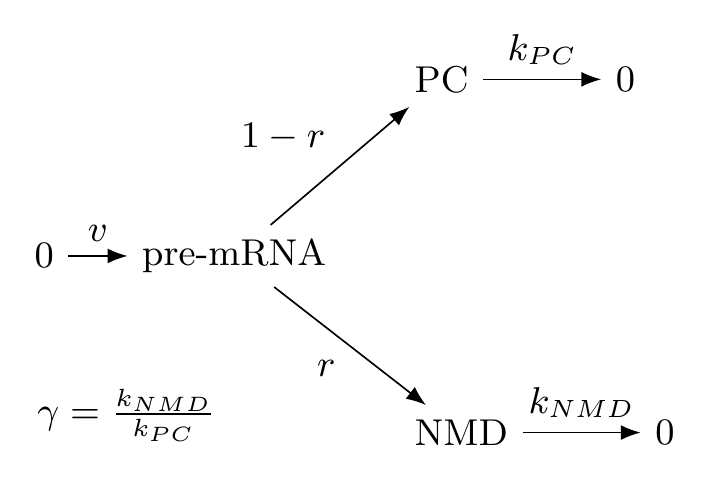

In [5]:
import subprocess
from pathlib import Path
from IPython.display import display, IFrame

tex_source = r"""
\documentclass[tikz,border=5pt]{standalone}
\usepackage{amsmath}
\usepackage{tikz}
\usetikzlibrary{positioning,arrows.meta,calc}

\begin{document}

\begin{tikzpicture}[
    node distance=1cm and 0.5cm,
    every node/.style={font=\small},
    >=Latex
]

\node (A) at (0,0) {0};
\node[right=of A] (B) {pre-mRNA};
\node[above right=of B] (C) {PC};
\node[below right=of B] (D) {NMD};
\node[right = 1cm of C] (E) {0};
\node[right = 1cm of D] (F) {0};



%\node (G) [below = of A] at ($(A) + (0.5, 0.5)$) {$\gamma = \frac{k_{NMD}}{k_{PC}}$};

\node (G) [below = of A] at ($(A) + (0.7, 0)$) {$\gamma = \frac{k_{NMD}}{k_{PC}}$};

\draw[->] (A) -- node[above] {$v$} (B);
\draw[->] (B) -- node[above left] {$1-r$} (C);
\draw[->] (B) -- node[below left] {$r$} (D);
\draw[->] (C) -- node[above] {$k_{PC}$} (E);
\draw[->] (D) -- node[above] {$k_{NMD}$} (F);


\end{tikzpicture}

\end{document}
"""

tex_path = Path('./figures/scheme.tex')

tex_path.write_text(tex_source, encoding="utf-8")

result = subprocess.run(
    [
        "pdflatex",
        "-interaction=nonstopmode",
        "-halt-on-error",
        tex_path.name
    ],
    cwd=tex_path.parent,
    capture_output=True,
    text=True
)

if result.returncode==0:

    from pdf2image import convert_from_path
    from IPython.display import display
    
    pages = convert_from_path("./figures/scheme.pdf", dpi=300)
    
    display(pages[0])
else:
    print(result.stderr)

### B (theoretical r = f(psi,gamma))

(-0.05, 1.05, -0.05, 1.05)

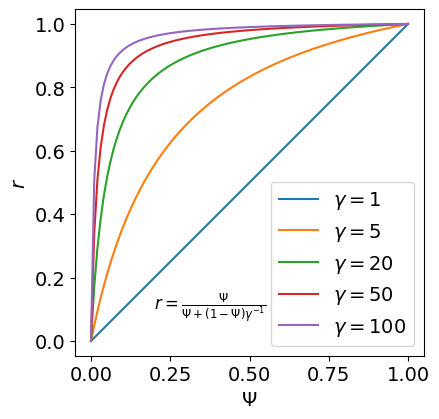

In [6]:
f,ax = plt.subplots(figsize=(4.5,4.5))
psi = np.linspace(0,1,100)
for gamma in [1,5,20,50,100]:
    r = hf.psi2r(psi,gamma)
    ax.plot(psi,r,label=f'$\gamma={gamma}$')
ax.legend()
ax.set_xlabel('$\Psi$')
ax.set_ylabel('$r$')
ax.text(0.2,0.1,r'$r = \frac{\Psi}{\Psi + (1-\Psi)\gamma^{-1}}$',fontsize=12)
ax.axis('equal')

In [7]:
f.savefig('./figures/r_from_psi_theory.pdf',bbox_inches='tight')

In [8]:
from pypdf import PdfReader, PdfWriter, PageObject

def merge_pdfs(pdf1, pdf2, out_pdf="merged.pdf"):
    reader1 = PdfReader(pdf1)
    reader2 = PdfReader(pdf2)

    # Берем первые страницы обоих документов
    page1 = reader1.pages[0]
    page2 = reader2.pages[0]

    # 1. Находим целевую (максимальную) высоту
    h1 = float(page1.mediabox.height)
    h2 = float(page2.mediabox.height)
    target_height = max(h1, h2)

    # 2. Масштабируем страницы по высоте с сохранением пропорций
    scale1 = target_height / h1
    page1.scale_by(scale1)
    
    scale2 = target_height / h2
    page2.scale_by(scale2)

    # 3. Получаем новую ширину страниц после масштабирования
    w1_new = float(page1.mediabox.width)
    w2_new = float(page2.mediabox.width)

    # Вычисляем итоговые размеры общего листа
    total_width = w1_new + w2_new

    # 4. Создаем пустой холст нужного размера
    combined_page = PageObject.create_blank_page(width=total_width, height=target_height)

    # 5. Размещаем страницы: левую без смещения, правую — со смещением по оси X
    combined_page.merge_page(page1)
    combined_page.merge_translated_page(page2, tx=w1_new, ty=0)

    # 6. Записываем результат
    writer = PdfWriter()
    writer.add_page(combined_page)

    with open(out_pdf, "wb") as f:
        writer.write(f)

    return out_pdf


In [9]:
merge_pdfs('./figures/scheme.pdf', './figures/r_from_psi_theory.pdf', out_pdf="./figures/Fig1.pdf")

'./figures/Fig1.pdf'

In [10]:
convert_from_path("./figures/Fig1.pdf", dpi=300)

from IPython.display import IFrame

# Укажите путь к созданному файлу и желаемый размер окна просмотра
pdf_path = "./figures/Fig1.pdf"
IFrame(pdf_path, width="100%", height="400px")

## Figure 2

Figure 2. – LESS COLORS
(A) Estimation of gamma from linear, non-linear and derivative for all, CE, and validated (3 panels) 
(B) Robustness of gamma estimates using bootstrap.


In [1221]:
nmdpsi = pd.read_csv('./nmd_inactivation_data/united_use_master_table.tsv',sep='\t')
nmdpsi = nmdpsi[(nmdpsi.ctrl_psi!=0)&(nmdpsi.exp_psi!=0)]
sets = pd.read_csv('./nmd_kd_experimental/USE_sets.tsv',sep='\t')

In [1222]:
dkd = nmdpsi[nmdpsi.experiment=='HeLa dKD']

In [1223]:
aa = sets[sets.set1==1].merge(dkd)[['gene_name','src','event_id','exp_psi','ctrl_psi','event_type']]
aa['dpsi'] = aa.exp_psi-aa.ctrl_psi
aa.sort_values('dpsi')

,gene_name,src,event_id,exp_psi,ctrl_psi,event_type,dpsi
18,RPS3,ensembl,ENSG00000149273_0,0.011096,0.001005,A5SS,0.010091
4,SRSF9,ensembl,ENSG00000111786_0,0.040512,0.005561,PE,0.034952
0,FUS,ensembl,ENSG00000089280_0,0.062635,0.011570,EE,0.051066
17,IQGAP1,ensembl,ENSG00000140575_0,0.066136,0.001019,PE,0.065117
7,TIA1,ensembl,ENSG00000116001_0,0.140549,0.051623,PE,0.088926
24,PTBP1,chess,ENSG00000011304_0,0.104174,0.003604,EE,0.100570
30,MDM4,chess,ENSG00000198625_0,0.969838,0.863636,EE|DADADADA:DADA|PE5|DADADADADADADADAD:DAD|com...,0.106201
28,SRSF1,chess,ENSG00000136450_0,0.172800,0.022043,ID|A5SS+A3SS|ID2,0.150757
26,SFPQ,chess,ENSG00000116560_0,0.185204,0.014250,alt_end,0.170954
16,HNRNPD,ensembl,ENSG00000138668_0,0.252455,0.036791,A3SS|alt_end,0.215664


In [1224]:
sets[sets.gene_name=='CLK1'].merge(dkd)

,gene_name,src,event_id,event_type,set1,set2,set3,experiment,ctrl_psi,exp_psi,ctrl_denom,exp_denom,file
0,CLK1,ensembl,ENSG00000013441_1,EE,0,1,1,HeLa dKD,0.281553,0.629911,68.666667,263.0,hela_kd


In [1225]:
hf.psir2gamma(0.28,0.62)

4.1954887218045105

In [1226]:
len(aa)

32

In [1227]:
from importlib import reload
reload(hf)

<module 'helper_functions' from 'C:\\Users\\zavil\\tcga_paper\\NMDeq\\project\\helper_functions.py'>

In [1228]:
cols = ['set1','set2','set3']
names = ['VAL', 'PE+EE', 'ALL']
funcs = ['linear','nonlinear',"f'(0)"]

In [1229]:
def linear(df,thr=0.01):
    y = 1/(df[(df.ctrl_psi>thr)&(df.exp_psi>thr)].ctrl_psi) - 1
    x = 1/(df[(df.ctrl_psi>thr)&(df.exp_psi>thr)].exp_psi) - 1
    slope1 = hf.tls(y,x,intercept=0).beta[0]
    slope2,intercept = hf.tls(y,x,intercept=None).beta
    return slope1,slope2,intercept

def deriv0(df,thr=0.05):
    y = df[df.ctrl_psi<thr].ctrl_psi
    x = df[df.ctrl_psi<thr].exp_psi
    slope1 = hf.tls(x,y,intercept=0).beta[0]
    slope2,intercept = hf.tls(x,y,intercept=None).beta
    return slope1,slope2,intercept

In [1230]:
#NITER = 50
#res = []
#for key,col in zip(names,cols):
#    tmp = sets[sets[col]==1][['src','event_id']].merge(dkd) if col !='set0' else dkd.copy()
#    for _ in range(NITER):
#        tmp2 = tmp.sample(frac=0.5,replace=True)
#        s1,s2,i = linear(tmp2,thr=0.01)
#        res.append([key,'linear',s1,s2,i])
#        s1,s2,i = deriv0(tmp2,thr=0.05)
#        res.append([key,"f'(0)",s1,s2,i])
#res = pd.DataFrame(res,columns=['data','method','with_fix','without_fix','intercept'])

In [1231]:
res = []
for key,col in zip(names,cols):
    tmp2 = sets[sets[col]==1][['src','event_id']].merge(dkd) if col !='set0' else dkd.copy()
    s1,s2,i = linear(tmp2,thr=0.01)
    res.append([key,'linear',s1,s2,i])
    s1,s2,i = deriv0(tmp2,thr=0.05)
    res.append([key,"f'(0)",s1,s2,i])
res = pd.DataFrame(res,columns=['data','method','with_fix','without_fix','intercept (=0 in ideal world)'])

In [1232]:
res

,data,method,with_fix,without_fix,intercept (=0 in ideal world)
0,VAL,linear,12.633441,11.956600,2.576667
1,VAL,f'(0),18.107432,25.454553,-0.164852
2,PE+EE,linear,3.479757,4.467162,-13.419390
3,PE+EE,f'(0),14.927142,32.964220,-0.347394
4,ALL,linear,2.939782,3.674727,-11.094630
5,ALL,f'(0),12.566935,27.553477,-0.301554


In [1233]:
res.groupby(['data','method']).agg('median')

with_fix  without_fix  intercept (=0 in ideal world)
data  method                                                       
ALL   f'(0)   12.566935    27.553477                      -0.301554
      linear   2.939782     3.674727                     -11.094630
PE+EE f'(0)   14.927142    32.964220                      -0.347394
      linear   3.479757     4.467162                     -13.419390
VAL   f'(0)   18.107432    25.454553                      -0.164852
      linear  12.633441    11.956600                       2.576667

In [1234]:
%%time
NITER = 50
resdf2 = []
for key,col in zip(names,cols):
    tmp = sets[sets[col]==1][['src','event_id']].merge(dkd) if col !='set0' else dkd.copy()
    res = []
    for _ in range(NITER):
        tmp2 = tmp.sample(frac=0.5,replace=True)
        gammas = hf.get_gamma(tmp2,linear_thr=0.01,deriv0_thr=0.05,plot=False,funcs=funcs)
        res.append(pd.Series(gammas))
    res = pd.concat(res).reset_index()
    res.columns = ['method','gamma']
    res['sets'] = key
    resdf2.append(res)
resdf2 = pd.concat(resdf2) 

CPU times: total: 5.06 s
Wall time: 5.16 s


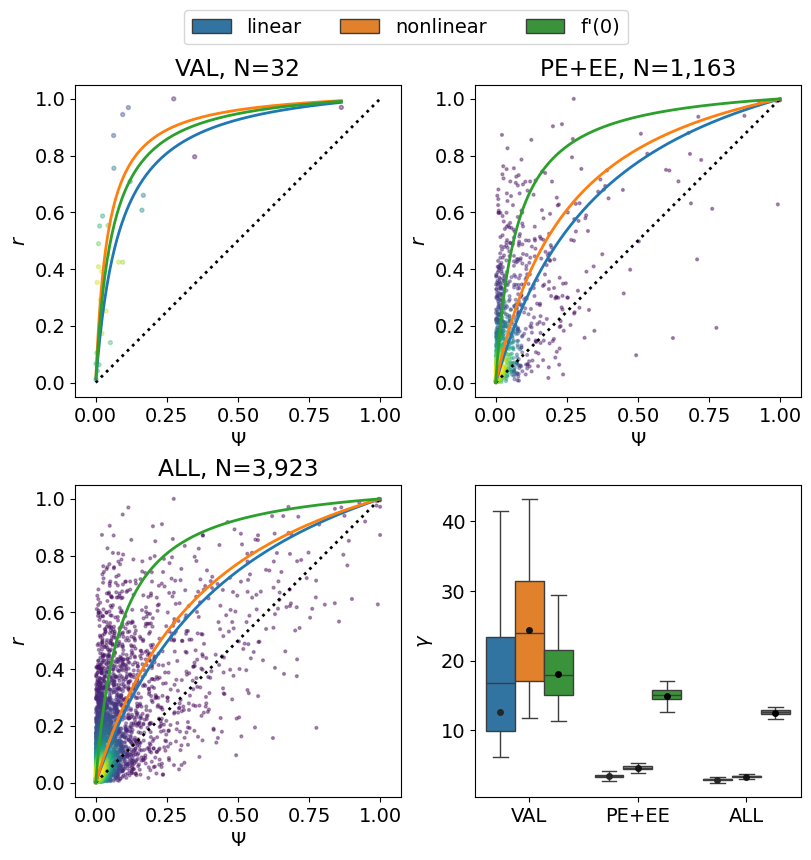

In [1235]:
f, axes = plt.subplot_mosaic(
    """
    AB
    CD
    """,
    layout="constrained",
    figsize=(8,8),
    width_ratios=(1,1)
)

axes["B"].sharey(axes["A"])
axes["C"].sharey(axes["A"])

full_data = []
for (axname,ax),key,col in zip(axes.items(),names,cols):
    tmp = sets[sets[col]==1][['src','event_id']].merge(dkd) if col !='set0' else dkd.copy()
    z,idx = hf.plot2d(tmp.ctrl_psi,tmp.exp_psi)
    ax.scatter(tmp.ctrl_psi.iloc[idx],tmp.exp_psi.iloc[idx],c=z[idx],s=8 if col=='set1' else 4 ,alpha=0.4)
    ax.plot([0,1],[0,1],lw=2,ls=':',c='black')
    #t = f'{key}, N={len(tmp)}\n{int(100*np.mean((tmp.exp_psi-tmp.ctrl_psi)>0))}%>0'
    t = f'{key}, N={len(tmp):,}'
    resd,_ = hf.get_gamma(tmp,ax=ax,linear_thr=0.01,funcs=funcs)
    resd = pd.Series(resd)
    resd.name = key
    full_data.append(resd)
    ax.set_title(t)
    #ax.legend(loc='lower center',bbox_to_anchor=(0.5,1.1))
    ax.get_legend().remove()
    ax.axis('equal')
    ax.set_xlabel(r'$\Psi$')
    ax.set_ylabel(r'$r$')

ax = axes['D']

full_data = pd.concat(full_data,axis=1)
full_data['method'] = full_data.index
full_data = full_data.melt(id_vars='method',var_name='sets',value_name='gamma')

sns.boxplot(data=resdf2,y='gamma',hue='method',x='sets',ax=ax,showfliers=False)
handles, labels = ax.get_legend_handles_labels()
f.legend(handles, labels, loc='lower center',bbox_to_anchor=(0.5,1),ncol=3)

sns.stripplot(data=full_data,y='gamma',hue='method',x='sets',ax=ax, dodge=True,palette='dark:black')
ax.set_ylabel('$\gamma$')
ax.set_xlabel(None)
ax.get_legend().remove()
#ax.set_yscale('log')

In [1236]:
f.savefig('./figures/Fig2.pdf',bbox_inches='tight')

## Figure 3

+ (A) Scatterplot r vs PSI for responders: colormap = posterior P; diagonal dashed line; gamma and pi above the graph.
+ (B) Same for non-responders

OR

+ (A) together for responders and non-responders for all USE
+ (B) together for responders and non-responders for cassette (PE+EE)


In [1237]:
import mm
from importlib import reload
reload(mm)

<module 'mm4' from 'C:\\Users\\zavil\\tcga_paper\\NMDeq\\project\\mm4.py'>

In [1238]:
use = pd.read_csv('./nmd_inactivation_data/united_use_master_table.tsv',sep='\t')
ase = pd.read_csv('./nmd_inactivation_data/binASE_master_table.tsv',sep='\t')

use = use[(use.ctrl_psi!=0)&(use.exp_psi!=0)]
ase = ase[(ase.ctrl_psi!=0)&(ase.exp_psi!=0)]

In [1239]:
def plot_dataset(exper,ctrl,ax=None,dropzeros=False, plot_borders=True, **kwargs):
    #tau=1, lambda_pi=0, lambda_sigma=0, n_init=10
    if ax is None:
        f,ax = plt.subplots()
    
    if dropzeros:
        exper = exper[(exper.ctrl_psi!=0)&(exper.exp_psi!=0)].copy()
        ctrl =  ctrl[(ctrl.ctrl_psi!=0)&(ctrl.exp_psi!=0)].copy()
    
    if (ctrl.shape[0]==0) or (exper.shape[0]==0):
        print(f'no data for {key}')
        return

    res,params,prob,other,results = mm.get_params_mixture(exper,ctrl,**kwargs)
    if res:
        mm.plot_model(exper,params,prob,ax=ax)
        print('prob',np.mean(prob>0.5))
    
        a0_hat, a1_hat, pi_hat, a_r_hat, b_r_hat, c_r_hat, a_nr_hat, b_nr_hat, c_nr_hat = params
        y = np.linspace(0,1,100)

        if plot_borders:
    
            sigma_r = mm.heteroskedastic_sigma(y, a_r_hat, b_r_hat, c_r_hat)
            sigma_nr = mm.heteroskedastic_sigma(y, a_nr_hat, b_nr_hat, c_nr_hat)
            sigma_r = np.maximum(sigma_r, 1e-3)
            sigma_nr = np.maximum(sigma_nr, 1e-3)
            curve_nr = mm.r2psi(y,a0_hat)
            curve_r = mm.r2psi(y,a1_hat)
    
            upper,lower = curve_r+sigma_r,curve_r-sigma_r
            upper,lower = np.clip(upper,0,1),np.clip(lower,0,1)
            ax.fill_betweenx(y,lower,upper,color='lightgrey',alpha=0.5)
            ax.plot(upper,y,c='grey',ls=':')
            ax.plot(lower,y,c='grey',ls=':')
            
            upper,lower = curve_nr+sigma_nr,curve_nr-sigma_nr
            upper,lower = np.clip(upper,0,1),np.clip(lower,0,1)
            ax.fill_betweenx(y,lower,upper,color='lightgrey',alpha=0.5)
            ax.plot(upper,y,c='grey',ls=':')
            ax.plot(lower,y,c='grey',ls=':')
    else:
        print(f'Model failed: {key}')
    return res,params,prob,other,results

### Mixture model plots for 3 sets of USEs in HeLa dKD

prob 0.96875
prob 0.7583834909716252
prob 0.6913076726994647
CPU times: total: 52.6 s
Wall time: 52.9 s


Text(0.02, 0.5, '$r$')

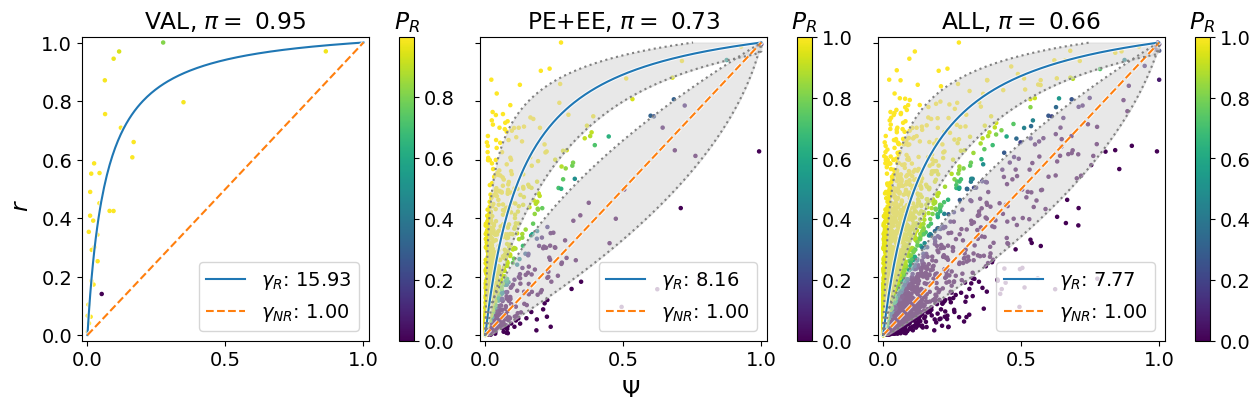

In [1240]:
%%time
key = 'HeLa dKD'
cols = ['set1','set2','set3']
names = ['VAL', 'PE+EE', 'ALL']
#inits = [30,20,1]
inits = [30,30,30]

f,axes = plt.subplots(1,3,figsize=(12.5,4),constrained_layout=True,sharey=True)
for name,col,n_init,ax in zip(names,cols,inits,axes):

    exper = sets[sets[col]==1][['src','event_id']].merge(use) if col !='set0' else use.copy()
    exper = exper[exper.experiment==key].copy()
    ctrl = ase[ase.experiment==key].copy()

    plot_borders = False if name=='VAL' else True
    plot_dataset(exper,ctrl,n_init=n_init,ax=ax,plot_borders=plot_borders)
    t = ax.get_title()
    ax.set_title(f'{name}, {t}')
    ax.set_xlim(-0.02,1.02)
    ax.set_ylim(-0.02,1.02)
    
    xlab = ax.get_xlabel()
    ylab = ax.get_ylabel()
    ax.set_xlabel(None)
    ax.set_ylabel(None)
    #ax.axis('equal')
f.supxlabel(xlab)
f.supylabel(ylab)

In [1241]:
#f.axes[3]._colorbar.remove()
ax = f.axes[0]
scatter = ax.collections[0]
scatter.set_clim(0, 1)

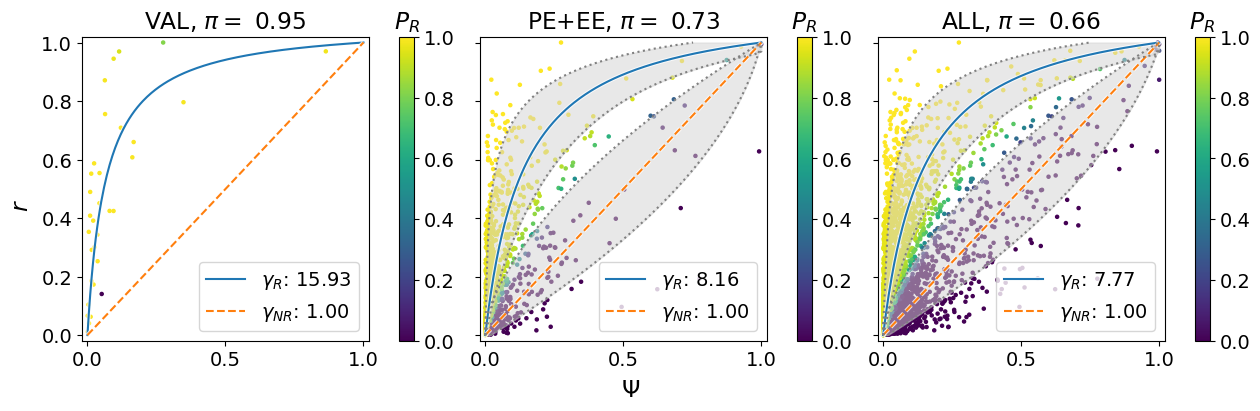

In [1242]:
f

In [1243]:
f.savefig('./figures/Fig3_mm_scatters.pdf',bbox_inches='tight')

### Other datasets (mm plots, stability of $\gamma_R$ and consistency between datasets)

<a id="sf3"></a>

#### Bootstrapping

In [1244]:
good_data = ['HeLa CHX', 'HeLa SMG6 KD', 'HeLa UPF1 KD', 'HeLa dKD', 'HepG2 nucl/cyto', 'K562 nucl/cyto']
tmp = use[(use.exp_psi!=0)&(use.ctrl_psi!=0)&(use.experiment.isin(good_data))]
datasets = {key1: group for key1, group in tmp.groupby('experiment')}
kwargs = [{'ctrl':ase[(ase.experiment==key)&(ase.exp_psi!=0)&(ase.ctrl_psi!=0)],'n_init':10} for key in datasets]

In [1245]:
'" "'.join(good_data)

'HeLa CHX" "HeLa SMG6 KD" "HeLa UPF1 KD" "HeLa dKD" "HepG2 nucl/cyto" "K562 nucl/cyto'

In [1246]:
{key:len(value) for key,value in datasets.items()}

{'HeLa CHX': 329,
 'HeLa SMG6 KD': 3555,
 'HeLa UPF1 KD': 3551,
 'HeLa dKD': 3923,
 'HepG2 nucl/cyto': 2918,
 'K562 nucl/cyto': 3172}

In [1247]:
[len(value['ctrl']) for value in kwargs]

[665, 2907, 2992, 3171, 2420, 2543]

In [1248]:
n_workers = len(datasets)
n_workers

6

In [772]:
%%time
parameters = mm.parallel_bootstrap(datasets,n_workers=n_workers,bootstrap_kwargs=kwargs)

Finished: HeLa CHX
Finished: HepG2 nucl/cyto
Finished: K562 nucl/cyto
Finished: HeLa dKD
Finished: HeLa SMG6 KD
Finished: HeLa UPF1 KD
CPU times: total: 109 ms
Wall time: 8min 21s


In [773]:
res = []
for key,val in parameters.items():
    val['experiment'] = key
    res.append(val)
res = pd.concat(res)

In [774]:
res.to_csv('./nmd_inactivation_data/mixture_model_bootstrapping_anno.tsv',sep='\t',index=False)

In [1249]:
res = pd.read_csv('./nmd_inactivation_data/mixture_model_bootstrapping_anno.tsv',sep='\t')

In [1250]:
res.experiment.value_counts()

experiment
HeLa CHX           50
HepG2 nucl/cyto    50
K562 nucl/cyto     50
HeLa dKD           50
HeLa SMG6 KD       50
HeLa UPF1 KD       50
Name: count, dtype: int64

In [1251]:
good_data = ['HeLa CHX', 'HeLa SMG6 KD', 'HeLa UPF1 KD', 'HeLa dKD', 'HepG2 nucl/cyto', 'K562 nucl/cyto']

prob 0.7173252279635258
prob 0.79971870604782
prob 0.7048718670796958
prob 0.6913076726994647
prob 0.7361206305688828
prob 0.6932534678436317
CPU times: total: 1min 53s
Wall time: 1min 55s


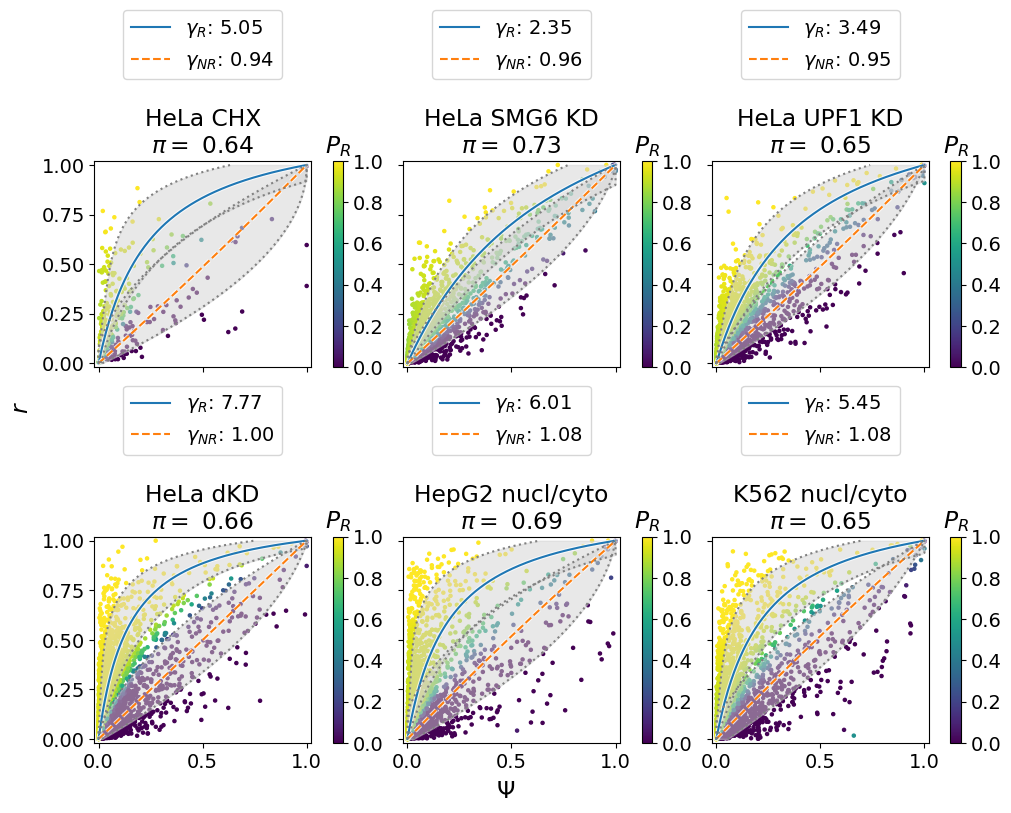

In [1252]:
%%time
good_res = dict()

responder_df = []
n_init=20
f,ax = plt.subplots(2,3,figsize=(10,8),sharex=True,sharey=True,constrained_layout=True)
ax = ax.flatten()
for i,key in enumerate(good_data):
    ctrl = ase[ase.experiment==key]
    exper = use[use.experiment==key].copy()

    exper = exper[(exper.ctrl_psi!=0)&(exper.exp_psi!=0)]
    ctrl = ctrl[(ctrl.ctrl_psi!=0)&(ctrl.exp_psi!=0)]

    if (ctrl.shape[0]==0) or (exper.shape[0]==0):
        print(f'no data for {key}')
        continue
    try:
        lambda_sigma = 0
        success,params,prob,other,results = plot_dataset(exper,ctrl,n_init=n_init,ax=ax[i],lambda_sigma=lambda_sigma)
        exper['prob'] = prob
        responder_df.append(exper)
    except Exception as e:
        print(key)
        print(e)
        continue
    good_res[key] = params
    t = ax[i].get_title()
    ax[i].set_title(f'{key}\n{t}')
    ax[i].set_xlim(-0.02,1.02)
    ax[i].set_ylim(-0.02,1.02)
    xlab = ax[i].get_xlabel()
    ylab = ax[i].get_ylabel()
    ax[i].set_xlabel(None)
    ax[i].set_ylabel(None)
    ax[i].legend(loc='lower center', bbox_to_anchor=(0.5,1.35))
f.supxlabel(xlab)
f.supylabel(ylab)
for j in range(i+1,len(ax)):
    f.delaxes(ax[j])

responder_df = pd.concat(responder_df)
responder_df.to_csv('./nmd_inactivation_data/united_use_master_table_with_responder_prob_anno.tsv',sep='\t',index=False)

In [1253]:
f.savefig('./figures/Fig3_mm_supplementary.pdf',bbox_inches='tight')

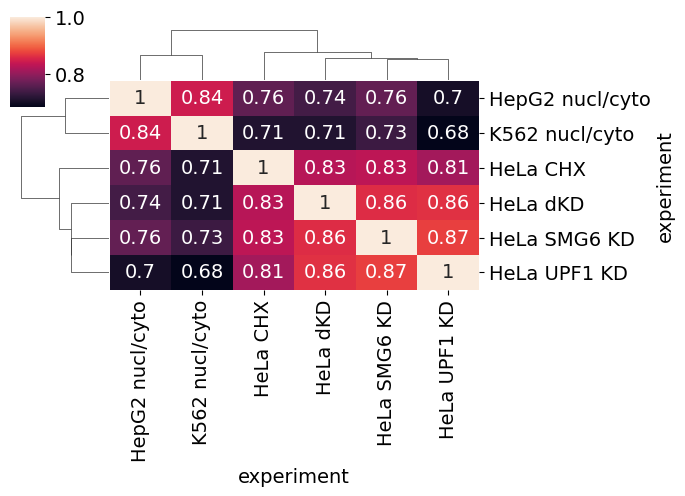

In [605]:
aa = pd.read_csv('./nmd_inactivation_data/united_use_master_table_with_responder_prob_anno.tsv',sep='\t')
responder_df = aa
condition = (responder_df.prob>0.5)&(responder_df.exp_psi>0.05)
responder_df['responder'] = np.where(responder_df.prob>0.5,1,0)

mat = responder_df.pivot(index=['src','event_id'],columns='experiment',values='responder')
#mat = mat[mat.notna().all(1)]

#aa = mat.isna().sum(1)
#bb = aa.value_counts()
#bb = bb.loc[sorted(bb.index)]
#ind = aa[aa<2].index
#mat - mat.loc[ind]

from sklearn.metrics import f1_score

def pairwise(x,y):
    idx = (np.isnan(x)|np.isnan(y))
    return f1_score(x[~idx],y[~idx])
mat = mat.corr(method=pairwise)

g = sns.clustermap(mat,annot=True,fmt='.2g',figsize=(7,5))

In [606]:
responder_df = pd.read_csv('./nmd_inactivation_data/united_use_master_table_with_responder_prob_anno.tsv',sep='\t')

In [607]:
condition = (responder_df.exp_psi>0.05)&(responder_df.prob>0.5)
responder_df['responder'] = np.where(responder_df.prob>0.5,1,0)

In [608]:
responder_df.groupby('experiment').responder.agg('mean')

experiment
HeLa CHX           0.717325
HeLa SMG6 KD       0.799719
HeLa UPF1 KD       0.704872
HeLa dKD           0.691308
HepG2 nucl/cyto    0.743660
K562 nucl/cyto     0.692308
Name: responder, dtype: float64

In [609]:
responder_df = responder_df[~responder_df.experiment.isin(['fractioning_A549','HeLa_SMG7_KD'])].copy()

In [610]:
responder_df.experiment = responder_df.experiment.str.replace('fractioning','frac')
res.experiment = res.experiment.str.replace('fractioning','frac')

In [611]:
responder_df.experiment.unique()

array(['HeLa CHX', 'HeLa SMG6 KD', 'HeLa UPF1 KD', 'HeLa dKD',
       'HepG2 nucl/cyto', 'K562 nucl/cyto'], dtype=object)

In [612]:
mat = responder_df.pivot(index=['src','event_id'],columns='experiment',values='responder')
#mat = mat[mat.notna().all(1)]

#aa = mat.isna().sum(1)
#bb = aa.value_counts()
#bb = bb.loc[sorted(bb.index)]
#ind = aa[aa<2].index
#mat - mat.loc[ind]

from sklearn.metrics import f1_score

def pairwise(x,y):
    idx = (np.isnan(x)|np.isnan(y))
    return f1_score(x[~idx],y[~idx])
mat = mat.corr(method=pairwise)

g = sns.clustermap(mat,annot=True,fmt='.2g',figsize=(6,5))
plt.close()

order = [i._text for i in g.ax_heatmap.get_xticklabels()]

f,ax = plt.subplots(1,3,figsize=(10,5),constrained_layout=True)


tmp = res[res.experiment.isin(order)].copy()
tmp.experiment = tmp.experiment.astype('category').cat.reorder_categories(order)
tmp = tmp.sort_values('experiment')
sns.boxplot(data=tmp,y='experiment',x='a1_hat',showfliers=False,ax=ax[0],color='lightgrey',linecolor='black')
ax[0].set_xlabel('$\gamma$')
ax[0].set_ylabel(None)

ax[0].axvline(1,ls=':',c='black')

t1 = ax[0].get_yticklabels()


corr = mat.loc[order,order].copy()
mask = np.zeros_like(corr, dtype=bool)
mask[np.triu_indices_from(mask)] = True
corr = corr.iloc[0:,:-1]
mask = mask[0:,:-1]
sns.heatmap(corr, mask=mask, annot=True, fmt='.2g', linewidths=.5, ax=ax[1],annot_kws={"size": 10})

ax[1].set_xticklabels(ax[1].get_xticklabels(),ha='right',rotation=45,rotation_mode='anchor')
#ax[1].set_xticklabels(ax[1].get_xticklabels(),ha='left',rotation=-45,rotation_mode='anchor')
ax[1].set_xlabel(None)
ax[1].set_ylabel(None)
ax[1].set_yticks([])

from matplotlib.ticker import MaxNLocator
ax[0].xaxis.set_major_locator(MaxNLocator(nbins=5))

t2 = ax[1].get_yticklabels()
f.axes[-1].set_title('F1')
plt.close()

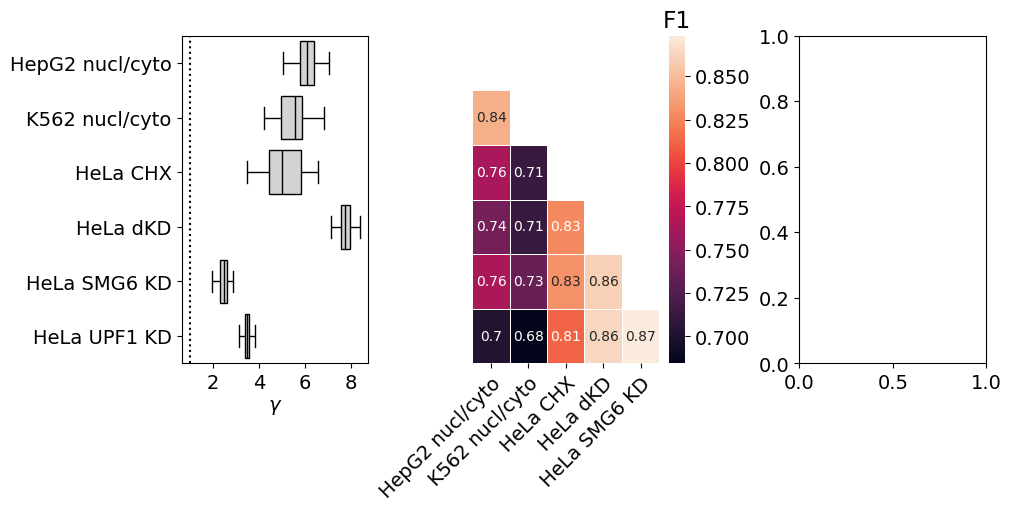

In [613]:
f

In [614]:
order

['HepG2 nucl/cyto',
 'K562 nucl/cyto',
 'HeLa CHX',
 'HeLa dKD',
 'HeLa SMG6 KD',
 'HeLa UPF1 KD']

### LogFC of R vs NR

In [615]:
responders = responder_df

In [616]:
lfc = []
for file in glob.glob('./nmd_inactivation_data/deseq_res/*tsv'):
    if not (("ripit" in file.lower()) or ("fractioning" in file.lower())):
        tmp = pd.read_csv(file,sep='\t',index_col=[0])
        name = 'chx' if 'CHX' in file else os.path.basename(file)[:-4]
        tmp['experiment'] = name
        tmp['gene_id'] = tmp.index
        lfc.append(tmp[['experiment','gene_id','log2FoldChange']])
ripit = pd.read_csv('./nmd_inactivation_data/deseq_res/ripit_gene_logFC.tsv',sep='\t').rename(columns={'logFC':'log2FoldChange'})
ripit = ripit[['experiment','gene_id','log2FoldChange']]
lfc.append(ripit)

frac = pd.read_csv('./nmd_inactivation_data/deseq_res/fractioning_logFC.tsv',sep='\t')
frac = frac[['experiment','gene_id','log2FoldChange']]
lfc.append(frac)

lfc = pd.concat(lfc)

#lfc.experiment = lfc.experiment.replace('hela_chx_24h','HeLa_chx')
#lfc.experiment = lfc.experiment.str.replace('fractioning','frac')

def replace(x):
    frac = 'nucl/cyto'
    xr = x.str.replace('_',' ').str.replace('fractioning',frac).str.replace('chx','CHX')
    cond = xr.str.contains(frac)
    xr.loc[cond] = xr.loc[cond].apply(lambda x: ' '.join(x.split(' ')[::-1]))
    return xr
lfc.experiment = replace(lfc.experiment)

In [617]:
lfc.experiment.unique()

array(['CHX', 'HeLa CHX', 'HeLa dKD', 'HeLa SMG6 KD', 'HeLa SMG7 KD',
       'HeLa UPF1 KD', 'RIPiT', 'A549 nucl/cyto', 'GM12878 nucl/cyto',
       'H1 nucl/cyto', 'HT1080 nucl/cyto', 'HeLa-S3 nucl/cyto',
       'HepG2 nucl/cyto', 'IMR-90 nucl/cyto', 'K562 nucl/cyto',
       'MCF-7 nucl/cyto', 'NCI-H460 nucl/cyto', 'SK-MEL-5 nucl/cyto',
       'SK-N-DZ nucl/cyto', 'SK-N-SH nucl/cyto',
       'vein umbilical of cell endothelial nucl/cyto',
       'keratinocyte nucl/cyto'], dtype=object)

In [618]:
catalog = pd.read_csv('./use_catalog/filtered_catalog.tsv',sep='\t')

In [619]:
cat = catalog[['gene_id','src','event_id']].drop_duplicates()

In [620]:
condition = (responders.prob>0.5)&(responders.exp_psi>0.05)
responders['responder'] = np.where(condition,'R','NR')

In [621]:
aa = responders
resp = cat.merge(aa).sort_values('responder',ascending=False)[['gene_id','experiment','responder']].drop_duplicates()

In [622]:
resp.experiment.unique()

array(['K562 nucl/cyto', 'HeLa UPF1 KD', 'HeLa SMG6 KD', 'HeLa dKD',
       'HepG2 nucl/cyto', 'HeLa CHX'], dtype=object)

In [623]:
resp = resp.merge(lfc)

In [624]:
resp[['experiment','responder']].value_counts(sort=False)

experiment       responder
HeLa CHX         NR            121
                 R             177
HeLa SMG6 KD     NR           1604
                 R            1254
HeLa UPF1 KD     NR           1621
                 R            1217
HeLa dKD         NR           1532
                 R            1607
HepG2 nucl/cyto  NR           1164
                 R            1130
K562 nucl/cyto   NR           1339
                 R            1183
Name: count, dtype: int64

In [625]:
resp.experiment = resp.experiment.astype('category').cat.reorder_categories(order)
resp = resp.sort_values(['experiment','responder'],ascending=[True,False])

In [626]:
f.axes[2].clear()

In [627]:
sns.boxplot(data=resp,y='experiment',x='log2FoldChange',hue='responder',showfliers=False,ax=ax[2])
ax[2].set_yticks([])
ax[2].set_ylabel(None)
ax[2].legend(title=None,loc='lower center', bbox_to_anchor=(0.5,1),ncol=2)

ax[2].axvline(0,ls=':',c='black')


from statannotations.Annotator import Annotator

pairs = [((i,'R'),(i,'NR')) for i in order]
annotator = Annotator(
    ax[2],
    pairs,
    data=resp,
    y='experiment',
    x='log2FoldChange',
    hue='responder',
    orient="h"
)

annotator.configure(
    test="Mann-Whitney", 
    text_format="star",     
    loc="inside",           
    comparisons_correction="bonferroni"
)

annotator.apply_and_annotate()

p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

K562 nucl/cyto_R vs. K562 nucl/cyto_NR: Mann-Whitney-Wilcoxon test two-sided with Bonferroni correction, P_val:3.132e-30 U_stat=1.003e+06
HepG2 nucl/cyto_R vs. HepG2 nucl/cyto_NR: Mann-Whitney-Wilcoxon test two-sided with Bonferroni correction, P_val:8.137e-31 U_stat=8.431e+05
HeLa CHX_R vs. HeLa CHX_NR: Mann-Whitney-Wilcoxon test two-sided with Bonferroni correction, P_val:1.282e-02 U_stat=1.295e+04
HeLa dKD_R vs. HeLa dKD_NR: Mann-Whitney-Wilcoxon test two-sided with Bonferroni correction, P_val:6.334e-04 U_stat=1.329e+06
HeLa SMG6 KD_R vs. HeLa SMG6 KD_NR: Mann-Whitney-Wilcoxon test two-sided with Bonferroni correction, P_val:1.433e-05 U_stat=1.109e+06
HeLa UPF1 KD_R vs. HeLa UPF1 KD_NR: Mann-Whitney-Wilcoxon test two-sided with Bonferroni correction, P_val:1.000e+00 U_stat=1.005e+06


(<Axes: xlabel='log2FoldChange'>,
  <statannotations.Annotation.Annotation at 0x1ed21f040d0>])

<Figure size 640x480 with 0 Axes>

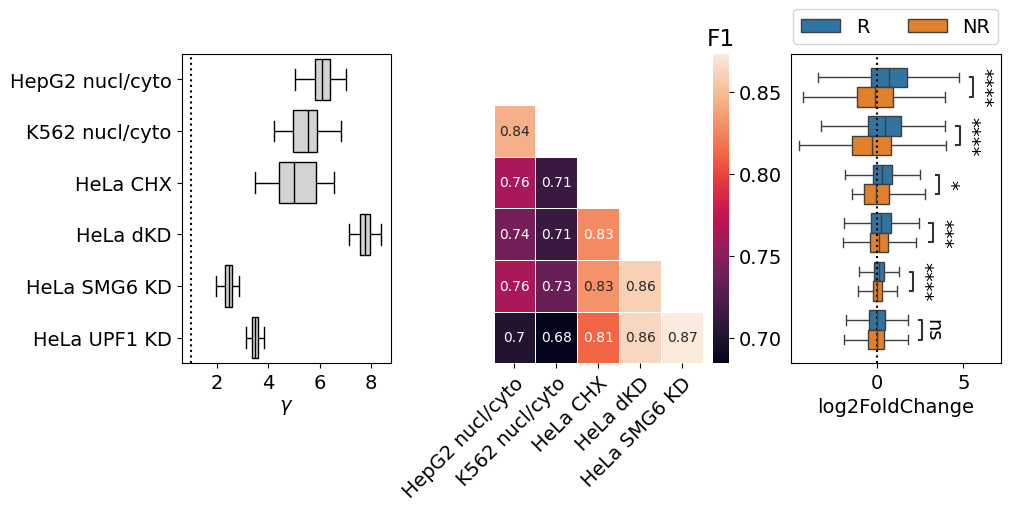

In [628]:
f

In [629]:
ax = f.axes[0]
pos = ax.get_position()
pos.x0 = 0.1
pos.x1 = 0.34
ax.set_position(pos)
f.axes[2].set_xlabel(r'$\log_2$FC')

Text(0.5, 113.34238349156125, '$\\log_2$FC')

In [630]:
pos.x1

0.34

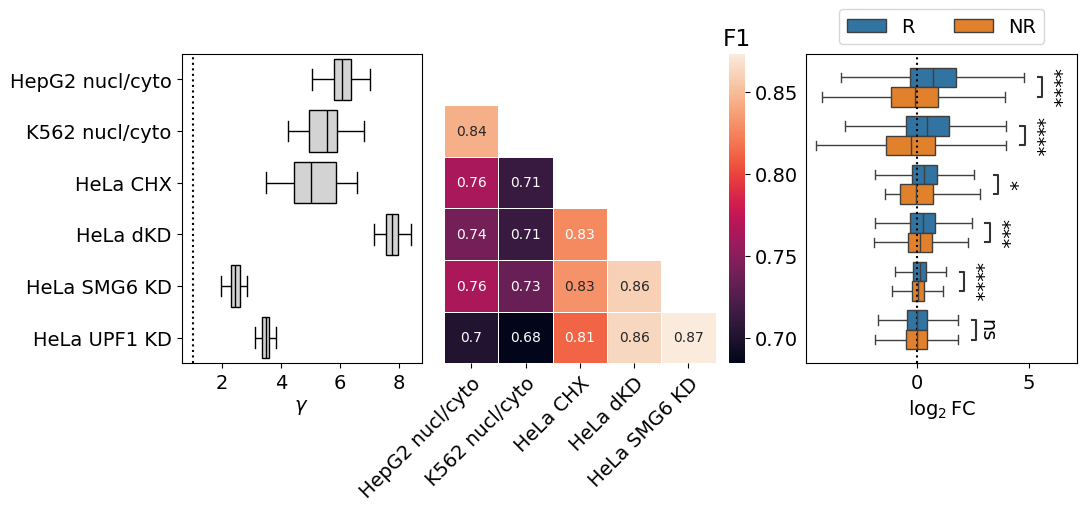

In [631]:
f

In [632]:
f.savefig('./figures/Fig3_mm_stability_consistency_and_logFC.pdf',bbox_inches='tight')

In [633]:
aa = responders[responders.experiment=='HeLa_dKD'][['src','event_id','responder']].drop_duplicates()
masha = aa.merge(catalog)
masha.to_csv('C:/Users/zavil/Downloads/responders.tsv',sep='\t',index=False)

### PhyloP and RiboSeq

In [635]:
phylop = pd.read_csv('C:/Users/zavil/Downloads/Telegram Desktop/PE.up_down_regions_periodicity.539events.csv')
phylop = phylop[(phylop.cons == "phylop30_pos")&(phylop.region == "up")].copy()
phylop.responder = phylop.responder.map({True:'R',False:'NR'})

In [636]:
tmp = phylop.copy()
f,(ax,ax2) = plt.subplots(1,2,figsize=(10,1.5),constrained_layout=True,sharey=True)
sns.boxplot(data=tmp,y='responder',x='dcons',hue='responder',showfliers=False,ax=ax)
ax.set_xlabel('Coding potential')
ax.set_ylabel(None)


from statannotations.Annotator import Annotator

pairs = [('R','NR')]
annotator = Annotator(
    ax,
    pairs,
    data=tmp,
    y='responder',
    x='dcons',
    orient="h"
)

annotator.configure(
    test="Mann-Whitney", 
    text_format="star",     
    loc="inside",           
#    comparisons_correction="bonferroni"
)

annotator.apply_and_annotate()
plt.close()

p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

R vs. NR: Mann-Whitney-Wilcoxon test two-sided, P_val:3.749e-02 U_stat=2.580e+04


In [637]:
#riboseq = 'C:/Users/zavil/Downloads/Telegram Desktop/PE.up_down_regions_w_ribosome_profiling_EMTAB.539events.csv'
riboseq = 'C:/Users/zavil/Downloads/Telegram Desktop/PE_up_down_regions_w_ribosome_profiling_EMTAB_cov_matched_subset.csv'

riboseq = pd.read_csv(riboseq,usecols=['src','event_id','responder','cov_whole','cov_up','cov_down',
                                       'width_whole','width_up','width_down','readth_fr','matching_group'])
riboseq.responder = riboseq.responder.map({True:'R',False:'NR'})

p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

R vs. NR: Mann-Whitney-Wilcoxon test two-sided, P_val:1.046e-02 U_stat=4.040e+03


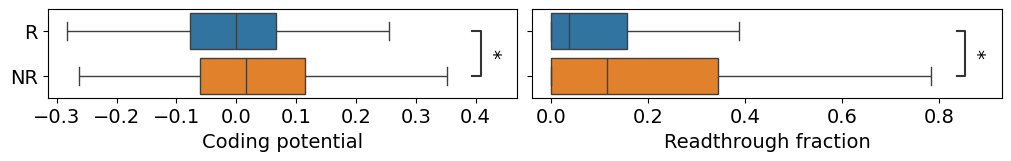

<Figure size 640x480 with 0 Axes>

In [638]:
tmp = riboseq[(riboseq.width_up>10)&(riboseq.width_down>5)&(riboseq.cov_up>0.1)]

sns.boxplot(data=tmp,y='responder',x='readth_fr',hue='responder',showfliers=False,ax=ax2)

pairs = [('R','NR')]
annotator = Annotator(
    ax2,
    pairs,
    data=tmp,
    y='responder',
    x='readth_fr',
    orient="h"
)

annotator.configure(
    test="Mann-Whitney", 
    text_format="star",     
    loc="inside",           
#    comparisons_correction="bonferroni"
)

annotator.apply_and_annotate()


ax2.set_xlabel('Readthrough fraction')
ax2.set_ylabel(None)
f

In [639]:
f.savefig('./figures/Fig3_phylop_and_riboseq.pdf',bbox_inches='tight')

In [960]:
jnc = riboseq[['src','event_id']].drop_duplicates().merge(catalog)

In [962]:
all(jnc.event_type=='PE')

True

In [971]:
def get_ex(df):
    coords = set.union(*df.long_id.apply(lambda x: set(x.split('_')[1:-1])))
    coords = sorted([int(i) for i in coords])
    if len(coords)!=4:
        return
    c = df.long_id.iloc[0].split('_')
    chrn = c[0]
    strand = c[-1]
    return '_'.join([chrn,str(coords[1]),str(coords[2]),strand])

In [982]:
ex = jnc.groupby(['src','event_id']).apply(get_ex)
ex.name = 'ex'
m = ex.reset_index().merge(riboseq)

C:\Users\zavil\AppData\Local\Temp\ipykernel_4592\1517218927.py:1: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  ex = jnc.groupby(['src','event_id']).apply(get_ex)


In [986]:
m = m.merge(phylop)

In [992]:
tmp = m[(m.width_up>10)&(m.width_down>5)&(m.cov_up>0.1)&(tmp.readth_fr<1)]

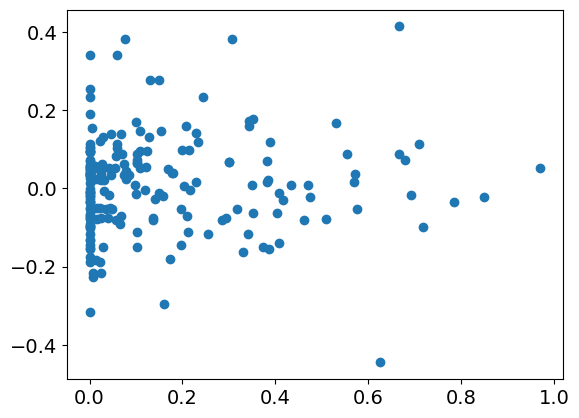

In [993]:
plt.scatter(tmp.readth_fr,tmp.dcons)

In [955]:
catalog[catalog.event_id.isin(riboseq.event_id)]

,src,gene_id,event_id,interval_start,interval_end,nmd_id_list,coding_id_list,VIP,event_type,transcript_biotype,jtype,long_id,coef
43,ensembl,ENSG00000028310,ENSG00000028310_0,889737,891155,"ENST00000466684, ENST00000487688, ENST00000489...","ENST00000467963, ENST00000483173",DAD:DAD,A3SS,protein_coding,j,chr5_889647_891155_-,1.0
44,ensembl,ENSG00000028310,ENSG00000028310_0,889737,891155,"ENST00000466684, ENST00000487688, ENST00000489...","ENST00000467963, ENST00000483173",DAD:DAD,A3SS,nonsense_mediated_decay,j,chr5_889766_891155_-,1.0
133,ensembl,ENSG00000029363,ENSG00000029363_1,136273963,136275532,ENST00000534269,"ENST00000353331, ENST00000392348, ENST00000527...",DADA:DA,PE,nonsense_mediated_decay,j,chr6_136273187_136273963_-,0.5
134,ensembl,ENSG00000029363,ENSG00000029363_1,136273963,136275532,ENST00000534269,"ENST00000353331, ENST00000392348, ENST00000527...",DADA:DA,PE,protein_coding,j,chr6_136273187_136275532_-,1.0
135,ensembl,ENSG00000029363,ENSG00000029363_1,136273963,136275532,ENST00000534269,"ENST00000353331, ENST00000392348, ENST00000527...",DADA:DA,PE,nonsense_mediated_decay,j,chr6_136274189_136275532_-,0.5
...,...,...,...,...,...,...,...,...,...,...,...,...,...
50519,chess,ENSG00000135945,ENSG00000135945_0,99402618,99402799,"CHS.30297.12, CHS.30297.15, CHS.30297.9","CHS.30297.10, CHS.30297.11, CHS.30297.13, CHS....",AD:ADAD,IR,nonsense_mediated_decay,ir,chr2_99402346_-,0.5
50525,chess,ENSG00000136147,ENSG00000136147_0,49518019,49518179,CHS.14054.31,"CHS.14054.2, CHS.14054.21, CHS.14054.3",AD:ADAD,IR,nonsense_mediated_decay,ir,chr13_49518151_+,0.5
51238,chess,ENSG00000108515,ENSG00000108515_0,4955408,4955672,"CHS.21076.13, CHS.21076.31, CHS.21076.38, CHS....","CHS.21076.10, CHS.21076.14, CHS.21076.26, CHS....",AD:ADAD,IR,nonsense_mediated_decay,ir,chr17_4955942_+,0.5
51414,chess,ENSG00000135945,ENSG00000135945_0,99402618,99402799,"CHS.30297.12, CHS.30297.15, CHS.30297.9","CHS.30297.10, CHS.30297.11, CHS.30297.13, CHS....",AD:ADAD,IR,nonsense_mediated_decay,ir,chr2_99402644_-,0.5


In [952]:
phylop

,ex,stop_cod,region,responder,cons,dcons
1,chr10_102727675_102727791_+,102727679,up,R,phylop30_pos,0.075500
13,chr10_103136249_103136372_-,103136362,up,NR,phylop30_pos,0.532417
25,chr10_103399647_103399830_+,103399659,up,R,phylop30_pos,-0.103250
37,chr10_103898293_103898377_-,103898323,up,R,phylop30_pos,-0.049023
49,chr10_1079556_1079677_+,1079597,up,R,phylop30_pos,-0.009896
...,...,...,...,...,...,...
6173,chrX_149491538_149491667_-,149491608,up,NR,phylop30_pos,0.105737
6185,chrX_150751030_150751240_+,150751078,up,R,phylop30_pos,0.062406
6197,chrX_48575815_48576083_+,48575875,up,R,phylop30_pos,-0.027650
6209,chrX_49604998_49605140_+,49605084,up,NR,phylop30_pos,0.052971


## Figure 4

Bayes model

### Launch commands

In [130]:
python = r'C:\Users\zavil\miniconda3\envs\pymc\python.exe'
script = './fit_bayes_new.py'

experiment = 'HeLa_dKD'

cmd = f'''{python} -u {script} --help
'''
!{cmd}

usage: fit_bayes_new.py [-h] -d psi.tsv -p /path/to/output/prefix
                        [-e EXPERIMENT] [--ctrl CTRL] [--exp EXP]
                        [--ctrl_denom CTRL_DENOM] [--exp_denom EXP_DENOM]

The program takes a table of paired psi measurements ctrl_psi and exp_psi and fits Bayes model for individual gamma values.
You may specify any kwargs that will be passed to bayes_model

options:
  -h, --help            show this help message and exit
  -d psi.tsv, --data psi.tsv
                        input data with columns ctrl_psi, exp_psi
  -p /path/to/output/prefix, --prefix /path/to/output/prefix
                        prefix for output files
  -e EXPERIMENT, --experiment EXPERIMENT
                        Which experiment to select
  --ctrl CTRL           name of column with ctrl psi values (default: ctrl_psi)
  --exp EXP             name of column with exp psi values (default: exp_psi)
  --ctrl_denom CTRL_DENOM
                        name of column with ctrl denom values

C:\Users\zavil\miniconda3\envs\pymc\lib\site-packages\arviz\__init__.py:50: FutureWarning: 
ArviZ is undergoing a major refactor to improve flexibility and extensibility while maintaining a user-friendly interface.
Some upcoming changes may be backward incompatible.
For details and migration guidance, visit: https://python.arviz.org/en/latest/user_guide/migration_guide.html
  warn(


In [131]:
import subprocess
import threading
import signal
import time
import html

import ipywidgets as widgets
from IPython.display import display


class BackgroundMCMC:

    def __init__(self, cmd, title="MCMC Run", update_interval=0.1):

        self.cmd = cmd
        self.update_interval = update_interval

        self.process = None

        # UI
        self.header = widgets.HTML(f"<h4>{html.escape(title)}</h4>")

        self.progress = widgets.HTML()
        self.logs = widgets.HTML()
        self.status = widgets.HTML("<i>Running...</i>")

        self.button_cancel = widgets.Button(
            description="Cancel",
            button_style="danger",
            icon="stop"
        )
        self.button_cancel.on_click(self.cancel)

        self.ui = widgets.VBox([
            self.header,
            self.button_cancel,
            self.progress,
            self.logs,
            self.status
        ])

        display(self.ui)

    # ------------------------------------------------------------
    # START
    # ------------------------------------------------------------
    def start(self):
        threading.Thread(target=self._run, daemon=True).start()

    # ------------------------------------------------------------
    # MAIN LOOP (BACK TO YOUR ORIGINAL STYLE)
    # ------------------------------------------------------------
    def _run(self):

        self.process = subprocess.Popen(
            self.cmd,
            shell=True,
            stdout=subprocess.PIPE,
            stderr=subprocess.STDOUT,
            text=True,
            bufsize=1,

            # required for CTRL_BREAK_EVENT on Windows
            creationflags=subprocess.CREATE_NEW_PROCESS_GROUP
        )

        current_line = ""
        log_lines = []

        last_update = 0

        while True:

            char = self.process.stdout.read(1)

            if not char and self.process.poll() is not None:
                break

            # ----------------------------------------
            # PROGRESS BAR UPDATE (BLINKING STYLE)
            # ----------------------------------------
            if char == '\r':

                now = time.time()

                if now - last_update >= self.update_interval:

                    self.progress.value = (
                        f"<pre style='margin:0'>{html.escape(current_line)}</pre>"
                    )

                    last_update = now

                current_line = ""

            # ----------------------------------------
            # NORMAL LOG LINE
            # ----------------------------------------
            elif char == '\n':

                log_lines.append(current_line)

                self.logs.value = (
                    "<pre style='max-height:250px;overflow:auto;margin:0'>"
                    + html.escape("\n".join(log_lines[-50:]))
                    + "</pre>"
                )

                current_line = ""

            # ----------------------------------------
            # BUILD LINE
            # ----------------------------------------
            else:
                current_line += char

        self.process.wait()
        self.button_cancel.disabled = True

        rc = self.process.returncode

        if rc == 0:
            self.status.value = "✅ Finished"
        elif rc < 0:
            self.status.value = "🛑 Interrupted"
        else:
            self.status.value = f"❌ Exit code {rc}"

    # ------------------------------------------------------------
    # CANCEL (KEEP THIS - THIS IS THE IMPORTANT FIX)
    # ------------------------------------------------------------
    def cancel(self, _=None):

        if not self.process or self.process.poll() is not None:
            return

        self.status.value = "🛑 Terminating..."
        self.button_cancel.disabled = True

        try:
            # soft kill (works for Python + PyMC subprocess tree)
            self.process.send_signal(signal.CTRL_BREAK_EVENT)

            # give it time to exit cleanly
            for _ in range(20):
                if self.process.poll() is not None:
                    break
                time.sleep(0.1)

            # hard kill fallback
            if self.process.poll() is None:
                self.process.kill()

            self.status.value = "🛑 Terminated"

        except Exception as e:
            self.status.value = f"❌ Cancel error: {e}"

#### dKD

##### Default

In [132]:
python = r'C:\Users\zavil\miniconda3\envs\pymc\python.exe'
script = './fit_bayes_new.py'

experiment = 'HeLa_dKD'

cmd1 = f'''{python} -u {script} \
--data "./nmd_inactivation_data/united_use_master_table.tsv" \
--experiment {experiment} \
--prefix "./nmd_inactivation_data/bayes/{experiment}/default"
'''
print(cmd1)

C:\Users\zavil\miniconda3\envs\pymc\python.exe -u ./fit_bayes_new.py --data "./nmd_inactivation_data/united_use_master_table.tsv" --experiment HeLa_dKD --prefix "./nmd_inactivation_data/bayes/HeLa_dKD/default"



In [133]:
run = BackgroundMCMC(
    cmd1,
    title=f"HeLa_dKD, default",
    update_interval=5
)

run.start()

In [72]:
python = r'C:\Users\zavil\miniconda3\envs\pymc\python.exe'
script = './fit_bayes_new.py'

experiment = 'HeLa_dKD'

cmd11 = f'''{python} -u {script} \
--data "./nmd_inactivation_data/united_use_master_table_PE_and_EE.tsv" \
--experiment {experiment} \
--prefix "./nmd_inactivation_data/bayes/{experiment}/default_PE_and_EE"
'''
print(cmd11)

C:\Users\zavil\miniconda3\envs\pymc\python.exe -u ./fit_bayes_new.py --data "./nmd_inactivation_data/united_use_master_table_PE_and_EE.tsv" --experiment HeLa_dKD --prefix "./nmd_inactivation_data/bayes/HeLa_dKD/default_PE_and_EE"



In [75]:
run = BackgroundMCMC(
    cmd11,
    title=f"HeLa_dKD, default pe and ee",
    update_interval=5
)

run.start()

##### halfnormal tau

In [54]:
experiment = 'HeLa_dKD'

cmd2 = f'''{python} -u {script} \
--data "./nmd_inactivation_data/united_use_master_table.tsv" \
--experiment {experiment} \
--prefix "./nmd_inactivation_data/bayes/{experiment}/tau_halfnormal" \
--tau halfnormal
'''
print(cmd2)

C:\Users\zavil\miniconda3\envs\pymc\python.exe -u ./fit_bayes_new.py --data "./nmd_inactivation_data/united_use_master_table.tsv" --experiment HeLa_dKD --prefix "./nmd_inactivation_data/bayes/HeLa_dKD/tau_halfnormal" --tau halfnormal



In [55]:
run2 = BackgroundMCMC(
    cmd2,
    title=f"HeLa_dKD, tau halfnormal",
    update_interval=5
)

run2.start()

IOPub message rate exceeded.
The Jupyter server will temporarily stop sending output
to the client in order to avoid crashing it.
To change this limit, set the config variable
`--ServerApp.iopub_msg_rate_limit`.

Current values:
ServerApp.iopub_msg_rate_limit=1000.0 (msgs/sec)
ServerApp.rate_limit_window=3.0 (secs)

IOPub message rate exceeded.
The Jupyter server will temporarily stop sending output
to the client in order to avoid crashing it.
To change this limit, set the config variable
`--ServerApp.iopub_msg_rate_limit`.

Current values:
ServerApp.iopub_msg_rate_limit=1000.0 (msgs/sec)
ServerApp.rate_limit_window=3.0 (secs)

IOPub message rate exceeded.
The Jupyter server will temporarily stop sending output
to the client in order to avoid crashing it.
To change this limit, set the config variable
`--ServerApp.iopub_msg_rate_limit`.

Current values:
ServerApp.iopub_msg_rate_limit=1000.0 (msgs/sec)
ServerApp.rate_limit_window=3.0 (secs)

IOPub message rate exceeded.
The Jupyter serve

#####  --r_prior soft

In [58]:
python = r'C:\Users\zavil\miniconda3\envs\pymc\python.exe'
script = './fit_bayes_new.py'

experiment = 'HeLa_dKD'

cmd3 = f'''{python} -u {script} \
--data "./nmd_inactivation_data/united_use_master_table.tsv" \
--experiment {experiment} \
--prefix "./nmd_inactivation_data/bayes/{experiment}/r_prior_soft" \
--r_prior soft
'''
print(cmd3)

C:\Users\zavil\miniconda3\envs\pymc\python.exe -u ./fit_bayes_new.py --data "./nmd_inactivation_data/united_use_master_table.tsv" --experiment HeLa_dKD --prefix "./nmd_inactivation_data/bayes/HeLa_dKD/r_prior_soft" --r_prior soft



In [59]:
run3 = BackgroundMCMC(
    cmd3,
    title=f"HeLa_dKD, r_prior soft",
    update_interval=5
)

run3.start()

#### Diagnostics

In [11]:
prefix = list(glob.glob('./nmd_inactivation_data/bayes/HeLa_dKD/*nc'))
prefix = [i.replace('\\','/')[:-3] for i in prefix]

In [12]:
diagnostics = './bayes_diagnostics_new.py'
pref = prefix[0]


cmd = f'''{python} -u {diagnostics} \
--prefix {pref} \
--posterior_samples 2000 \
--seed 42
'''

run = BackgroundMCMC(
    cmd,
    title=pref,
    update_interval=5
)

run.start()

NameError: name 'python' is not defined

In [69]:
diagnostics = './bayes_diagnostics_new.py'
pref = prefix[1]


cmd = f'''{python} -u {diagnostics} \
--prefix {pref} \
--posterior_samples 2000 \
--seed 42
'''

run2 = BackgroundMCMC(
    cmd,
    title=pref,
    update_interval=5
)

run2.start()

In [70]:
diagnostics = './bayes_diagnostics_new.py'
pref = prefix[2]


cmd = f'''{python} -u {diagnostics} \
--prefix {pref} \
--posterior_samples 2000 \
--seed 42
'''

run3 = BackgroundMCMC(
    cmd,
    title=pref,
    update_interval=5
)

run3.start()

In [86]:
prefix[0]

'./nmd_inactivation_data/bayes/HeLa_dKD/default'

#### Compare different models for dKD

In [13]:
import arviz as az
trace = az.from_netcdf('./nmd_inactivation_data/bayes/HeLa_dKD/default.nc')

C:\Users\zavil\miniconda3\envs\py310\lib\site-packages\arviz\__init__.py:50: FutureWarning: 
ArviZ is undergoing a major refactor to improve flexibility and extensibility while maintaining a user-friendly interface.
Some upcoming changes may be backward incompatible.
For details and migration guidance, visit: https://python.arviz.org/en/latest/user_guide/migration_guide.html
  warn(


In [14]:
tau_emp = trace.constant_data.tau_eta.values

In [15]:
mus = []
taus = []
rs = []
gammas = []
for pref in prefix:
    file = f'{pref}_params.tsv'
    df = pd.read_csv(file,sep='\t')
    t = df[df.param=='tau_eta']
    tau = t.iloc[0,0] if len(t)>0 else tau_emp
    t = df[df.param=='mu_eta']
    mu = t.iloc[0,0] if len(t)>0 else np.nan
    mus.append(mu)
    taus.append(tau)
    gamma  = np.exp(mu + tau * df[df.param.str.startswith('eta_raw')]['mean'])
    gammas.append((gamma))
    rs.append(df[df.param.str.startswith('r_true')]['mean'])


In [ ]:
prefix

In [606]:
prefix = list(glob.glob('./nmd_inactivation_data/bayes/HeLa_dKD/*nc'))
prefix = [os.path.basename(i.replace('\\','/')[:-3]) for i in prefix]

In [17]:
np.exp(np.array(mus)),np.array(taus)

(array([5.40324663, 5.52896148, 4.93325987]),
 array([1.96468907, 1.96468907, 1.563     ]))

In [608]:
eta = np.random.normal(size=1000)
gamma = mus + taus*eta.reshape(-1,1)

In [612]:
aa = pd.DataFrame(np.exp(gamma),columns=prefix)
aa.describe()

,default,r_prior_soft,tau_halfnormal
count,1000.000000,1000.000000,1000.000000
mean,32.974484,33.741686,15.472062
std,152.743237,156.297044,43.262681
min,0.005927,0.006064,0.021799
25%,1.359820,1.391458,1.646128
50%,5.369563,5.494494,4.908778
75%,19.145646,19.591099,13.496376
max,3598.213670,3681.931651,869.567670


<Axes: ylabel='Density'>

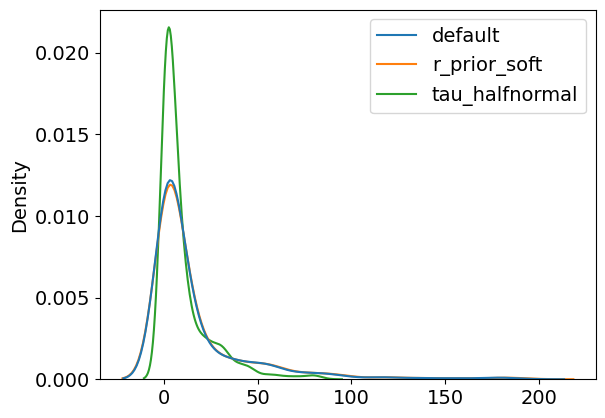

In [620]:
sns.kdeplot(aa[aa.max(axis=1)<200])

In [ ]:
norm.pdf()

In [24]:
df = pd.concat(gammas,axis=1)
df.columns = [os.path.basename(i) for i in prefix]

(-4.0, 20.0)

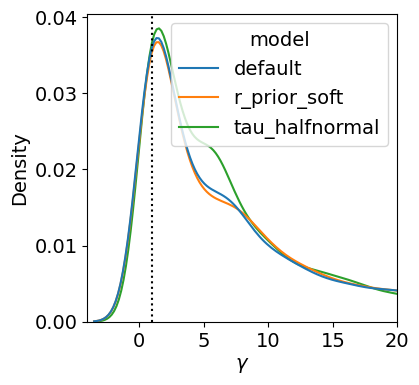

In [26]:
f,ax = plt.subplots(figsize=(4,4))
etas = df.melt(var_name='model',value_name=r'$\gamma$')
sns.kdeplot(data=etas[etas[r'$\gamma$']<30],x=r'$\gamma$',hue='model')
plt.axvline(1,c='black',ls=':')
plt.xlim(-4,20)

In [27]:
import json
diag = []
for pref in prefix:
    with open(pref+"_diagnostics.json") as f:
        res = json.load(f)
        diag.append(pd.Series(res))

diag = pd.concat(diag,axis=1)
diag.columns = map(os.path.basename,prefix)

<Axes: xlabel='value', ylabel='Density'>

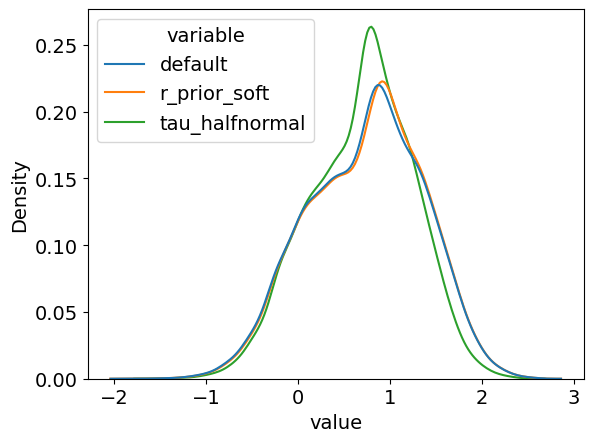

In [29]:
sns.kdeplot(data=np.log10(df).melt(),x='value',hue='variable')

In [30]:
data = pd.read_csv(prefix[0]+'_gamma.tsv',sep='\t')
data['gamma_emp'] = hf.psir2gamma(data.ctrl_psi,data.exp_psi)
data['gamma_i'] = df['default'].tolist()

(-1.9590190906354632, 2.7826819474873563)

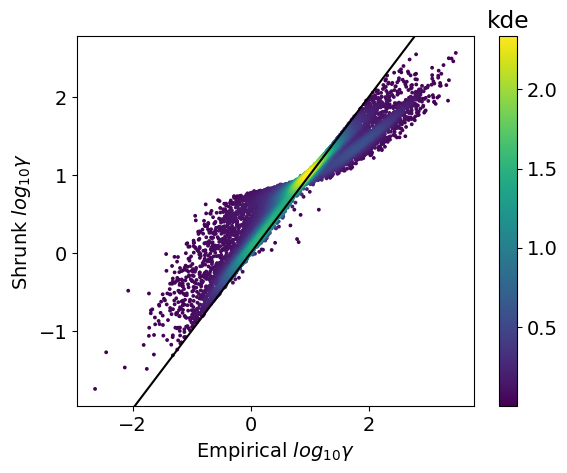

In [31]:
f,ax = plt.subplots()
x,y = data.gamma_emp.to_numpy(),data.gamma_i.to_numpy()
x,y = np.log10(x),np.log10(y)

z,idx = hf.plot2d(x,y)
im = ax.scatter(x[idx],y[idx],c=z[idx],s=3)
cbar = plt.colorbar(im)
cbar.ax.set_title('kde')
ax.set_xlabel(r'Empirical $log_{10} \gamma$')
ax.set_ylabel(r'Shrunk $log_{10} \gamma$')
xl,yl = ax.get_xlim(),ax.get_ylim()
ax.plot([-1000,1000],[-1000,1000],c='black')
ax.set_xlim(*xl)
ax.set_ylim(*yl)

Text(0.5, 0, '$\\log_{10} \\gamma$')

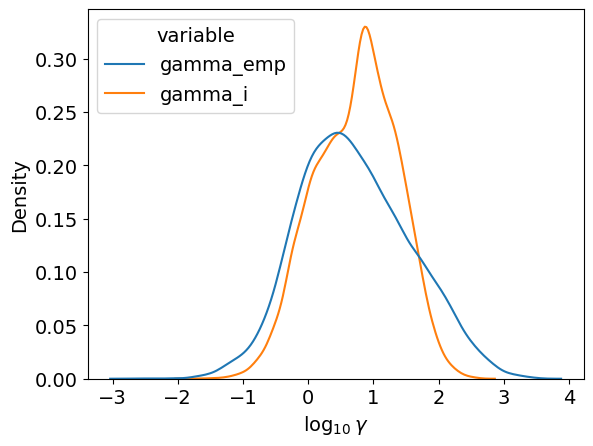

In [32]:
sns.kdeplot(data=np.log10(data[['gamma_emp','gamma_i']]).melt(),x='value',hue='variable')
plt.xlabel(r'$\log_{10} \gamma$')

In [201]:
data

,src,event_id,experiment,ctrl_psi,exp_psi,ctrl_denom,exp_denom,file,pval,gamma_i,gamma_emp
0,cassette,ENSG00000001629_13,HeLa_dKD,0.005236,0.002939,92.25,212.5,hela_chx_and_kd,8.012108e-01,2.781346,0.560035
1,cassette,ENSG00000003756_6,HeLa_dKD,0.018606,0.032055,107.00,370.5,hela_chx_and_kd,4.864818e-01,2.496469,1.746745
2,cassette,ENSG00000004478_0,HeLa_dKD,0.004245,0.329327,452.00,358.0,hela_chx_and_kd,3.213952e-45,97.037057,115.197376
3,cassette,ENSG00000004534_0,HeLa_dKD,0.001967,0.007817,168.75,316.5,hela_chx_and_kd,4.873374e-01,6.839829,3.997432
4,cassette,ENSG00000005436_9,HeLa_dKD,0.003508,0.512608,31.75,113.5,hela_chx_and_kd,2.026237e-19,64.739206,298.731958
...,...,...,...,...,...,...,...,...,...,...,...
10656,nmdj_novel,ENSG00000120913.24_6,HeLa_dKD,0.983611,0.967846,162.75,135.5,hela_chx_and_kd,1.956363e-01,0.416063,0.501554
10657,nmdj_novel,ENSG00000170412.18_3,HeLa_dKD,0.993149,0.970432,64.00,93.5,hela_chx_and_kd,4.747710e-01,0.299097,0.226396
10658,nmdj_novel,ENSG00000213413.3_1,HeLa_dKD,0.988732,0.168947,21.25,27.5,hela_chx_and_kd,2.448447e-18,0.018051,0.002317
10659,nmdj_novel,ENSG00000088833.18_0,HeLa_dKD,0.007770,0.005773,36.00,52.0,hela_chx_and_kd,9.153979e-01,4.152588,0.741456


#### Other datasets (default mode only)

In [148]:
python = r'C:\Users\zavil\miniconda3\envs\pymc\python.exe'
script = './fit_bayes_new.py'

experiment = 'fractioning_HepG2'

cmd1 = f'''{python} -u {script} \
--data "./nmd_inactivation_data/united_use_master_table.tsv" \
--experiment {experiment} \
--prefix "./nmd_inactivation_data/bayes/{experiment}/default"
'''
print(cmd1)

C:\Users\zavil\miniconda3\envs\pymc\python.exe -u ./fit_bayes_new.py --data "./nmd_inactivation_data/united_use_master_table.tsv" --experiment fractioning_HepG2 --prefix "./nmd_inactivation_data/bayes/fractioning_HepG2/default"



In [134]:
good_data

['RIPiT',
 'HeLa_chx',
 'HeLa_SMG6_KD',
 'HeLa_UPF1_KD',
 'HeLa_dKD',
 'fractioning_HepG2',
 'fractioning_K562']

In [135]:
experiment = 'RIPiT'

cmd1 = f'''{python} -u {script} \
--data "./nmd_inactivation_data/united_use_master_table.tsv" \
--experiment {experiment} \
--prefix "./nmd_inactivation_data/bayes/{experiment}/default"
'''
print(cmd1)

run2 = BackgroundMCMC(
    cmd1,
    title=f"{experiment}, default",
    update_interval=5
)

run2.start()

C:\Users\zavil\miniconda3\envs\pymc\python.exe -u ./fit_bayes_new.py --data "./nmd_inactivation_data/united_use_master_table.tsv" --experiment RIPiT --prefix "./nmd_inactivation_data/bayes/RIPiT/default"



In [136]:
experiment = 'HeLa_chx'

cmd1 = f'''{python} -u {script} \
--data "./nmd_inactivation_data/united_use_master_table.tsv" \
--experiment {experiment} \
--prefix "./nmd_inactivation_data/bayes/{experiment}/default"
'''
print(cmd1)

run2 = BackgroundMCMC(
    cmd1,
    title=f"{experiment}, default",
    update_interval=5
)

run2.start()

C:\Users\zavil\miniconda3\envs\pymc\python.exe -u ./fit_bayes_new.py --data "./nmd_inactivation_data/united_use_master_table.tsv" --experiment HeLa_chx --prefix "./nmd_inactivation_data/bayes/HeLa_chx/default"



In [137]:
experiment = 'HeLa_SMG6_KD'

cmd1 = f'''{python} -u {script} \
--data "./nmd_inactivation_data/united_use_master_table.tsv" \
--experiment {experiment} \
--prefix "./nmd_inactivation_data/bayes/{experiment}/default"
'''
print(cmd1)

run3 = BackgroundMCMC(
    cmd1,
    title=f"{experiment}, default",
    update_interval=5
)

run3.start()

C:\Users\zavil\miniconda3\envs\pymc\python.exe -u ./fit_bayes_new.py --data "./nmd_inactivation_data/united_use_master_table.tsv" --experiment HeLa_SMG6_KD --prefix "./nmd_inactivation_data/bayes/HeLa_SMG6_KD/default"



In [138]:
experiment = 'HeLa_UPF1_KD'

cmd1 = f'''{python} -u {script} \
--data "./nmd_inactivation_data/united_use_master_table.tsv" \
--experiment {experiment} \
--prefix "./nmd_inactivation_data/bayes/{experiment}/default"
'''
print(cmd1)

run2 = BackgroundMCMC(
    cmd1,
    title=f"{experiment}, default",
    update_interval=5
)

run2.start()

C:\Users\zavil\miniconda3\envs\pymc\python.exe -u ./fit_bayes_new.py --data "./nmd_inactivation_data/united_use_master_table.tsv" --experiment HeLa_UPF1_KD --prefix "./nmd_inactivation_data/bayes/HeLa_UPF1_KD/default"



In [139]:
experiment = 'fractioning_HepG2'

cmd1 = f'''{python} -u {script} \
--data "./nmd_inactivation_data/united_use_master_table.tsv" \
--experiment {experiment} \
--prefix "./nmd_inactivation_data/bayes/{experiment}/default"
'''
print(cmd1)

run4 = BackgroundMCMC(
    cmd1,
    title=f"{experiment}, default",
    update_interval=5
)

run4.start()

C:\Users\zavil\miniconda3\envs\pymc\python.exe -u ./fit_bayes_new.py --data "./nmd_inactivation_data/united_use_master_table.tsv" --experiment fractioning_HepG2 --prefix "./nmd_inactivation_data/bayes/fractioning_HepG2/default"



In [140]:
experiment = 'fractioning_K562'

cmd1 = f'''{python} -u {script} \
--data "./nmd_inactivation_data/united_use_master_table.tsv" \
--experiment {experiment} \
--prefix "./nmd_inactivation_data/bayes/{experiment}/default"
'''
print(cmd1)

run5 = BackgroundMCMC(
    cmd1,
    title=f"{experiment}, default",
    update_interval=5
)

run5.start()

C:\Users\zavil\miniconda3\envs\pymc\python.exe -u ./fit_bayes_new.py --data "./nmd_inactivation_data/united_use_master_table.tsv" --experiment fractioning_K562 --prefix "./nmd_inactivation_data/bayes/fractioning_K562/default"



#### Compile gamma_i for all datasets

In [322]:
import arviz as az
res = []
parent_dir = './nmd_inactivation_data/bayes_nonzero/'
for name in os.listdir(parent_dir):
    prefix = os.path.join(parent_dir, name)
    file = f'{prefix}/default_params.tsv'
    df = pd.read_csv(file,sep='\t')
    t = df[df.param=='tau_eta']
    if len(t)>0:
        tau = t.iloc[0,0]
    else:
        trace = az.from_netcdf(prefix+'/default.nc')
        tau = trace.constant_data.tau_eta.values
        del trace
    t = df[df.param=='mu_eta']
    mu = t.iloc[0,0] if len(t)>0 else np.nan
    gamma  = np.exp(mu + tau * df[df.param.str.startswith('eta_raw')]['mean']).tolist()
    data = pd.read_csv(prefix+'/default_gamma.tsv',sep='\t')
    data['gamma_i'] = gamma
    res.append(data)

res = pd.concat(res)
res['gamma_emp'] = hf.psir2gamma(res.ctrl_psi,res.exp_psi)

In [323]:
aa = res[res.experiment=='HeLa_dKD'].gamma_i
pd.cut(aa,[0,5,10,50,np.inf]).value_counts()

gamma_i
(0.0, 5.0]      1806
(10.0, 50.0]    1078
(5.0, 10.0]      948
(50.0, inf]       91
Name: count, dtype: int64

<Axes: xlabel='gamma_i', ylabel='Density'>

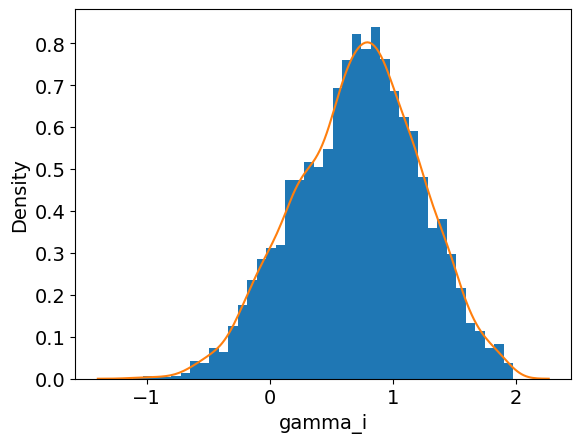

In [324]:
plt.hist(np.log10(aa[aa<100]),bins=40,density=True)
sns.kdeplot(np.log10(aa[aa<100]))

In [325]:
res.to_csv('./nmd_inactivation_data/united_use_master_table_with_gamma_i.tsv',sep='\t',index=False)

#### Phase portrait

In [712]:
#experiment = 'fractioning_K562'
experiment = 'HeLa_dKD'
prefix = f'./nmd_inactivation_data/bayes_nonzero/{experiment}/default'
file = f'{prefix}_params.tsv'
df = pd.read_csv(file,sep='\t')
t = df[df.param=='tau_eta']
trace = az.from_netcdf(prefix+'.nc')
if len(t)>0:
    tau = t.iloc[0,0]
else:
    tau = trace.constant_data.tau_eta.values
t = df[df.param=='mu_eta']
mu = t.iloc[0,0] if len(t)>0 else np.nan
gamma  = np.exp(mu + tau * df[df.param.str.startswith('eta_raw')]['mean']).tolist()
data = pd.read_csv(prefix+'_gamma.tsv',sep='\t')
data['gamma_i'] = gamma

In [713]:
data['r_true'] = df[df.param.str.startswith('r_true')]['mean'].tolist()

In [714]:
data['psi_true'] = hf.r2psi(data.r_true,data.gamma_i)

In [715]:
'ctrl_psi', 'exp_psi', 'psi_true', 'r_true'

('ctrl_psi', 'exp_psi', 'psi_true', 'r_true')

In [716]:
data.columns

Index(['src', 'event_id', 'experiment', 'ctrl_psi', 'exp_psi', 'ctrl_denom',
       'exp_denom', 'file', 'gamma_i', 'r_true', 'psi_true'],
      dtype='object')

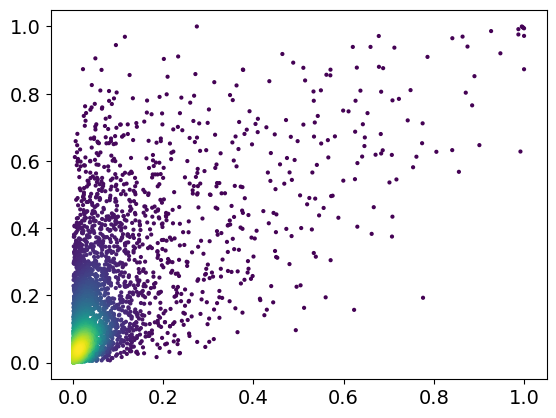

In [717]:
x,y = data.ctrl_psi.to_numpy(),data.exp_psi.to_numpy()
z,idx = hf.plot2d(x,y)
plt.scatter(x[idx],y[idx],c=z[idx],s=4,alpha=1)

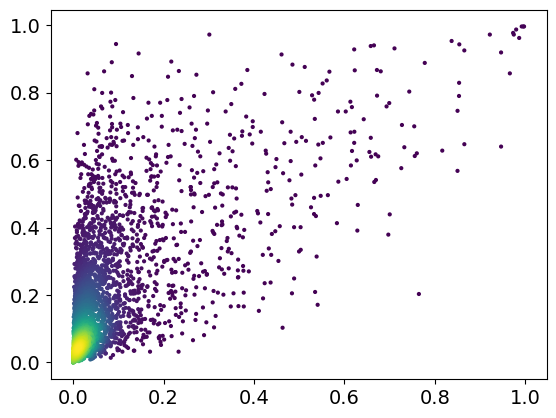

In [718]:
x,y = data.psi_true.to_numpy(),data.r_true.to_numpy()
z,idx = hf.plot2d(x,y)
plt.scatter(x[idx],y[idx],c=z[idx],s=4,alpha=1)

In [719]:
def vector_field(df,bins=50,x1='ctrl_psi',y1='exp_psi',x2='psi_true',y2='r_true',ax=None,absolute=False):
    data = df.copy()
    data['binx'] = pd.cut(data[x1],np.linspace(0,1,bins+1))
    data['biny'] = pd.cut(data[y1],np.linspace(0,1,bins+1))
    data['xdelta'] = data[x2]-data[x1]
    data['ydelta'] = data[y2]-data[y1]
    data['vec_len'] = np.sqrt(data.xdelta**2+data.ydelta**2)
    data = data.groupby(['binx','biny'],observed=True,sort=False)[['vec_len','xdelta','ydelta']].agg('mean').reset_index()
    data[['binx','biny']] = data[['binx','biny']].map(lambda x: x.mid)
    if absolute:
        data['scale'] = data.vec_len/np.sqrt(data.xdelta**2+data.ydelta**2)
        data[['xdelta','ydelta']] = data[['xdelta','ydelta']].mul(scale,axis=0)
    
    if ax is None:
        f,ax = plt.subplots(figsize=(5,5))
        ax.axis('equal')
    ax.quiver(
        data.binx, data.biny, data.xdelta, data.ydelta,
        angles='xy',
        scale_units='xy',
        scale=1,
        color='black',
        alpha=0.7
    )    
    return ax,data

In [720]:
np.exp(mu)

5.306858284582745

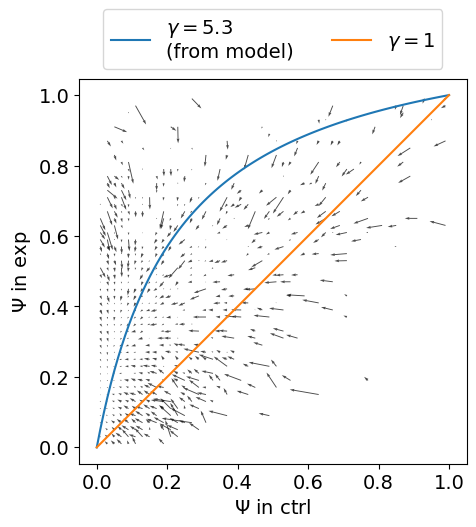

In [721]:
f,ax1 = plt.subplots(figsize=(5,5))
_,aa = vector_field(data,ax=ax1,bins=50)

x = np.linspace(0,1,100)
y = hf.psi2r(x,np.exp(mu))
ax1.plot(x,y,label=f"$\gamma={np.exp(mu):.2g}$\n(from model)")
ax1.plot([0,1],[0,1],label="$\gamma=1$")
ax1.axis('equal')
ax1.set_xlabel('$\Psi$ in ctrl')
ax1.set_ylabel('$\Psi$ in exp')
ax1.legend(loc='lower center',ncol=2,bbox_to_anchor=(0.5,1))

<Axes: xlabel='gamma_i', ylabel='Density'>

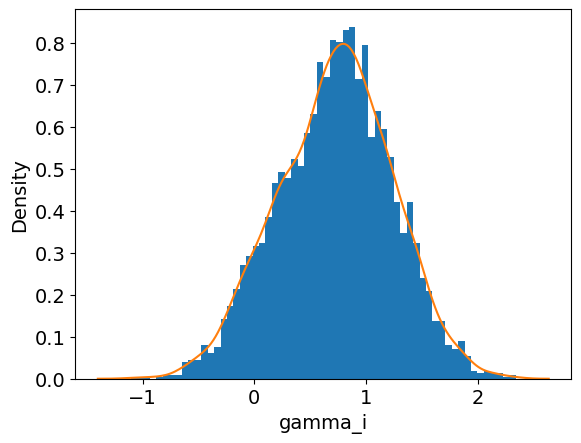

In [345]:
plt.hist(np.log10(data[data.gamma_i<1000].gamma_i),bins=60,density=True)
sns.kdeplot(np.log10(data[data.gamma_i<1000].gamma_i))

### Plotting (default mode)

In [1003]:
GAMMA = 'gamma_emp'

In [1004]:
responders = pd.read_csv('./nmd_inactivation_data/united_use_master_table_with_responder_prob_anno.tsv',sep='\t')
condition = (responders.exp_psi>0.05)&(responders.prob>0.5)
responders['responder'] = np.where(condition,'R','NR')

In [1005]:
gamma = pd.read_csv('./nmd_inactivation_data/united_use_master_table_with_gamma_i.tsv',sep='\t')
gamma = gamma[(gamma.ctrl_psi!=0)&(gamma.exp_psi!=0)].copy()
#gamma = pd.read_csv('./nmd_inactivation_data/united_use_master_table_PE_and_EE_with_gamma_i.tsv',sep='\t')
gamma.experiment = replace(gamma.experiment)

<Axes: xlabel='gamma_emp', ylabel='Density'>

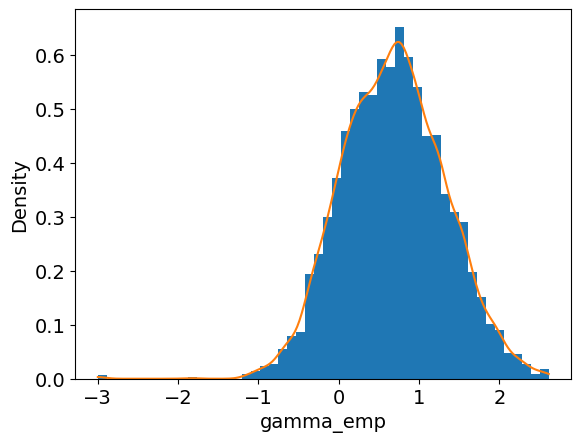

In [1006]:
f,ax = plt.subplots()
aa = gamma[(gamma.experiment=='HeLa dKD')&(np.isfinite(gamma[GAMMA]))][GAMMA]
#aa = aa[aa<20]
aa = np.log10(aa+0.001)
plt.hist(aa,density=True,bins=50)
sns.kdeplot(aa,bw_adjust=0.8,cut=0,ax=ax)
#plt.axvline(0.38)
#plt.axvline(point,c='red')
#plt.axvline(0.8)

In [1007]:
resp = gamma.merge(responders)

In [1008]:
resp.experiment.unique()

array(['HepG2 nucl/cyto', 'K562 nucl/cyto', 'HeLa CHX', 'HeLa dKD',
       'HeLa SMG6 KD', 'HeLa UPF1 KD'], dtype=object)

In [1009]:
resp = resp[(resp.ctrl_psi!=0)&(resp.exp_psi!=0)]

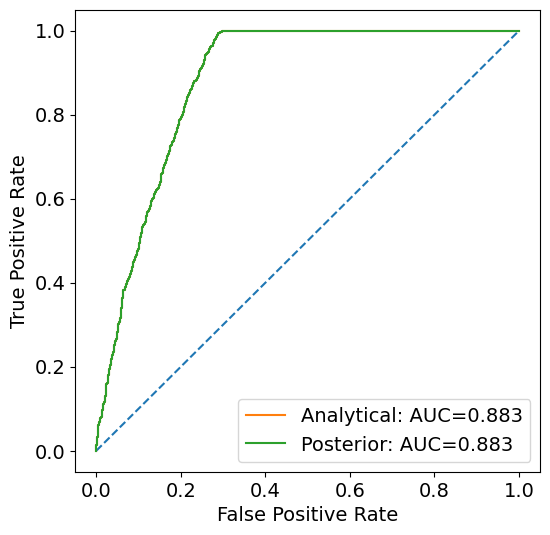

In [1010]:
from sklearn.metrics import roc_curve, roc_auc_score

aa = resp[np.isfinite(resp.gamma_emp)&(resp.experiment=='HeLa dKD')]
y_true = aa.responder=='R'
y_score = aa[GAMMA]
y_score2 = aa.gamma_emp

plt.figure(figsize=(6,6))
plt.plot([0,1], [0,1], linestyle="--")
for y_score,name in zip([y_score2,y_score],['Analytical','Posterior']):
    fpr, tpr, thresholds = roc_curve(y_true, y_score)
    auc = roc_auc_score(y_true, y_score)
    plt.plot(fpr, tpr, label=f"{name}: AUC={auc:.3f}")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.legend()

plt.show()

#### Scatter with gamma_i and densities

In [1011]:
catalog = pd.read_csv('./use_catalog/filtered_catalog.tsv',sep='\t')
cat = catalog[['gene_id','src','event_id']].drop_duplicates()

C:\Users\zavil\miniconda3\envs\py310\lib\site-packages\pandas\core\internals\blocks.py:395: RuntimeWarning: divide by zero encountered in log10
  result = func(self.values, **kwargs)


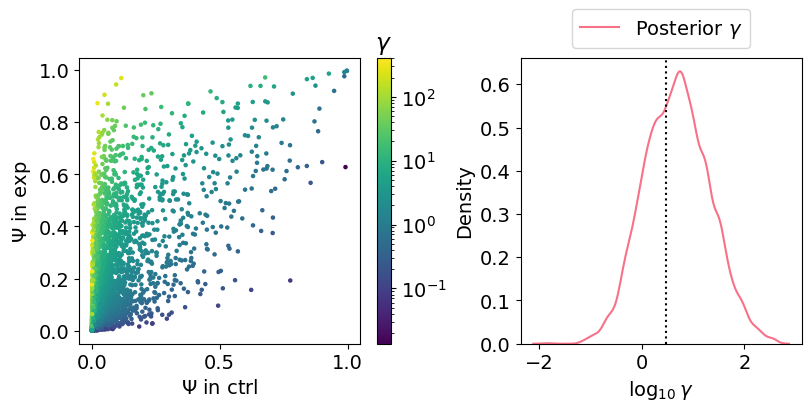

In [1012]:
import matplotlib.pyplot as plt
import matplotlib.colors as colors

f, (ax,ax2) = plt.subplots(1,2,figsize=(8,4),constrained_layout=True,width_ratios=(1,1))

tmp = gamma[gamma.experiment=='HeLa dKD']

im = ax.scatter(
    tmp.ctrl_psi,
    tmp.exp_psi,
    c=tmp[GAMMA],
    s=5,
    norm=colors.LogNorm()
)

xl = ax.get_xlim()
yl = ax.get_ylim()

cbar = plt.colorbar(im, ax=ax)
cbar.ax.set_title(r'$\gamma$')

ax.set_xlabel(r'$\Psi$ in ctrl')
ax.set_ylabel(r'$\Psi$ in exp')
#ax.axis('equal')

melted = np.log10(tmp[['gamma_emp',GAMMA]]).melt()
melted.variable = melted.variable.map({'gamma_emp':r'Analytical $\gamma$',GAMMA:r'Posterior $\gamma$'})
sns.kdeplot(data=melted,x='value',hue='variable',ax=ax2,palette="husl",bw_adjust=0.8)
leg = ax2.get_legend()
leg.set_title(None)
leg.set_loc('lower center')
leg.set_bbox_to_anchor((0.5,1))
#ax2.legend(title=None,loc='lower center',bbox_to_anchor=(0.5,1))
ax2.set_xlabel(r'$\log_{10} \gamma$')
ax2.axvline(np.log10(3),ls=':',c='black')


In [1013]:
f.savefig('./figures/Fig4_scatter_and_kde.pdf',bbox_inches='tight')

In [1014]:
nmdpsi = pd.read_csv('./nmd_inactivation_data/united_use_master_table.tsv',sep='\t')
sets = pd.read_csv('./nmd_kd_experimental/USE_sets.tsv',sep='\t')

In [1015]:
tmp = sets[sets.set2==1].merge(nmdpsi[nmdpsi.experiment=='HeLa_dKD'])

In [1016]:
tmp.to_csv('./nmd_inactivation_data/united_use_master_table_PE_and_EE.tsv',sep='\t',index=False)

#### Psi ~ expr corcoef in GTEx

In [1017]:
from scipy.stats import spearmanr

In [661]:
%%time
import pickle
with open('psi_expression_gtex.pkl', "rb") as f:
    psi = pickle.load(f)

CPU times: total: 7.22 s
Wall time: 7.92 s


In [662]:
catalog[['src','event_id']].drop_duplicates().src.value_counts()

src
ensembl    10825
chess       3728
Name: count, dtype: int64

In [663]:
psi['psi'] = psi.num/psi.denom

In [664]:
%%time

res = []
i=0

import time
start_time = time.time()
for key,tmp in psi[(psi.psi!=0)&(psi.expr.notna())].groupby(['src','event_id']):
    i+=1
    if i%10000==1:
        print(f'Done {i}',time.time()-start_time)
    if len(tmp)<40:
        continue
    if np.std(tmp.psi)==0:
        continue
    r,p = spearmanr(tmp.expr,tmp.psi,nan_policy='omit')
    res.append([*key,r,p])
res = pd.DataFrame(res,columns=['src','event_id','r','p'])
!mkdir gtex
res.to_csv('./gtex/cor_expr_vs_psi_gtex_all_tissues_nozero.csv')

<timed exec>:6: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.


Done 1 5.9389777183532715
Done 10001 85.87917184829712
CPU times: total: 1min 32s
Wall time: 1min 33s


A subdirectory or file gtex already exists.


In [1018]:
res = []

In [666]:
psi['dthr'] = (psi.denom>15).astype(int)
psi['psi'] = psi.num/psi.denom
meanpsi = psi.groupby(['src','event_id'],observed=True).agg({'psi':['mean','std'],'dthr':'mean'})
meanpsi.columns = ['psi','psi_std','dthr']
meanpsi = meanpsi.reset_index()

meanpsi['cv'] = meanpsi.psi_std/meanpsi.psi

In [1019]:
coefs = pd.read_csv('./gtex/cor_expr_vs_psi_gtex_all_tissues_nozero.csv',index_col=[0])

In [1020]:
df = coefs.merge(resp).merge(meanpsi)

In [1021]:
pthr = 1 #not important
stdthr = 0
cvthr = 1 #important
psithr = 0.01 #important
dthr = 0.6

formula = 'r ~ psi_z + responder'
formula2 = 'r ~ psi_z + gamma_i_z'
tmp = df[(df.experiment=='HeLa dKD')&(df.p<pthr)&(df.psi_std>stdthr)&(df.cv>cvthr)&(df.psi>psithr)&(df.dthr>dthr)].copy()
tmp['gamma_i_z'] = np.log(tmp[GAMMA])
tmp.gamma_i_z = (tmp.gamma_i_z-np.mean(tmp.gamma_i_z))/np.std(tmp.gamma_i_z)
tmp['psi_z'] = (tmp.psi-np.mean(tmp.psi))/np.std(tmp.psi)
print(tmp.shape)
hf.get_ols_res(formula,tmp)

(1507, 20)


,coef,std_err,t,p_value,ci_lower,ci_upper,adj_R,F_pval
Intercept,-0.346957,0.008683,-39.956351,1.547956e-238,-0.363990,-0.329924,0.048025,3.106888e-17
responder[T.R],-0.031574,0.011067,-2.852929,4.391106e-03,-0.053282,-0.009865,0.048025,3.106888e-17
psi_z,0.045387,0.005383,8.431415,7.890099e-17,0.034828,0.055947,0.048025,3.106888e-17


In [1022]:
hf.get_ols_res(formula2,tmp)

,coef,std_err,t,p_value,ci_lower,ci_upper,adj_R,F_pval
Intercept,-0.366400,0.005373,-68.188979,0.000000e+00,-0.376939,-0.355860,0.050792,3.481800e-18
psi_z,0.043354,0.005393,8.039501,1.809284e-15,0.032776,0.053932,0.050792,3.481800e-18
gamma_i_z,-0.019101,0.005393,-3.542121,4.090433e-04,-0.029679,-0.008523,0.050792,3.481800e-18


In [1023]:
catalog = pd.read_csv('./use_catalog/filtered_catalog.tsv',sep='\t')
cat = catalog[['src','event_id','gene_id','event_type']].drop_duplicates().copy()

In [1024]:
tmp = tmp.merge(cat)

In [1025]:
tmp['psi_bin'] = pd.qcut(tmp.psi,5)
tmp['coef_sign'] = (tmp.r>0).map({True:1,False:-1})

In [1026]:
tmp[GAMMA].describe()

count    1507.000000
mean       15.102416
std        31.523685
min         0.013609
25%         2.098804
50%         5.556579
75%        15.008517
max       356.818182
Name: gamma_emp, dtype: float64

In [1027]:
def p2star(p):
    thrs = [0.0001,0.001,0.01,0.05,0.1]
    star = ['****','***','**','*','·']
    for t,s in zip(thrs,star):
        if p<t:
            return s
    return ""

def add_N(col,sep='\n',brac=True):
    d = col.value_counts()
    if brac:
        d = {k:f'{k}{sep}$(n={v})$'  for k,v in d.items()}
    else:
        d = {k:f'{k}{sep}$n={v}$'  for k,v in d.items()}
    return col.map(d)

In [1028]:
tmp.responder.value_counts()

responder
R     928
NR    579
Name: count, dtype: int64

p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

R
$n=928$ vs. NR
$n=579$: Mann-Whitney-Wilcoxon test two-sided, P_val:1.460e-02 U_stat=2.486e+05


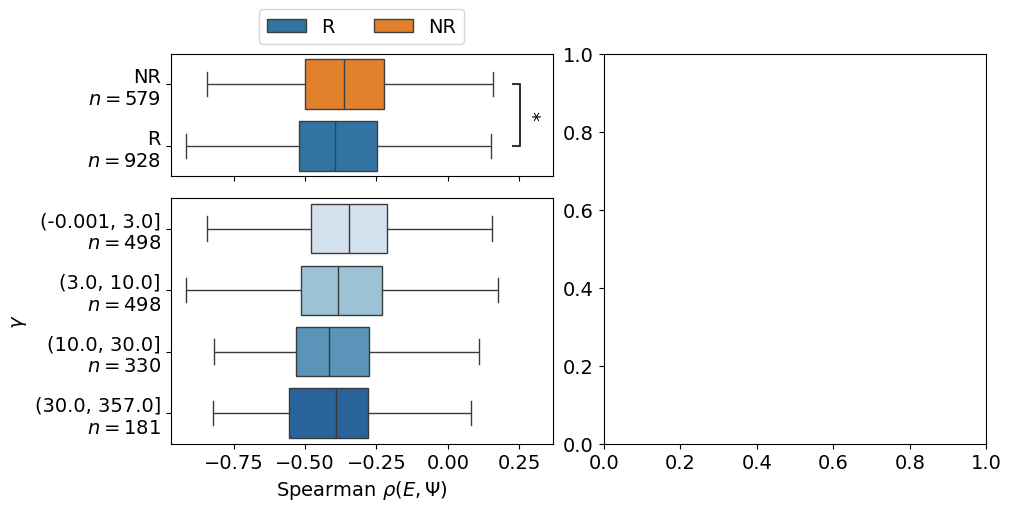

In [1031]:
tmp2 = tmp.copy()

bins = [0,3,10,30,int(max(tmp2[GAMMA]))+1]

if GAMMA == 'gamma_i':
    tmp2['gamma_bin'] = pd.cut(
        tmp2[GAMMA],
        bins
    )
else:
    tmp2['gamma_bin'] = pd.cut(
        tmp2[GAMMA],
        bins,
        include_lowest=True
    )

tmp2.responder = add_N(tmp2.responder, sep='\n', brac=False)
tmp2.gamma_bin = add_N(tmp2.gamma_bin, sep='\n', brac=False)
tmp2 = tmp2.sort_values('responder', ascending=False)


def jitter(ax, width):
    for l in ax.lines:
        if l.get_marker() != '':
            xs = l.get_xdata()
            xs += np.random.uniform(-width, width, len(xs))
            l.set_xdata(xs)


flierprops = {'marker': '.', 'ms': 3}
showfliers = False


f, axes = plt.subplot_mosaic(
    """
    AC
    BC
    """,
    layout="constrained",
    figsize=(10,5),
    width_ratios=(1,1),
    height_ratios=(1, 2),
)

ax1, ax2 = axes['A'], axes['B']

ax2.sharex(ax1)
ax1.tick_params(labelbottom=False)

# ------------------------
# responder comparison
# ------------------------
sns.boxplot(
    data=tmp2,
    x='r',
    y='responder',
    ax=ax1,
    hue='responder',
    legend=True,
    flierprops=flierprops,
    showfliers=showfliers,
    orient='h'
)

# ------------------------
# gamma bins
# ------------------------
sns.boxplot(
    data=tmp2,
    x='r',
    y='gamma_bin',
    hue='gamma_bin',
    palette='Blues',
    flierprops=flierprops,
    showfliers=showfliers,
    ax=ax2,
    legend=False,
    orient='h'
)
h,l = ax1.get_legend_handles_labels()

ax1.legend(handles=h,labels=[i.split('\n')[0] for i in l],ncol=2,loc='lower center',bbox_to_anchor=(0.5,1))

for ax in [ax1,ax2]:
    ax.set_xlabel(None)
    jitter(ax, 0.05)

ax2.set_xlabel(r'Spearman $\rho(E,\Psi)$')

# ========================
# Statistical annotation
# ========================

from statannotations.Annotator import Annotator

pairs = [tuple(tmp2.responder.unique())]

annotator = Annotator(
    ax1,
    pairs,
    data=tmp2,
    y="responder",
    x="r",
    orient='h'
)

annotator.configure(
    test="Mann-Whitney",
    text_format="star",
    loc="inside"
)

annotator.apply_and_annotate()

ax1.set_ylabel(None)
ax2.set_ylabel(r'$\gamma$')

# если нужен прежний порядок категорий
ax1.invert_yaxis()

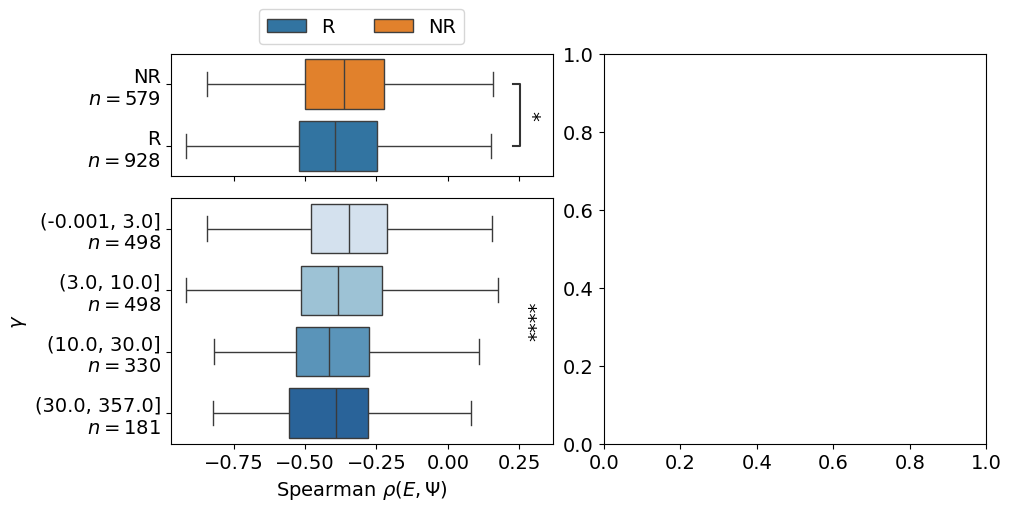

In [1032]:
formula = 'r ~ gamma_i_z'
df = hf.get_ols_res(formula, tmp2)

p = df.loc['gamma_i_z', 'p_value']
star = p2star(p)

star_text = ax1.texts[0]

# координаты текста в ЕГО собственной системе
x, y = star_text.get_position()
x_disp, y_disp = star_text.get_transform().transform((x, y))
x2, y2 = ax2.transData.inverted().transform((x_disp, y_disp))

import matplotlib.transforms as transforms

trans2 = transforms.blended_transform_factory(ax2.transData,ax2.transAxes)

ax2.text(x2,0.5,star,ha='left',va='center',rotation=90,transform=trans2)
f

#### logFC vs gamma in NMDKD

In [1033]:
lfc = []
for file in glob.glob('./nmd_inactivation_data/deseq_res/*tsv'):
    if not (("ripit" in file.lower()) or ("fractioning" in file.lower())):
        tmp = pd.read_csv(file,sep='\t',index_col=[0])
        name = 'chx' if 'CHX' in file else os.path.basename(file)[:-4]
        tmp['experiment'] = name
        tmp['gene_id'] = tmp.index
        lfc.append(tmp[['experiment','gene_id','log2FoldChange']])
ripit = pd.read_csv('./nmd_inactivation_data/deseq_res/ripit_gene_logFC.tsv',sep='\t').rename(columns={'logFC':'log2FoldChange'})
ripit = ripit[['experiment','gene_id','log2FoldChange']]
lfc.append(ripit)

frac = pd.read_csv('./nmd_inactivation_data/deseq_res/fractioning_logFC.tsv',sep='\t')
frac = frac[['experiment','gene_id','log2FoldChange']]
lfc.append(frac)

lfc = pd.concat(lfc)

#lfc.experiment = lfc.experiment.replace('hela_chx_24h','HeLa_chx')
#lfc.experiment = lfc.experiment.str.replace('fractioning','frac')
lfc.experiment = replace(lfc.experiment)

In [1034]:
df = resp.merge(cat).merge(lfc).sort_values(GAMMA,ascending=False).drop_duplicates(['experiment','gene_id'])

In [1035]:
fill = max(df.loc[df[GAMMA]!=np.inf,GAMMA])
df[GAMMA] = np.where(df[GAMMA]==np.inf,fill,df[GAMMA])

In [1036]:
bins = [0,3,10,30,int(max(df[GAMMA]))+1]
df['gamma_bin'] = pd.cut(df[GAMMA],bins)

In [1037]:
axes['C'].clear()

In [1038]:
aa = df[(df.exp_psi>0.01)&(df.ctrl_psi>0.01)].groupby('experiment').gamma_bin.value_counts().reset_index()
aa.pivot(index='experiment',columns='gamma_bin').fillna(0).astype(int)

count                           
gamma_bin       (0, 3] (3, 10] (10, 30] (30, 813]
experiment                                       
HeLa CHX           126      75       37        13
HeLa SMG6 KD      1183     466       41         7
HeLa UPF1 KD      1007     576       86         6
HeLa dKD           701     624      332       114
HepG2 nucl/cyto    588     404      199       125
K562 nucl/cyto     784     478      230        70

In [1039]:
resp.experiment.unique()

array(['HepG2 nucl/cyto', 'K562 nucl/cyto', 'HeLa CHX', 'HeLa dKD',
       'HeLa SMG6 KD', 'HeLa UPF1 KD'], dtype=object)

In [1040]:
order = ['HepG2 nucl/cyto','K562 nucl/cyto','HeLa CHX','HeLa dKD','HeLa SMG6 KD','HeLa UPF1 KD']
combs = list(combinations(df.gamma_bin.unique(),2))
pairs = [((i,l1),(i,l2)) for l1,l2 in combs for i in order]

In [1041]:
df[df.gamma_bin.isna()]

,src,event_id,experiment,ctrl_psi,exp_psi,ctrl_denom,exp_denom,file,gamma_i,gamma_emp,prob,responder,gene_id,event_type,log2FoldChange,gamma_bin
6095,ensembl,ENSG00000101901_1,HeLa CHX,1.0,0.596296,16.500000,54.500000,ripit_and_chx,0.077419,0.0,7.807750e-06,NR,ENSG00000101901,A5SS,1.073256,NaN
6157,ensembl,ENSG00000132478_0,HeLa CHX,1.0,0.389749,20.250000,58.250000,ripit_and_chx,0.035869,0.0,4.170778e-13,NR,ENSG00000132478,alt_end,1.498514,NaN
10789,chess,ENSG00000158286_1,HeLa SMG6 KD,1.0,0.977528,34.000000,44.500000,hela_kd,0.569231,0.0,2.916066e-01,NR,ENSG00000158286,IR,0.272852,NaN
6982,chess,ENSG00000158286_1,HeLa dKD,1.0,0.872727,34.000000,36.666667,hela_kd,0.210375,0.0,7.539245e-02,NR,ENSG00000158286,IR,-0.546789,NaN
14345,chess,ENSG00000164975_5,HeLa UPF1 KD,1.0,0.996114,135.166667,257.333333,hela_kd,0.669825,0.0,5.442984e-02,NR,ENSG00000164975,PE|PE2|alt_start,0.886804,NaN
14279,chess,ENSG00000158286_1,HeLa UPF1 KD,1.0,0.908815,34.000000,54.833333,hela_kd,0.354508,0.0,5.065824e-01,R,ENSG00000158286,IR,0.661411,NaN
7294,chess,ENSG00000204681_0,HeLa dKD,1.0,0.994536,19.000000,91.500000,hela_kd,1.162670,0.0,6.676296e-02,NR,ENSG00000204681,EE,1.444695,NaN


In [1042]:
import matplotlib.transforms as transforms
if GAMMA == 'gamma_i':
    df['gamma_bin'] = pd.cut(df[GAMMA],bins)
    #df['gamma_bin'] = pd.qcut(df[GAMMA],4)
else:
    df['gamma_bin'] = pd.cut(df[GAMMA],bins)

tmp = df[(df.exp_psi>0.01)&(df.ctrl_psi>0.01)].copy()
filt = tmp.groupby(['experiment','gamma_bin'],sort=False,observed=True).size()
filt = filt[filt>20].reset_index().merge(tmp)

filt.experiment = filt.experiment.astype('category').cat.reorder_categories(order)
filt.sort_values('experiment')

#f,ax = plt.subplots()
ax = axes['C']
sns.boxplot(data=filt,y='experiment',x='log2FoldChange',hue='gamma_bin',showfliers=False,ax=ax,palette='Blues')
#sns.violinplot(data=filt,y='experiment',x='log2FoldChange',hue='gamma_bin',ax=ax,palette='Blues')
ax.legend(title=r'$\gamma$',loc='lower center', bbox_to_anchor=(0.5,1),ncol=2)
#ax.legend(title=r'$\gamma$')
ax.set_ylabel(None)

ax.axvline(0,ls=':',c='black')

formula = 'r ~ gamma_i_z'
for l in ax.get_yticklabels():
    formula = 'log2FoldChange ~ gamma_i_z'
    key,pos = l._text,l._y
    tmp = df[df.experiment==key].copy()
    tmp['gamma_i_z'] = np.log10(tmp.gamma_i)
    tmp.gamma_i_z = (tmp.gamma_i_z-np.mean(tmp.gamma_i_z))/np.std(tmp.gamma_i_z)
    aa = hf.get_ols_res(formula, tmp)
    p = aa.loc['gamma_i_z', 'p_value']
    star = p2star(p)
    trans = transforms.blended_transform_factory(ax.transAxes,ax.transData)
    ax.text(1.01,pos,star,ha='left',va='center',transform=trans,rotation=90)


In [1043]:
f.axes[1].set_xlabel(r'$\log_2$FC')

Text(0.5, 0, '$\\log_2$FC')

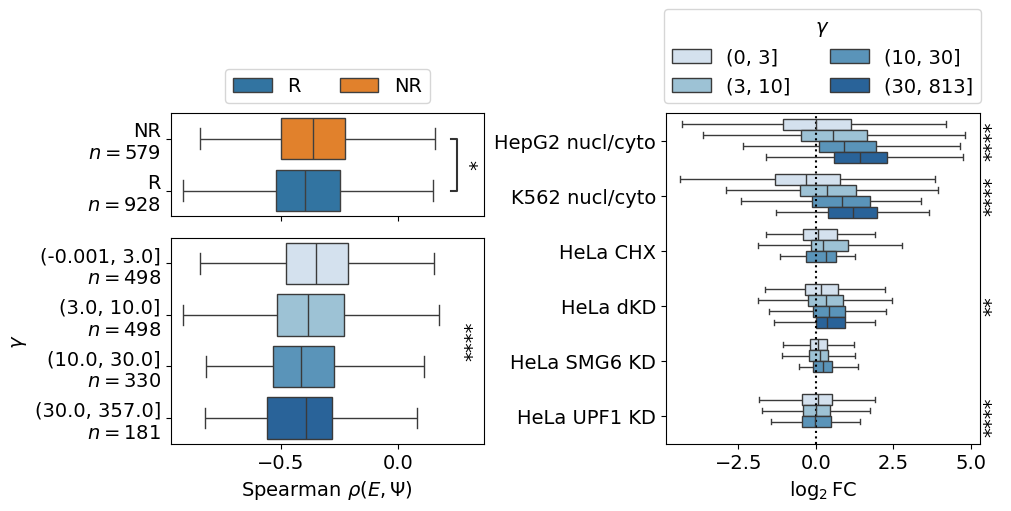

In [1044]:
f

In [1045]:
f.savefig('./figures/Fig4_gtex_and_logFC_in_NMDKD.pdf',bbox_inches='tight')

In [1046]:
tmp = filt[filt.experiment=='HeLa UPF1 KD'].copy()
tmp['gamma_bin'] = pd.qcut(tmp[GAMMA],10)

In [1047]:
len(tmp)//20

83

<Axes: xlabel='log2FoldChange', ylabel='gamma_bin'>

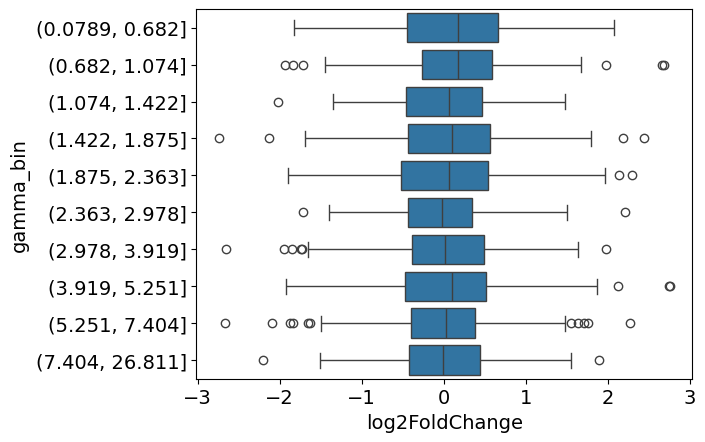

In [932]:
sns.boxplot(data=tmp,y='gamma_bin',x="log2FoldChange")

In [933]:
base = pd.read_csv('./nmd_inactivation_data/deseq_res/HeLa_UPF1_KD.tsv',sep='\t',index_col=[0])

In [934]:
tmp['expr'] = tmp.gene_id.map(base.baseMean)

In [945]:
aa = resp.merge(cat).merge(lfc)
aa = aa[aa.experiment=='HeLa dKD'].gene_id.value_counts()

In [947]:
tmp['use_cnt'] = tmp.gene_id.map(aa)

<Axes: xlabel='expr', ylabel='gamma_bin'>

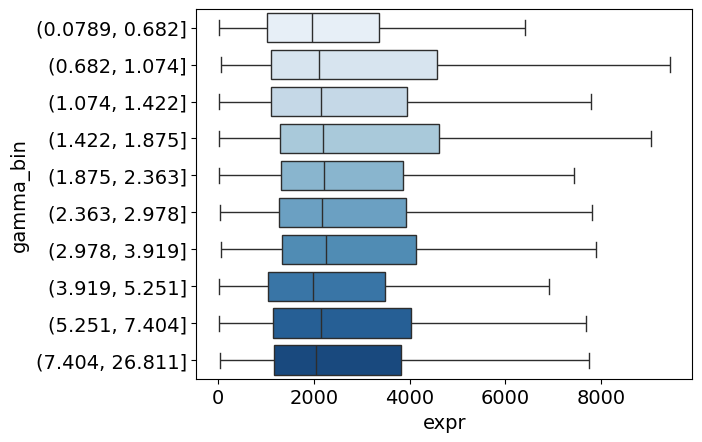

In [948]:
sns.boxplot(data=tmp,y='gamma_bin',x='expr',hue='gamma_bin',showfliers=False,palette='Blues',legend=False)

In [949]:
tmp.groupby('gamma_bin').use_cnt.describe()

C:\Users\zavil\AppData\Local\Temp\ipykernel_4592\2728039579.py:1: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  tmp.groupby('gamma_bin').use_cnt.describe()


,count,mean,std,min,25%,50%,75%,max
gamma_bin,,,,,,,,
"(0.0789, 0.682]",156.0,1.217949,0.593458,1.0,1.0,1.0,1.0,5.0
"(0.682, 1.074]",158.0,1.189873,0.506668,1.0,1.0,1.0,1.0,4.0
"(1.074, 1.422]",154.0,1.331169,0.723600,1.0,1.0,1.0,1.0,6.0
"(1.422, 1.875]",161.0,1.403727,0.736367,1.0,1.0,1.0,2.0,6.0
"(1.875, 2.363]",162.0,1.438272,0.704390,1.0,1.0,1.0,2.0,4.0
"(2.363, 2.978]",163.0,1.601227,0.878691,1.0,1.0,1.0,2.0,5.0
"(2.978, 3.919]",166.0,1.481928,0.799416,1.0,1.0,1.0,2.0,6.0
"(3.919, 5.251]",165.0,1.593939,0.832986,1.0,1.0,1.0,2.0,5.0
"(5.251, 7.404]",162.0,1.543210,0.871201,1.0,1.0,1.0,2.0,5.0


<Axes: xlabel='None-use_cnt', ylabel='gamma_bin'>

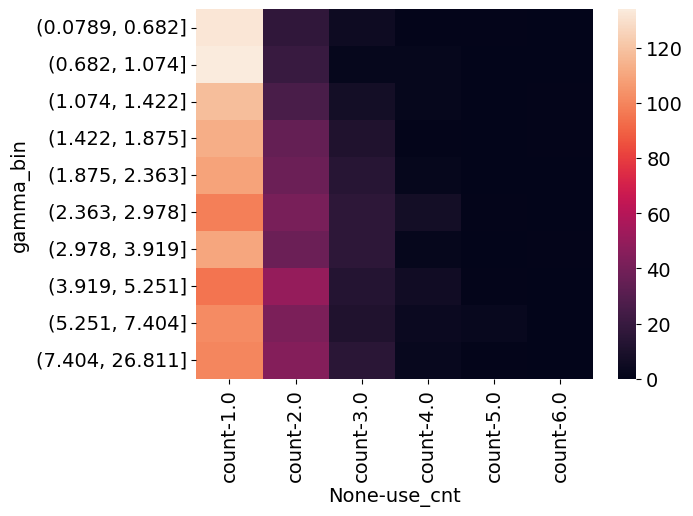

In [950]:
mat = tmp[['gamma_bin','use_cnt']].value_counts().reset_index().pivot(index='gamma_bin',
                                                                      columns='use_cnt').fillna(0).astype(int)
sns.heatmap(mat)

<Axes: xlabel='exp_psi', ylabel='experiment'>

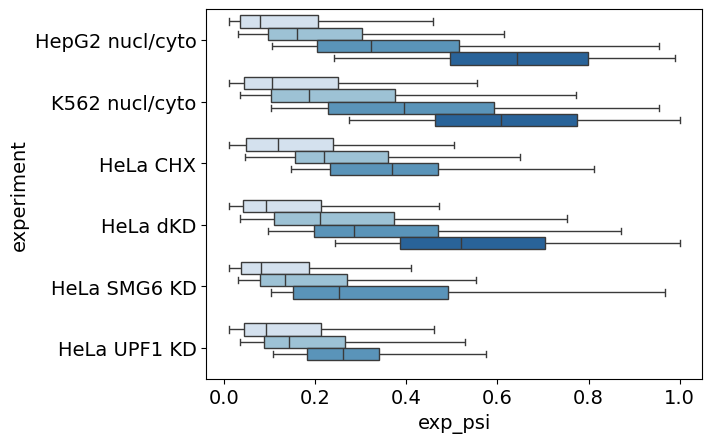

In [951]:
sns.boxplot(data=filt,y='experiment',hue='gamma_bin',x='exp_psi',showfliers=False,palette='Blues',legend=False)

In [413]:
import gseapy as gp

In [415]:
aa = filt[filt.experiment=='HeLa_UPF1_KD']

lst = aa[aa.gamma_bin.cat.codes==2].gene_id.tolist()
bg = aa.gene_id.tolist()
len(lst),len(bg)

(27, 1675)

In [418]:
geneid = pd.read_csv('../../../arkuda_backup/gtfs/geneid.csv')

In [419]:
lst = geneid[geneid.gene_id.isin(lst)&(geneid.gene_name.notna())].gene_name.unique()
bg = geneid[  geneid.gene_id.isin(bg)&(geneid.gene_name.notna())].gene_name.unique()

In [420]:
len(lst),len(bg)

(27, 1671)

In [421]:
enr = gp.enrichr(
    gene_list=list(lst),
    background=list(bg),
    gene_sets=[
        "GO_Biological_Process_2023"
    ],
    organism="Human",
    outdir=None
)


In [422]:
aa = enr.results
bb = aa[aa['Adjusted P-value']<0.05]
for _,row in bb.iterrows():
    print(row.Term)
    print(row.Genes)
    print()

Actin Filament Organization (GO:0007015)
TPM3;WHAMM;MYO19

RNA Splicing (GO:0008380)
TRA2B;SNRPA1;U2AF1;MAGOHB

mRNA Splicing, Via Spliceosome (GO:0000398)
TRA2B;SNRPA1;U2AF1;MAGOHB;PQBP1



In [423]:
len(set.union(*bb.Genes.str.split(';').map(set)))/len(lst)

0.2962962962962963

In [424]:
go_bp = gp.get_library(
    name="GO_Biological_Process_2023",
    organism="Human"
)

In [426]:
df = enr.results.copy()
df["Hits"] = df["Genes"].str.split(";").str.len()
df["GeneRatio"] = (df["Hits"]*100 / len(lst)).astype(int)
df['Overlap'] = df.Hits.astype(str)+f'/{len(lst)}'

In [427]:
sizes = {i:len(go_bp[i]) for i in bb.Term}
df['setsize'] = df.Term.map(sizes)

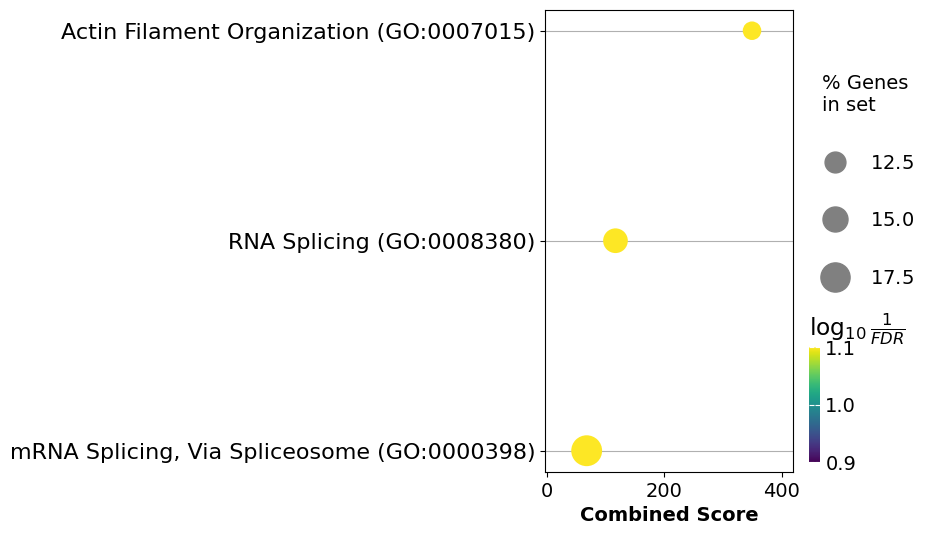

In [429]:
ax = gp.dotplot(df, 
                size=20,
                column="Adjusted P-value",
                cmap='viridis',
                cutoff=0.05)

cax = ax.figure.axes[1]
bbox = cax.get_position()
dy = -0.1
new_bbox = [
    bbox.x0,
    bbox.y0+dy,
    bbox.width,
    bbox.height
]

cax.set_position(new_bbox)

In [430]:
tmp = filt[filt.experiment=='HeLa_UPF1_KD'].copy()

In [438]:
bb

,Gene_set,Term,P-value,Adjusted P-value,Old P-value,Old adjusted P-value,Odds Ratio,Combined Score,Genes
0,GO_Biological_Process_2023,Actin Filament Organization (GO:0007015),0.000200,0.040240,0,0,40.975000,349.018228,TPM3;WHAMM;MYO19
1,GO_Biological_Process_2023,RNA Splicing (GO:0008380),0.000389,0.040240,0,0,14.874142,116.798846,TRA2B;SNRPA1;U2AF1;MAGOHB
2,GO_Biological_Process_2023,"mRNA Splicing, Via Spliceosome (GO:0000398)",0.000586,0.040443,0,0,9.113636,67.823338,TRA2B;SNRPA1;U2AF1;MAGOHB;PQBP1


In [439]:
genes = set.union(*bb.Genes.iloc[1:].str.split(';').map(set))
genes = geneid[geneid.gene_name.isin(genes)].gene_id
tmp['enriched'] = tmp.gene_id.isin(genes).astype(int)

In [440]:
tmp.gamma_bin.unique()

[(10, 30], (3, 10], (0, 3]]
Categories (4, interval[int64, right]): [(0, 3] < (3, 10] < (10, 30] < (30, 224]]

In [441]:
from scipy.stats import mannwhitneyu
mannwhitneyu(*tmp[tmp.gamma_bin.cat.codes==2].groupby('enriched').gamma_i.agg(list))

MannwhitneyuResult(statistic=33.0, pvalue=0.1857054378793509)

In [442]:
mannwhitneyu(*tmp[tmp.gamma_bin.cat.codes==2].groupby('enriched').log2FoldChange.agg(list))

MannwhitneyuResult(statistic=71.0, pvalue=0.34433296172426603)

<Axes: xlabel='gamma_bin', ylabel='log2FoldChange'>

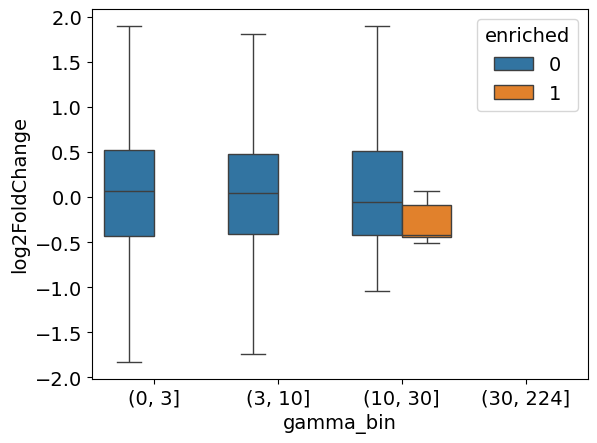

In [443]:
sns.boxplot(data=tmp,x='gamma_bin',y='log2FoldChange',hue='enriched',showfliers=False,dodge=True)

In [920]:
tmp.groupby(['gamma_bin','enriched'],observed=True).log2FoldChange.agg('median')

gamma_bin   enriched
(0, 5]      0          -0.069894
(5, 10]     0           0.151911
(10, 50]    0           0.216103
(50, 2855]  0          -0.004786
            1          -0.364032
Name: log2FoldChange, dtype: float64

<Axes: xlabel='exp_psi', ylabel='experiment'>

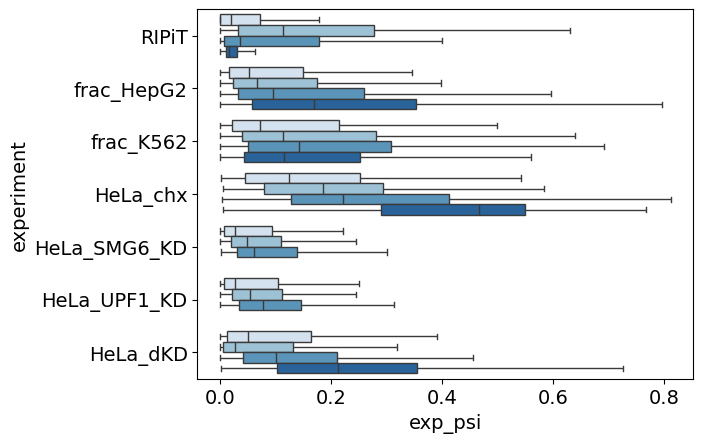

In [764]:
sns.boxplot(data=filt,y='experiment',hue='gamma_bin',x='exp_psi',showfliers=False,palette='Blues',legend=False)

[(Interval(5.0, 2998.0, closed='right'), Interval(-0.001, 5.0, closed='right'))]
p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

chx_(-0.001, 5.0] vs. chx_(5.0, 2998.0]: Mann-Whitney-Wilcoxon test two-sided with Bonferroni correction, P_val:9.420e-29 U_stat=1.776e+06
RIPiT_(-0.001, 5.0] vs. RIPiT_(5.0, 2998.0]: Mann-Whitney-Wilcoxon test two-sided with Bonferroni correction, P_val:1.425e-17 U_stat=4.765e+05
HeLa_SMG6_KD_(-0.001, 5.0] vs. HeLa_SMG6_KD_(5.0, 2998.0]: Mann-Whitney-Wilcoxon test two-sided with Bonferroni correction, P_val:1.000e+00 U_stat=2.447e+06
HeLa_UPF1_KD_(-0.001, 5.0] vs. HeLa_UPF1_KD_(5.0, 2998.0]: Mann-Whitney-Wilcoxon test two-sided with Bonferroni correction, P_val:1.000e+00 U_stat=2.598e+06
HeLa_dKD_(-0.001, 5.0] vs. HeLa_dKD_(5.0, 2998.0]: Mann-Whitney-Wilcoxon test two-sided with Bonferroni correction, P_val:2.008e-10

(<Axes: xlabel='log2FoldChange'>,
  <statannotations.Annotation.Annotation at 0x283b58cb0a0>])

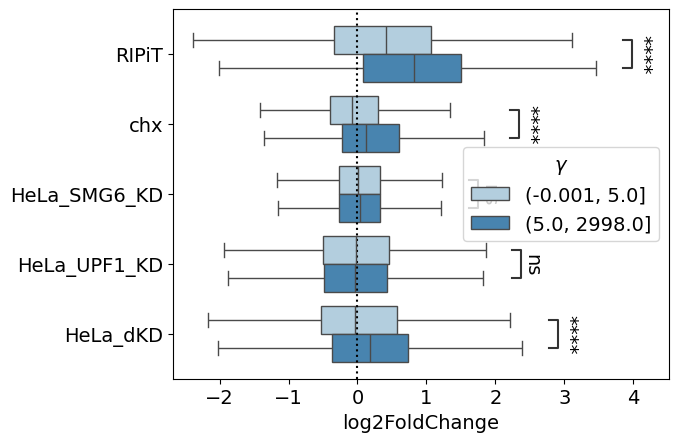

In [726]:
df['gamma_bin'] = pd.cut(df[GAMMA],[0,5,int(max(df[GAMMA]))+1],include_lowest=True)
df.experiment = df.experiment.astype('category').cat.reorder_categories(order)
df.sort_values('experiment')

f,ax = plt.subplots()
sns.boxplot(data=df,y='experiment',x='log2FoldChange',hue='gamma_bin',showfliers=False,ax=ax,palette='Blues')
#ax.legend(title=r'$\gamma$',loc='lower center', bbox_to_anchor=(0.5,1),ncol=2)
ax.legend(title=r'$\gamma$')
ax.set_ylabel(None)


ax.axvline(0,ls=':',c='black')


from statannotations.Annotator import Annotator
order = ['RIPiT', 'chx', 'HeLa_SMG6_KD', 'HeLa_UPF1_KD', 'HeLa_dKD']
combs = list(combinations(df.gamma_bin.unique(),2))
print(combs)
pairs = [((i,l1),(i,l2)) for l1,l2 in combs for i in order]

annotator = Annotator(
    ax,
    pairs,
    data=df,
    y='experiment',
    x='log2FoldChange',
    hue='gamma_bin',
    orient="h"
)

annotator.configure(
    test="Mann-Whitney", 
    text_format="star",     
    loc="inside",           
    comparisons_correction="bonferroni"
)

annotator.apply_and_annotate()

In [661]:
order

['RIPiT', 'chx', 'HeLa_SMG6_KD', 'HeLa_UPF1_KD', 'HeLa_dKD']

In [662]:
df.groupby(['experiment','gamma_bin']).size()

C:\Users\zavil\AppData\Local\Temp\ipykernel_5440\1799946234.py:1: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  df.groupby(['experiment','gamma_bin']).size()


experiment    gamma_bin 
RIPiT         (0, 5]        1264
              (5, 10]        234
              (10, 50]       321
              (50, 2580]     396
chx           (0, 5]        2339
              (5, 10]        825
              (10, 50]      1041
              (50, 2580]      14
HeLa_SMG6_KD  (0, 5]        3682
              (5, 10]        783
              (10, 50]       115
              (50, 2580]       0
HeLa_UPF1_KD  (0, 5]        2859
              (5, 10]       1085
              (10, 50]       618
              (50, 2580]       3
HeLa_dKD      (0, 5]        1367
              (5, 10]        955
              (10, 50]      2129
              (50, 2580]     480
dtype: int64

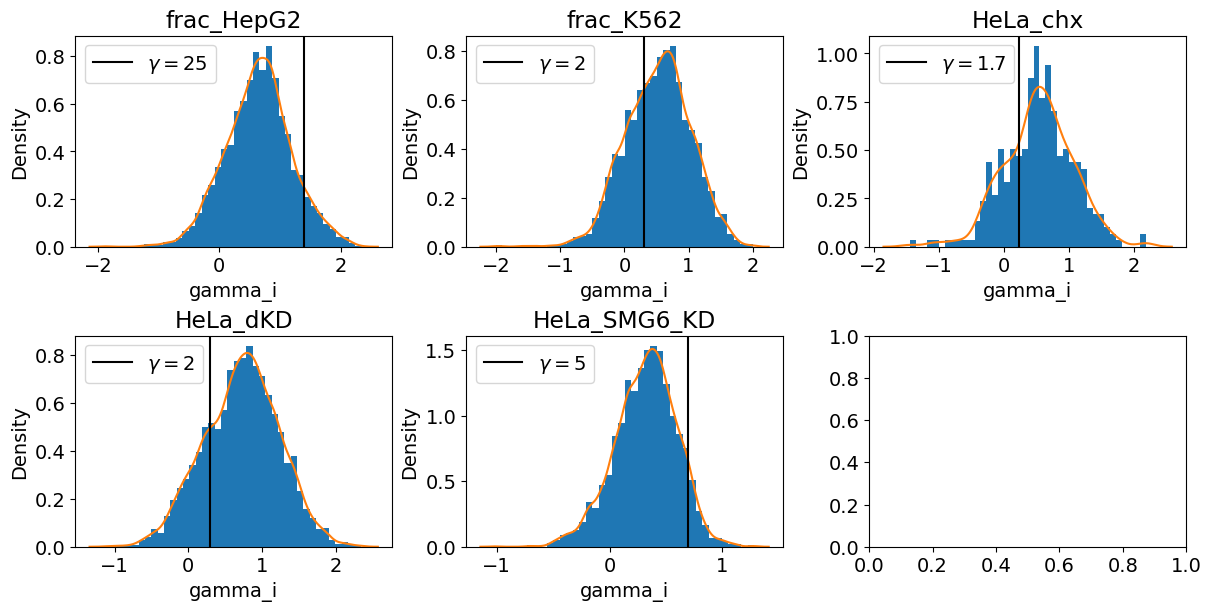

In [445]:
f,axes = plt.subplots(2,3,figsize=(12,6),constrained_layout=True)
axes = axes.flatten()
thresholds = [1.5,0.5,0.5,0.2,0.7]
thresholds = [25,2,1.7,2,5]
for exper,ax,thr in zip(order,axes,thresholds):
    tmp = resp[(resp.experiment==exper)]
    ax.hist(np.log10(tmp[GAMMA]),bins=40,density=True)
    sns.kdeplot(x=np.log10(tmp[GAMMA]),ax=ax,bw_adjust=0.8)
    ax.set_title(exper)
    ax.axvline(np.log10(thr),label=f"$\gamma = {thr:.2g}$",c='black')
    ax.legend()

## Scatter wit gamma

In [12]:
nmdpsi = pd.read_csv('./nmd_inactivation_data/united_use_master_table.tsv',sep='\t')
sets = pd.read_csv('./nmd_kd_experimental/USE_sets.tsv',sep='\t')

In [14]:
nmdpsi['gamma_emp'] = hf.psir2gamma(nmdpsi.ctrl_psi,nmdpsi.exp_psi)

In [16]:
order = ['HepG2 nucl/cyto','K562 nucl/cyto','HeLa CHX','HeLa dKD','HeLa SMG6 KD','HeLa UPF1 KD']

CPU times: total: 156 ms
Wall time: 161 ms


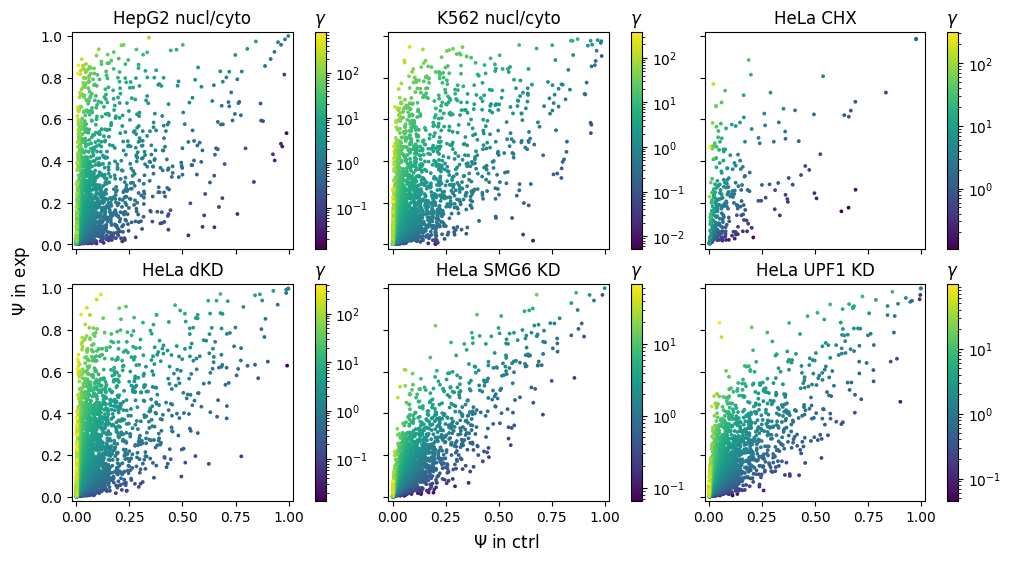

In [25]:
%%time
import matplotlib.colors as mcolors
f,ax = plt.subplots(2,3,figsize=(10,5.5),sharex=True,sharey=True,constrained_layout=True)
ax = ax.flatten()
pseudo = 0.001
for i,key in enumerate(order):
    exper = nmdpsi[nmdpsi.experiment==key].sort_values('gamma_emp').copy()
    exper = exper[(exper.ctrl_psi!=0)&(exper.exp_psi!=0)]
    im = ax[i].scatter(exper.ctrl_psi+pseudo,exper.exp_psi+pseudo,c=exper.gamma_emp,s=3,norm=mcolors.LogNorm())
    cbar = plt.colorbar(im,ax=ax[i])
    cbar.ax.set_title('$\gamma$')
    ax[i].set_title(key)
    ax[i].set_xlim(-0.02,1.02)
    ax[i].set_ylim(-0.02,1.02)
    #ax[i].axis('equal')
f.supxlabel(r'$\Psi$ in ctrl')
f.supylabel(r'$\Psi$ in exp')
for j in range(i+1,len(ax)):
    f.delaxes(ax[j])

## Figure 5 (Individual figures examples)

### Mapping between catalogs

In [1048]:
catalog = pd.read_csv('./use_catalog/filtered_catalog.tsv',sep='\t')

oldcat = pd.read_csv('../../../arkuda_backup/unproductive_splicing/data/TCGA/input/catalogs/nmdj.tsv',sep='\t')
oldcat['src'] = 'nmdj_anno'

old = oldcat[oldcat.transcript_biotype=='nonsense_mediated_decay'].groupby(['src','event_id','gene_id'], 
                                                                           observed=True,sort=False).long_id.agg(set).reset_index()
old.columns = ['old_src','old_id','gene_id','old_set']

new = catalog[catalog.transcript_biotype=='nonsense_mediated_decay'].groupby(['src','event_id','gene_id'],
                                                                             observed=True,
                                                                             sort=False).long_id.agg(set).reset_index()
new.columns = ['new_src','new_id','gene_id','new_set']

mapping = old.merge(new)

mapping['n_old'] = mapping.old_set.map(len)
mapping['n_new'] = mapping.new_set.map(len)
mapping['n_common'] = mapping.apply(lambda x: len(x.old_set&x.new_set),axis=1)

mapping[mapping.n_common!=0].groupby(['old_src','old_id']).size().value_counts()

1    10803
2       25
4        1
3        1
Name: count, dtype: int64

In [1049]:
mapping = mapping[mapping.n_common>0].sort_values('n_common',ascending=False).drop_duplicates(['old_src','old_id'])

In [1050]:
our = pd.read_csv('../nmd_kd_experimental/ALL qPCR 2024-2026 - KD+OE_nmd_dpsi.csv',index_col=[0])

In [1051]:
our[our.gene_name=='NCSTN']

,gene_name,event_id,ctrl,chx,gene_id,src
3,NCSTN,ENSG00000162736_3,0.127083,0.194583,ENSG00000162736,nmdj_anno


In [1052]:
mapping[mapping.old_id=='ENSG00000162736_3']

,old_src,old_id,gene_id,old_set,new_src,new_id,new_set,n_old,n_new,n_common
27721,nmdj_anno,ENSG00000162736_3,ENSG00000162736,{chr1_160350250_160351696_+},ensembl,ENSG00000162736_3,{chr1_160350250_160351696_+},1,1,1


In [1053]:
qpcr = pd.read_csv('../nmd_kd_experimental/ALL qPCR 2024-2026 - KD+OE.csv')

In [1054]:
need = ['RIC8B','PSPC1','NFAT5','U2SURP','RAB5IF','NCSTN']

In [1055]:
geneid = pd.read_csv('../../../arkuda_backup/gtfs/geneid.csv')

In [1056]:
aa = geneid[geneid.gene_name.isin(need)].drop('gene_biotype',axis=1).merge(catalog[catalog.src=='ensembl'])
bb = aa[['gene_name','src','event_id','event_type']].drop_duplicates()
set(need)-set(bb.gene_name)

set()

In [1057]:
bb

,gene_name,src,event_id,event_type
0,NCSTN,ensembl,ENSG00000162736_1,PE|PE2
4,NCSTN,ensembl,ENSG00000162736_0,PE|PE2
8,NCSTN,ensembl,ENSG00000162736_2,A3SS|PE2|PE3
12,NCSTN,ensembl,ENSG00000162736_3,EE|PE|PE2
17,NCSTN,ensembl,ENSG00000162736_5,EE
20,NCSTN,ensembl,ENSG00000162736_6,EE2
24,NCSTN,ensembl,ENSG00000162736_4,PE|PE+A3SS
28,U2SURP,ensembl,ENSG00000163714_0,EE
31,RIC8B,ensembl,ENSG00000111785_0,alt_end|complex
35,RIC8B,ensembl,ENSG00000111785_1,PE5|complex


In [1058]:
d = {'RIC8B':'ENSG00000111785_2','PSPC1':'ENSG00000121390_0',
     'NFAT5':'ENSG00000102908_0','U2SURP':'ENSG00000163714_0',
     'RAB5IF':'ENSG00000101084_0','NCSTN':'ENSG00000162736_3'}

df = pd.DataFrame({'gene_name':d.keys(),'event_id':d.values(),'src':'ensembl'})

cols = ['gene_id','src','event_id','nmd_id_list','coding_id_list']
aa = catalog[catalog.transcript_biotype=='nonsense_mediated_decay'][cols+['long_id']]
aa = aa.merge(df)
aa['long_id'] = aa.long_id.apply(lambda x: set() if 'chr_' in x else set([int(i) for i in x.split('_')[1:-1]]))
aa = aa.groupby(cols,as_index=False).long_id.agg(lambda x: set.union(*x))
aa['vmin'] = aa.long_id.map(min)
aa['vmax'] = aa.long_id.map(max)

df = aa.drop('long_id',axis=1).merge(df)

In [1059]:
qpcr = pd.read_csv('../nmd_kd_experimental/ALL qPCR 2024-2026 - KD+OE.csv')
qpcr[qpcr.TARGET.isin(df.gene_name)].TARGET.unique()
qpcr = qpcr[(qpcr.TARGET.isin(df.gene_name))&(qpcr.EXPERIMENT=='UT')&(qpcr.EXP_TYPE=='KD')].copy()

qpcr = qpcr.sort_values(['TARGET','Replicate'])
qpcr['rep'] = [i//2 for i in range(qpcr.shape[0])]

bad_rep = [17,37,38]
qpcr = qpcr[~qpcr.rep.isin(bad_rep)].sort_values(['TARGET','rep','CHX'])

In [1060]:
stat = qpcr.pivot(index=['TARGET','rep'],columns='CHX',values='PSI').reset_index()

In [1061]:
from scipy.stats import ttest_rel
from statsmodels.stats.multitest import multipletests

In [1062]:
pvals = stat.groupby('TARGET').apply(lambda x: ttest_rel(x[True],x[False])[1])
padj = multipletests(pvals,method='bonferroni')[1]
padj = pd.Series(padj,index=pvals.index,name='padj')

C:\Users\zavil\AppData\Local\Temp\ipykernel_15056\3042233526.py:1: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  pvals = stat.groupby('TARGET').apply(lambda x: ttest_rel(x[True],x[False])[1])


In [1090]:
def qpcr_boxplot_h(row,ax):
    tmp = qpcr[qpcr.TARGET==row.gene_name].copy()
    tmp.CHX = np.where(tmp.CHX,'$+$CHX','$-$CHX')
    sns.boxplot(data=tmp,x='PSI',y='CHX',hue='CHX',palette='Greys',ax=ax,legend=False,showfliers=False)
    sns.stripplot(data=tmp,x="PSI",y="CHX",hue='CHX',palette=["0.5", "0.2"],legend=False,ax=ax,s=5)
    
    pairs = [('$-$CHX', '$+$CHX')]
    
    annotator = Annotator(
        ax,
        pairs,
        data=tmp,
        y='CHX',
        x='PSI',
        orient='h'
    )
    
    annotator.set_pvalues([padj.loc[row.gene_name] ])
    
    annotator.configure(
        text_format="star",     
        loc="inside"
    )
    
    annotator.annotate()

    ax.set_xlabel('$\Psi$')
    ax.set_ylabel(None)
    
def qpcr_boxplot(row,ax):
    tmp = qpcr[qpcr.TARGET==row.gene_name].copy()
    tmp.CHX = np.where(tmp.CHX,'$+$CHX','$-$CHX')
    sns.boxplot(data=tmp,x='CHX',y='PSI',fill=False,color='darkgrey',ax=ax,legend=False,showfliers=False)
    sns.stripplot(data=tmp,x="CHX",y="PSI",color='black',legend=False,ax=ax,s=3)
    
    pairs = [('$-$CHX', '$+$CHX')]
    
    annotator = Annotator(
        ax,
        pairs,
        data=tmp,
        x='CHX',
        y='PSI'
    )
    
    annotator.set_pvalues([padj.loc[row.gene_name] ])
    
    annotator.configure(
        text_format="star",     
        loc="inside"
    )
    
    annotator.annotate()

    ax.set_ylabel('$\Psi$')
    ax.set_xlabel(None)

In [1075]:
import sashimi as sas
import pyranges as pr

In [1076]:
def read_gtf(file):
    df = pr.read_gtf(file).df
    c1 = ['Chromosome', 'Source', 'Feature', 'Start', 'End', 'Score', 'Strand', 'Frame']
    c2 = ['chrn', 'source', 'type', 'start', 'end', 'score', 'strand', 'frame']
    d = dict(zip(c1,c2))
    df = df.rename(columns=d)
    df.start+=1
    return df

In [1077]:
%%time
#gtf = read_gtf('./gtfs/ensembl_filtered.gtf')

CPU times: total: 0 ns
Wall time: 0 ns


In [1078]:
from importlib import reload
reload(sas)

<module 'sashimi' from 'C:\\Users\\zavil\\tcga_paper\\NMDeq\\project\\sashimi.py'>

In [1079]:
def crop_gtf(x,vmin,vmax):
    cond = (x.start<=vmax)&(x.end>=vmin)
    gtf = x[cond].copy()
    gtf.loc[gtf.start<vmin,'start'] = vmin
    gtf.loc[gtf.end>vmax,'end'] = vmax
    return gtf

In [1080]:
def get_coverage(file,chrn,start,end):
    exe = '~/soft/ucsc/bigWigToBedGraph'
    cmd = f'wsl sh -c "{exe} -range={chrn}:{start}-{end} {file} stdout"'
    return sas.read_shell(cmd,header=None,names=['chrn','start','end','coverage'])

In [1092]:
def plot(x,figsize=(4,2),trs=None):
    row = x.copy()

    nmd = row.nmd_id_list.split(', ')
    coding = row.coding_id_list.split(', ')
    if trs:
        nmd = list(set(nmd)&set(trs))
        coding = list(set(coding)&set(trs))
    
    gene = gtf[gtf.gene_name==row.gene_name]
    gene = gene[gene.transcript_id.isin(nmd+coding)]
    row.vmin = max(row.vmin,gene.start.min())
    row.vmax = min(row.vmax,gene.end.max())
    
    cmap = plt.get_cmap('tab10')
    highlight = dict()
    for t in coding:
        highlight[t] = cmap(0)
    for t in nmd:
        highlight[t] = 'red'
    
    gene = crop_gtf(gene,row.vmin-200,row.vmax+200)
    
    f, ax = plt.subplot_mosaic(
        """
        DA
        DB
        DC
        """,
        figsize=figsize,
        width_ratios=(1,4),
        height_ratios=(1,1,1),
    )
    ax1,ax2,ax3,ax4 = ax['A'],ax['B'],ax['C'],ax['D']
    plt.subplots_adjust(wspace=0.1,hspace=0)
    ax2.sharex(ax1)
    ax3.sharex(ax1)
    ax1,mapper = sas.plot_gene(
        gene,
        collapse=True,
        shrink=True,
        intron_size='rel',
        rel_length=0.5,
        highlight=highlight,
        ax=ax1,
        arrows=False,
        arrow_kwargs={'n':10,'s':15,'fixed_strand':True},
        max_tr=1
    )
    ax1.set_ylim(-0.5, len(ax1.get_yticks()) - 0.5)
    ax1.margins(0)
    
    ax1.set_title(row.gene_name)
    ax1.get_xaxis().set_visible(False)
    ax1.spines['top'].set_visible(False)
    ax1.spines['right'].set_visible(False)
    ax1.spines['bottom'].set_visible(False)
    for ax in [ax2,ax3]:
        ax.spines['top'].set_visible(False)
        ax.spines['right'].set_visible(False)

    cov = get_coverage('./bigwig/HCT_N_AID_UPF1_12h_IAA_2.uniq.bw',gene.chrn.iloc[0],row.vmin-100,row.vmax+100)
    sas.draw_coverage(ax2,cov,mapper=mapper)
    ax2.set_ylabel('Ribo-Seq',ha='right',va='center',rotation=0)

    cov = get_coverage('./bigwig/hg38.phastCons30way.bw',gene.chrn.iloc[0],row.vmin-100,row.vmax+100)
    cov.coverage = np.maximum(cov.coverage,0)
    sas.draw_coverage(ax3,cov,mapper=mapper,color='LimeGreen')
    ax3.set_ylabel('phyloP30',ha='right',va='center',rotation=0)

    for ax in [ax1,ax2]:
        ax.set_xlim(mapper.transform(row.vmin-100),mapper.transform(row.vmax+100))
        ax.set_xticks([])
        ax.margins(y=0)
    if gene.strand.iloc[0]=='-':
        for ax in [ax1,ax2,ax3]:
            ax.invert_xaxis()
    qpcr_boxplot(row,ax4)
    return f,[ax1,ax2,ax3,ax4]
    

In [1082]:
!mkdir "./figures/examples"

A subdirectory or file ./figures/examples already exists.


In [1083]:
df.loc[df.gene_name=='RIC8B','vmin'] = 106870900

In [1084]:
trs = {'RAB5IF':['ENST00000344795','ENST00000483815'],
       'NFAT5':['ENST00000349945', 'ENST00000354436', 'ENST00000567239','ENST00000426654','ENST00000393742'],
       'PSPC1':['ENST00000619300','ENST00000492741'],
       'NCSTN':['ENST00000699553','ENST00000459963'],
       'RIC8B':['ENST00000392837','ENST00000462949']}

In [1137]:
plt.rcParams.update({'font.size': 12})

C:\Users\zavil\miniconda3\envs\py310\lib\site-packages\statannotations\Annotator.py:825: UserWarning: Annotator was reconfigured without applying the test (again) which will probably lead to unexpected results
  warnings.warn("Annotator was reconfigured without applying the "
<timed exec>:14: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.


p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

$-$CHX vs. $+$CHX: Custom statistical test, P_val:1.642e-03


C:\Users\zavil\miniconda3\envs\py310\lib\site-packages\statannotations\Annotator.py:825: UserWarning: Annotator was reconfigured without applying the test (again) which will probably lead to unexpected results
  warnings.warn("Annotator was reconfigured without applying the "
<timed exec>:14: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.


p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

$-$CHX vs. $+$CHX: Custom statistical test, P_val:1.000e+00


C:\Users\zavil\miniconda3\envs\py310\lib\site-packages\statannotations\Annotator.py:825: UserWarning: Annotator was reconfigured without applying the test (again) which will probably lead to unexpected results
  warnings.warn("Annotator was reconfigured without applying the "
<timed exec>:14: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.


...

p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

$-$CHX vs. $+$CHX: Custom statistical test, P_val:4.143e-02


C:\Users\zavil\miniconda3\envs\py310\lib\site-packages\statannotations\Annotator.py:825: UserWarning: Annotator was reconfigured without applying the test (again) which will probably lead to unexpected results
  warnings.warn("Annotator was reconfigured without applying the "
<timed exec>:14: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.


p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

$-$CHX vs. $+$CHX: Custom statistical test, P_val:3.945e-01


C:\Users\zavil\miniconda3\envs\py310\lib\site-packages\statannotations\Annotator.py:825: UserWarning: Annotator was reconfigured without applying the test (again) which will probably lead to unexpected results
  warnings.warn("Annotator was reconfigured without applying the "
<timed exec>:14: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.


p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

$-$CHX vs. $+$CHX: Custom statistical test, P_val:3.519e-02
CPU times: total: 5.64 s
Wall time: 13.3 s


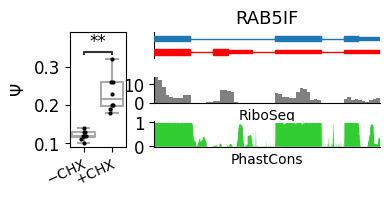

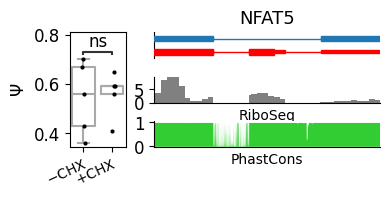

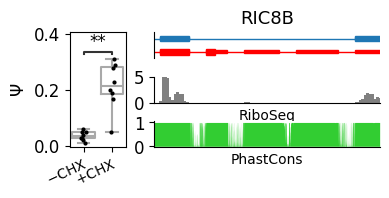

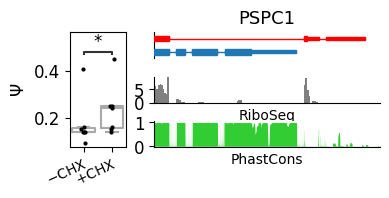

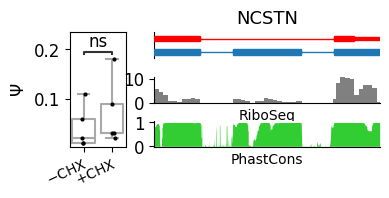

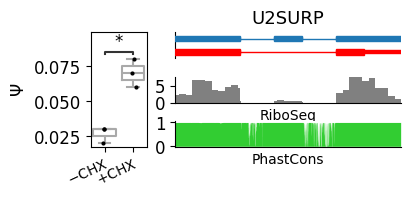

In [1138]:
%%time
reload(sas)
for _,row in df.iterrows():
    trlist = None if row.gene_name not in trs.keys() else trs[row.gene_name]
    f,ax = plot(row,trs=trlist,figsize=(4,1.5))
    plt.subplots_adjust(wspace=0.2,hspace=0.7)
    ax[0].set_yticks([])
    ax[0].set_title(ax[0].get_title(),fontsize=13)
    ax[1].set_ylabel(None)
    ax[2].set_ylabel(None)
    
    ax[1].set_xlabel('RiboSeq',fontsize=10)
    ax[2].set_xlabel('PhastCons',fontsize=10)
    axs = ax[3]
    axs.set_xticklabels(axs.get_xticklabels(),rotation=25,ha='right',rotation_mode='anchor',fontsize=10)
    f.savefig(f'./figures/examples/{row.gene_name}.pdf',bbox_inches='tight',transparent=True)

C:\Users\zavil\miniconda3\envs\py310\lib\site-packages\statannotations\Annotator.py:825: UserWarning: Annotator was reconfigured without applying the test (again) which will probably lead to unexpected results
  warnings.warn("Annotator was reconfigured without applying the "
C:\Users\zavil\AppData\Local\Temp\ipykernel_15056\2145421930.py:13: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axs.set_xticklabels(axs.get_xticklabels(),rotation=25,ha='right',rotation_mode='anchor',fontsize=10)


p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

$-$CHX vs. $+$CHX: Custom statistical test, P_val:1.617e-03


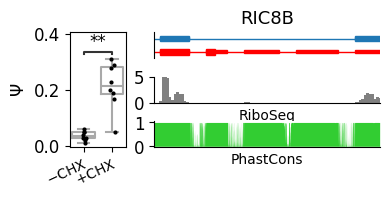

In [1126]:
row = df.loc[2]
trlist = None if row.gene_name not in trs.keys() else trs[row.gene_name]
f,ax = plot(row,trs=trlist,figsize=(4,1.5))
plt.subplots_adjust(wspace=0.2,hspace=0.7)
ax[0].set_yticks([])
ax[0].set_title(ax[0].get_title(),fontsize=13)
ax[1].set_ylabel(None)
ax[2].set_ylabel(None)

ax[1].set_xlabel('RiboSeq',fontsize=10)
ax[2].set_xlabel('PhastCons',fontsize=10)
axs = ax[3]
axs.set_xticklabels(axs.get_xticklabels(),rotation=25,ha='right',rotation_mode='anchor',fontsize=10)
f.savefig(f'./figures/examples/{row.gene_name}.pdf',bbox_inches='tight')

In [1139]:
plt.rcParams.update({'font.size': 14})

array(['ENST00000392837', 'ENST00000392839', 'ENST00000355478',
       'ENST00000549643', 'ENST00000462949'], dtype=object)

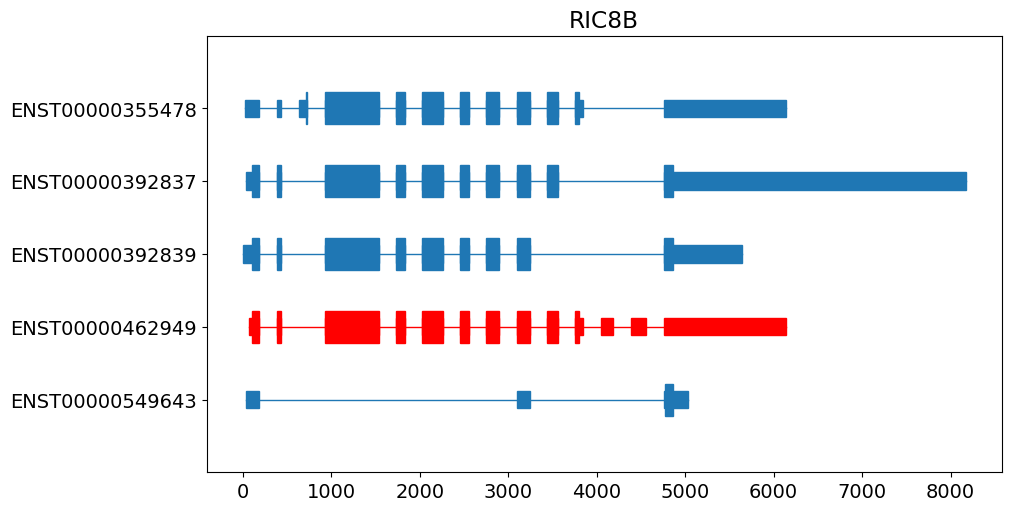

In [952]:
reload(sas)
row = df.iloc[2]
nmd = row.nmd_id_list.split(', ')
coding = row.coding_id_list.split(', ')

gene = gtf[gtf.gene_name==row.gene_name]
gene = gene[gene.transcript_id.isin(nmd+coding)]

cmap = plt.get_cmap('tab10')
highlight = dict()
for t in coding:
    highlight[t] = cmap(0)
for t in nmd:
    highlight[t] = 'red'

#gene = crop_gtf(gene,row.vmin-200,row.vmax+200)

f,ax = plt.subplots(figsize=(10,5),constrained_layout=True)
ax,mapper = sas.plot_gene(
    gene,
    collapse=True,
    shrink=True,
    intron_size=200,
    highlight=highlight,
    ax=ax,
    arrows=False,
    arrow_kwargs={'n':10,'s':15,'fixed_strand':True},
    max_tr=np.inf
)
ax.set_title(row.gene_name)
if gene.strand.iloc[0]=='-':
    print('aa')
    ax.invert_xaxis()
gene.transcript_id.unique()

### Merge example figures

In [1141]:
from pypdf import PdfReader, PdfWriter, Transformation
from pypdf._page import PageObject

files = [
    "./figures/examples/RAB5IF.pdf",
    "./figures/examples/RIC8B.pdf",
    "./figures/examples/U2SURP.pdf",
    "./figures/examples/PSPC1.pdf",
    "./figures/examples/NCSTN.pdf",
    "./figures/examples/NFAT5.pdf",
]

# overlap between images
overlap_h = 0  # frac of width
overlap_v = 0.15  # frac of height

pages = [PdfReader(f).pages[0] for f in files]

w = max(float(p.mediabox.width) for p in pages)
h = max(float(p.mediabox.height) for p in pages)

# Шаг между колонками и строками
dx = w - overlap_h*w
dy = h - overlap_v*h

canvas_width = w + dx
canvas_height = h + 2 * dy

canvas = PageObject.create_blank_page(
    width=canvas_width,
    height=canvas_height,
)

positions = [
    (0,      2 * dy),
    (dx,     2 * dy),
    (0,      dy),
    (dx,     dy),
    (0,      0),
    (dx,     0),
]

for page, (x, y) in zip(pages, positions):
    canvas.merge_transformed_page(
        page,
        Transformation().translate(x, y)
    )

writer = PdfWriter()
writer.add_page(canvas)

with open("./figures/examples/combined.pdf", "wb") as f:
    writer.write(f)

In [967]:
nmdpsi = pd.read_csv('./nmd_inactivation_data/united_use_master_table.tsv',sep='\t')

<Axes: xlabel='gene_name', ylabel='experiment'>

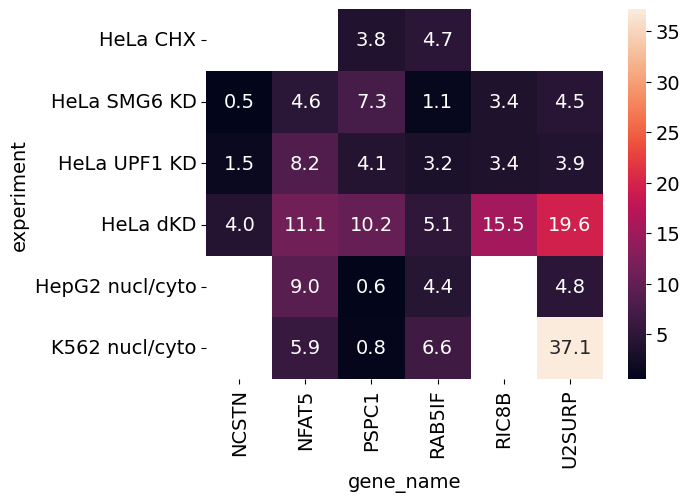

In [983]:
aa = df[['gene_name','src','event_id']].merge(nmdpsi)
aa['gamma'] = hf.psir2gamma(aa.ctrl_psi,aa.exp_psi)
aa=aa.pivot(columns='gene_name',index='experiment',values='gamma')
aa = aa.loc[good_data]
bb = aa.fillna(1)
g = sns.clustermap(bb)
plt.close()
ind = g.dendrogram_row.reordered_ind
col = g.dendrogram_col.reordered_ind
#aa = aa.iloc[:,col]
sns.heatmap(aa,annot=True,fmt='.1f')

## Figure 6 (discussion)

На Рис 6 уберите гиперболы, серую заливку для дельта пси (она заслоняет красный цвет), также уберите легенду сверху, добавьте $\Psi\in[0.2,0.4]$ под наклоном 45градусов внутри самой полосы (границы пунктиром, заливки нет), одну точку с координатами (0.5,0.8) и рядом сней метку NR и другую где-нибудь ближе к левому краю, где покраснее, с меткой R

(0.0, 1.0)

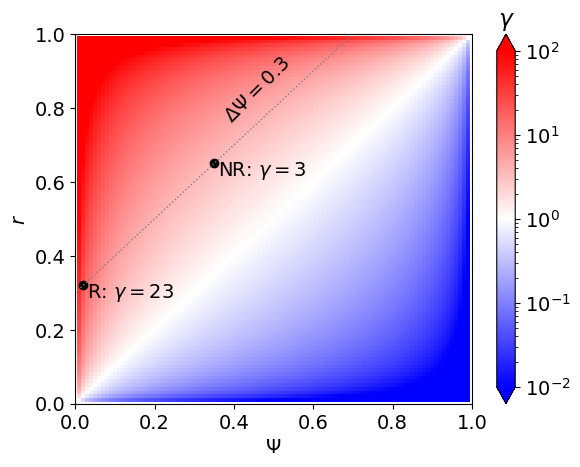

In [1207]:
import numpy as np
import matplotlib.pyplot as plt

psi = np.linspace(0, 1, 100)
r = np.linspace(0, 1, 100)

psi = psi[1:-1]
r = r[1:-1]

PSI, R = np.meshgrid(psi, r)

gamma = hf.psir2gamma(PSI,R)

f, ax = plt.subplots()

pcm = ax.pcolormesh(
    PSI, R, gamma,
    shading='auto',
    norm=colors.LogNorm(vmax=100,vmin=0.01),
#    norm=colors.LogNorm(),
    cmap='bwr'
)

cbar = plt.colorbar(pcm, ax=ax,extend='both')
cbar.ax.set_title('$\gamma$')


ax.set_xlabel(r'$\Psi$')
ax.set_ylabel(r'$r$')

l = [0.3]
for dpsi in l:
    ax.plot([0,1],[dpsi,1+dpsi],lw=1,ls=':',c='grey')

x = np.mean(l)+0.25#(1-np.mean(l))/2
y = x+np.mean(l)
ax.text(x,y,rf'$\Delta\Psi={np.mean(l)}$',rotation=45,va='center',ha='right')

x1 = (1-np.mean(l))/2
x2 = 0.02
x = np.array([x1,x2])
y = x+np.mean(l)
ax.scatter(x,y,c='black')
g = hf.psir2gamma(x,y)
labels = [f'NR: $\\gamma={g[0]:.0f}$',f'R: $\\gamma={g[1]:.0f}$']

offset=0.01
for xi,yi,t in zip(x,y,labels):
    ax.text(xi+offset,yi+offset,t,ha='left',va='top')

#ax.legend(loc='lower center',bbox_to_anchor=(0.5,1),ncol=2)
ax.set_xlim(0,1)
ax.set_ylim(0,1)

In [1208]:
f.savefig('./figures/Fig6.pdf',bbox_inches='tight')

(0.0, 1.0)

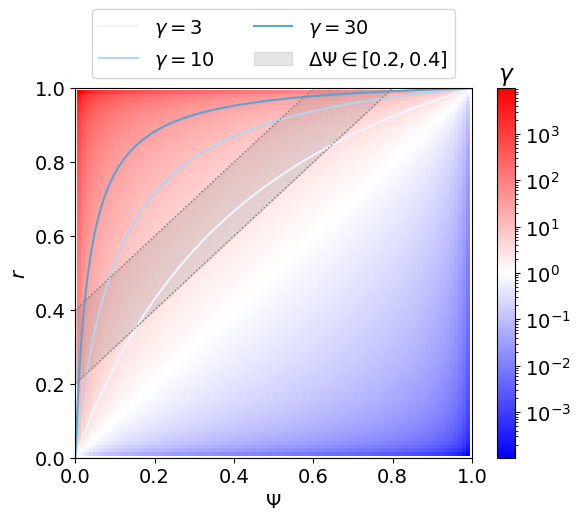

In [1001]:
import numpy as np
import matplotlib.pyplot as plt

psi = np.linspace(0, 1, 100)
r = np.linspace(0, 1, 100)

psi = psi[1:-1]
r = r[1:-1]

PSI, R = np.meshgrid(psi, r)

gamma = hf.psir2gamma(PSI,R)

f, ax = plt.subplots()

pcm = ax.pcolormesh(
    PSI, R, gamma,
    shading='auto',
    norm=colors.LogNorm(),cmap='bwr'
)

cbar = plt.colorbar(pcm, ax=ax)
cbar.ax.set_title('$\gamma$')

# Additional lines in the same coordinates
cmap = plt.get_cmap('Blues')
x = np.linspace(0, 1, 100)
for i,gamma in enumerate([3,10,30]):
    ax.plot(x,hf.psi2r(x,gamma),
            c=cmap(0.25*(i)+0.05),label=fr"$\gamma={gamma}$")
ax.set_xlabel(r'$\Psi$')
ax.set_ylabel(r'$r$')

l = [0.2,0.4]
#ax.fill_between([0,1],[l[0],1+l[0]],[l[1],1+l[1]],color='grey',alpha=0.2,label=r'$\Delta\Psi \in [0.2,0.4]$')
for dpsi in l:
    ax.plot([0,1],[dpsi,1+dpsi],lw=1,ls=':',c='grey')
#ax.text(dpsi*0.3,dpsi*1.3,fr'$\Delta\Psi={dpsi}$',va='top',ha='left')

ax.legend(loc='lower center',bbox_to_anchor=(0.5,1),ncol=2)
ax.set_xlim(0,1)
ax.set_ylim(0,1)

In [1002]:
f.savefig('./figures/Fig6.pdf',bbox_inches='tight')

In [585]:
ase = pd.read_csv('./nmd_inactivation_data/binASE_master_table.tsv',sep='\t')

In [588]:
aa = ase[['src','event_id']].drop_duplicates()
asecat = pd.read_csv('../../../arkuda_backup/unproductive_splicing/data/TCGA/input/catalogs/binASE.tsv',sep='\t')

In [592]:
aa.merge(asecat)[['src','event_id','event_type']].drop_duplicates().event_type.value_counts()

event_type
CE      3756
A3SS    1341
A5SS     610
IR       103
Name: count, dtype: int64

## Figure 5

In [694]:
qpcr = pd.read_csv('../nmd_kd_experimental/ALL qPCR 2024-2026 - KD+OE.csv')

In [695]:
fallout = ['TFDP1','CLK4','EZH2','CLK2']

In [696]:
qpcr.EXP_TYPE.unique()

array(['OE', 'KD'], dtype=object)

In [697]:
qpcr = qpcr[(~qpcr.TARGET.isin(fallout))&(qpcr.EXPERIMENT=='UT')&(qpcr.EXP_TYPE=='KD')]

In [698]:
order

['frac_HepG2',
 'frac_K562',
 'HeLa_chx',
 'HeLa_dKD',
 'HeLa_SMG6_KD',
 'HeLa_UPF1_KD']

In [725]:
experiment = order[3]
experiment

'HeLa_dKD'

C:\Users\zavil\AppData\Local\Temp\ipykernel_4592\764252766.py:4: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(ax.get_xticklabels(),rotation=45,ha='right',rotation_mode='anchor')


p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

FKBP14_False vs. FKBP14_True: t-test independent samples with Benjamini-Hochberg correction, P_val:4.098e-03 t=-3.173e+00
RAB5IF_False vs. RAB5IF_True: t-test independent samples with Benjamini-Hochberg correction, P_val:2.083e-05 t=-6.262e+00
RIC8B_False vs. RIC8B_True: t-test independent samples with Benjamini-Hochberg correction, P_val:3.786e-05 t=-5.912e+00
CLK1_False vs. CLK1_True: t-test independent samples with Benjamini-Hochberg correction, P_val:7.117e-03 t=-3.148e+00
PSPC1_False vs. PSPC1_True: t-test independent samples with Benjamini-Hochberg correction, P_val:5.097e-01 t=-6.766e-01
NFAT5_False vs. NFAT5_True: t-test independent samples with Benjamini-Hochberg correction, P_val:8.413e-01 t=-2.068e-01
NCSTN_False vs. NCSTN_True: t-test independent samples with Benjamini-Hochberg correct

C:\Users\zavil\AppData\Local\Temp\ipykernel_4592\764252766.py:39: UserWarning: *c* argument looks like a single numeric RGB or RGBA sequence, which should be avoided as value-mapping will have precedence in case its length matches with *x* & *y*.  Please use the *color* keyword-argument or provide a 2D array with a single row if you intend to specify the same RGB or RGBA value for all points.
  ax2.scatter(data.gamma_qPCR,data.gamma_emp,label='Analytical',c=cmap(0))
C:\Users\zavil\AppData\Local\Temp\ipykernel_4592\764252766.py:40: UserWarning: *c* argument looks like a single numeric RGB or RGBA sequence, which should be avoided as value-mapping will have precedence in case its length matches with *x* & *y*.  Please use the *color* keyword-argument or provide a 2D array with a single row if you intend to specify the same RGB or RGBA value for all points.
  ax2.scatter(data.gamma_qPCR,data.gamma_i,label='Posterior',c=cmap(100))


Text(589.4908520073462, 0.5, '$\\gamma$ RNA-Seq (HeLa_dKD)')

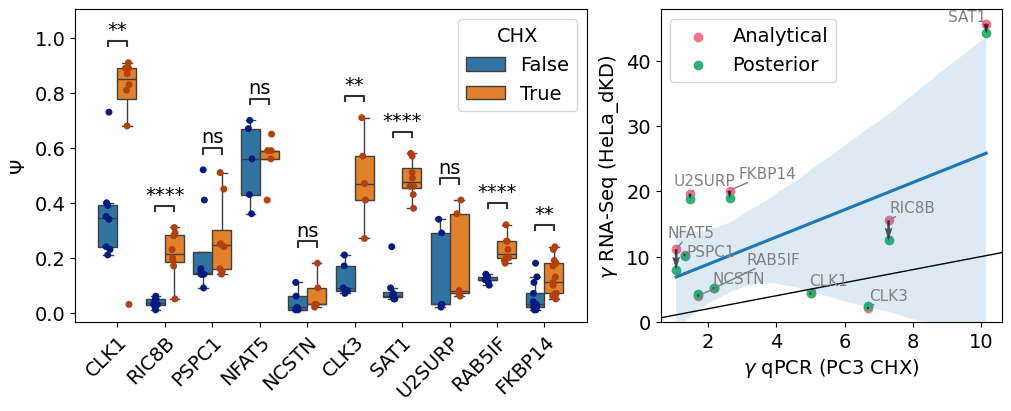

In [726]:
f,(ax,ax2) = plt.subplots(1,2,figsize=(10,4),width_ratios=(3,2),constrained_layout=True)
sns.boxplot(data=qpcr,x='TARGET',y='PSI',hue='CHX',showfliers=False,ax=ax)
sns.stripplot(data=qpcr,x='TARGET',y='PSI',hue='CHX',dodge=True,palette='dark',legend=False,ax=ax)
ax.set_xticklabels(ax.get_xticklabels(),rotation=45,ha='right',rotation_mode='anchor')
ax.set_xlabel(None)
ax.set_ylabel('$\Psi$')

pairs = [((i,True),(i,False)) for i in qpcr.TARGET.unique()]

annotator = Annotator(
    ax,
    pairs,
    data=qpcr,
    y='PSI',
    x='TARGET',
    hue='CHX',
    orient="v"
)

annotator.configure(
    test='t-test_ind',#"Mann-Whitney", 
    text_format="star",     
    loc="inside",
    comparisons_correction="fdr_bh"
)

annotator.apply_and_annotate()
genes = [ann.data.group1[0] for ann in annotator.annotations if ann.data.is_significant]


qgamma = qpcr.groupby(['TARGET','CHX'],as_index=False).PSI.agg('mean').pivot(index='TARGET',columns='CHX',values="PSI")
qgamma['gamma_qPCR'] = hf.psir2gamma(qgamma[False],qgamma[True])

data = sets[sets['from']=='our'][['gene_name','src','event_id']].merge(resp[resp.experiment==experiment])
data['gamma_qPCR'] = data.gene_name.map(qgamma.gamma_qPCR)
data = data[(data.gamma_qPCR.notna())&(data.gamma_i.notna())]

cmap = sns.color_palette("husl",as_cmap=True)
ax2.scatter(data.gamma_qPCR,data.gamma_emp,label='Analytical',c=cmap(0))
ax2.scatter(data.gamma_qPCR,data.gamma_i,label='Posterior',c=cmap(100))

xl = ax2.get_xlim()
yl = ax2.get_ylim()
ax2.legend()
ax2.plot([0,100],[0,100],c='black',lw=1)
ax2.set_xlim(*xl)
ax2.set_ylim(*yl)

ax2.quiver(
    data.gamma_qPCR,data.gamma_emp, data.shape[0]*[0], data.gamma_i-data.gamma_emp,
    angles='xy',
    scale_units='xy',
    scale=1,
    color='black',
    alpha=0.7
)

txt = []
from adjustText import adjust_text

for _,row in data.iterrows():
    txt.append(ax2.text(row.gamma_qPCR,row.gamma_emp,row.gene_name,va='bottom',c='grey',fontsize=11))
adjust_text(txt,ax=ax2,arrowprops=dict(arrowstyle="-", color='grey'),x=data.gamma_qPCR,y=data.gamma_i)

sns.regplot(data=data,x='gamma_qPCR',y='gamma_i',scatter=False,ax=ax2)
ax2.set_xlabel('$\gamma$ qPCR (PC3 CHX)')
ax2.set_ylabel(f'$\gamma$ RNA-Seq ({experiment})')


''

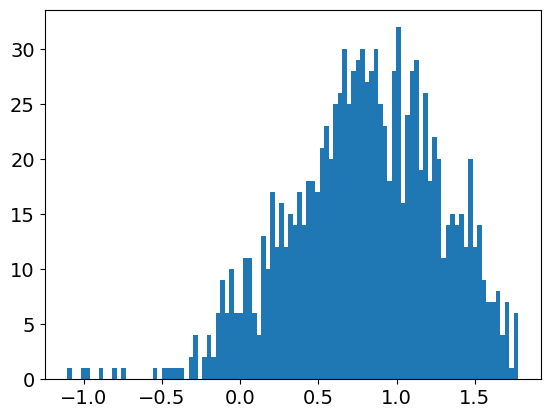

In [751]:
x = resp[(resp.experiment=='HeLa_dKD')&(resp.gamma_i<60)].merge(sets[sets.set2==1]).gamma_i
x = np.log10(x)
plt.hist(x,bins=100)
''

In [749]:
resp

,src,event_id,experiment,ctrl_psi,exp_psi,ctrl_denom,exp_denom,file,gamma_i,gamma_emp,prob,responder
0,chess,CHS.59145_0,frac_HepG2,0.018408,0.009194,281.250000,244.000000,fractioning,0.809348,0.494792,1.671445e-04,NR
1,chess,CHS.59164_0,frac_HepG2,0.412116,0.248269,68.000000,381.250000,fractioning,0.503299,0.471120,2.383504e-14,NR
2,chess,ENSG00000001629_0,frac_HepG2,0.025526,0.067908,117.375000,46.625000,fractioning,3.333677,2.781350,8.850189e-01,R
3,chess,ENSG00000002016_0,frac_HepG2,0.078947,0.096154,30.000000,46.750000,fractioning,1.860777,1.241135,2.273893e-04,NR
4,chess,ENSG00000002016_1,frac_HepG2,0.053846,0.092429,29.000000,49.750000,fractioning,2.733215,1.789520,1.813313e-01,NR
...,...,...,...,...,...,...,...,...,...,...,...,...
17443,ensembl,ENSG00000283761_0,HeLa_UPF1_KD,0.021108,0.083333,63.166667,124.000000,hela_kd,3.893809,4.215909,9.305065e-01,R
17444,ensembl,ENSG00000284292_0,HeLa_UPF1_KD,0.000613,0.005450,1496.416667,1345.666667,hela_kd,5.915722,8.939477,9.493203e-01,NR
17445,ensembl,ENSG00000285053_0,HeLa_UPF1_KD,0.083533,0.302013,173.583333,149.000000,hela_kd,4.558808,4.747182,9.448560e-01,R
17446,ensembl,ENSG00000285976_0,HeLa_UPF1_KD,0.025857,0.008054,1244.000000,1862.333333,hela_kd,0.360908,0.305902,2.089208e-15,NR


In [741]:
np.array([0.2,0.6])*60*60/1000

array([0.72, 2.16])

In [739]:
data[['gamma_i','gamma_qPCR']].corr()

,gamma_i,gamma_qPCR
gamma_i,1.000000,0.528153
gamma_qPCR,0.528153,1.000000


In [727]:
f.savefig('./figures/Fig5.pdf',bbox_inches='tight')

In [710]:
genes = '''RIC8B
NCSTN
U2SURP
SAT1
CLK3
EZH2
PSPC1
CLK1
NFAT5
RAB5IF'''.split('\n')

In [711]:
s1 = set(qpcr.TARGET.unique())
s2 = set(genes)
s1-s2,s2-s1

({'FKBP14'}, {'EZH2'})

In [708]:
sorted(s1)

['CLK1',
 'CLK3',
 'FKBP14',
 'NCSTN',
 'NFAT5',
 'PSPC1',
 'RAB5IF',
 'RIC8B',
 'SAT1',
 'U2SURP']

In [709]:
sorted(s2)

['CLK1', 'CLK3', 'FKBP14', 'RAB5IF', 'RIC8B', 'SAT1']

In [702]:
sets[sets.set1==1]

,gene_name,src,event_id,event_type,from,ctrl,chx,set1,set2,set3
1467,FUS,ensembl,ENSG00000089280_0,EE,literature,NaN,NaN,1,1,1
2363,HNRNPL,ensembl,ENSG00000104824_0,PE,literature,NaN,NaN,1,1,1
2371,SNRNP70,ensembl,ENSG00000104852_0,PE,literature,NaN,NaN,1,1,1
3079,SRSF9,ensembl,ENSG00000111786_0,PE,literature,NaN,NaN,1,1,1
3090,SRSF3,ensembl,ENSG00000112081_1,PE,literature,NaN,NaN,1,1,1
3453,SRSF7,ensembl,ENSG00000115875_0,PE,literature,NaN,NaN,1,1,1
3464,TIA1,ensembl,ENSG00000116001_0,PE,literature,NaN,NaN,1,1,1
4540,RBM39,ensembl,ENSG00000131051_3,PE,literature,NaN,NaN,1,1,1
5704,IQGAP1,ensembl,ENSG00000140575_0,PE,literature,NaN,NaN,1,1,1
7136,U2AF1,ensembl,ENSG00000160201_1,PE,literature,NaN,NaN,1,1,1


In [703]:
dkd = pd.read_csv('nmd_inactivation_data/hela_kd.tsv',sep='\t')
dkd = dkd[dkd.experiment=='HeLa_dKD'].copy()

In [624]:
sets[sets.gene_name.isin(['CLK2','FKBP14'])]

,gene_name,src,event_id,event_type,from,ctrl,chx,set1,set2,set3
2545,FKBP14,ensembl,ENSG00000106080_0,EE,other,NaN,NaN,0,1,1
11743,FKBP14,chess,ENSG00000106080_0,PE|PE2,other,NaN,NaN,0,0,1


In [625]:
dkd[(dkd.src=='chess')&(dkd.event_id=='ENSG00000106080_0')]

,experiment,src,event_id,ctrl_psi,exp_psi,ctrl_denom,exp_denom
15758,HeLa_dKD,chess,ENSG00000106080_0,0.093126,0.673742,75.166667,274.833333


In [602]:
p = [i.data.is_significant for i in annotator.annotations]
genes = np.array([i._text for i in ax.get_xticklabels()])[p]

In [603]:
genes

array(['CLK2', 'CLK1', 'PSPC1', 'NFAT5', 'NCSTN', 'RAB5IF', 'FKBP14'],
      dtype='<U6')

In [597]:
dir(annotator.annotations[0])

['__class__',
 '__delattr__',
 '__dict__',
 '__dir__',
 '__doc__',
 '__eq__',
 '__format__',
 '__ge__',
 '__getattribute__',
 '__gt__',
 '__hash__',
 '__init__',
 '__init_subclass__',
 '__le__',
 '__lt__',
 '__module__',
 '__ne__',
 '__new__',
 '__reduce__',
 '__reduce_ex__',
 '__repr__',
 '__setattr__',
 '__sizeof__',
 '__str__',
 '__subclasshook__',
 '__weakref__',
 'check_data_stat_result',
 'data',
 'formatted_output',
 'formatter',
 'is_custom',
 'print_labels_and_content',
 'structs',
 'text']

In [589]:
dir(annotator)

['__class__',
 '__delattr__',
 '__dict__',
 '__dir__',
 '__doc__',
 '__eq__',
 '__format__',
 '__ge__',
 '__getattribute__',
 '__gt__',
 '__hash__',
 '__init__',
 '__init_subclass__',
 '__le__',
 '__lt__',
 '__module__',
 '__ne__',
 '__new__',
 '__reduce__',
 '__reduce_ex__',
 '__repr__',
 '__setattr__',
 '__sizeof__',
 '__str__',
 '__subclasshook__',
 '__weakref__',
 '_activate_configured_warning',
 '_alpha',
 '_annotate_pair',
 '_annotate_pair_text',
 '_apply_comparisons_correction',
 '_check_correct_number_custom_annotations',
 '_check_has_plotter',
 '_check_pvalues_no_perform',
 '_check_test_no_perform',
 '_check_test_pvalues_perform',
 '_comparisons_correction',
 '_deactivate_configured_warning',
 '_get_custom_results',
 '_get_offsets_inside',
 '_get_offsets_outside',
 '_get_output',
 '_get_plotter',
 '_get_results',
 '_get_stat_result_from_test',
 '_get_value_for_pair',
 '_get_xy_params',
 '_get_xy_params_horizontal',
 '_get_xy_params_vertical',
 '_just_configured',
 '_loc',
 '_m

## Figure 5 

In [585]:
nmdpsi = pd.read_csv('./nmd_inactivation_data/united_use_master_table.tsv',sep='\t')
sets = pd.read_csv('./nmd_kd_experimental/USE_sets.tsv',sep='\t')

In [586]:
resp = pd.read_csv('./nmd_inactivation_data/united_use_master_table_with_responder_prob_anno.tsv',sep='\t')
resp = resp[resp.experiment=='HeLa_dKD'][['src','event_id','prob']]
gamma = pd.read_csv('./nmd_inactivation_data/united_use_master_table_with_gamma_i.tsv',sep='\t')
gamma = gamma[gamma.experiment=='HeLa_dKD'][['src','event_id','gamma_i']]
rnaseq = nmdpsi[nmdpsi.experiment=='HeLa_dKD'][['src','event_id','exp_psi','ctrl_psi']]

In [587]:
aa = sets[sets.set1==1]

In [588]:
aa = aa.merge(gamma).merge(resp).merge(rnaseq)

In [589]:
GAMMA_FIX = 8.5
aa['gamma_fix'] = GAMMA_FIX

In [590]:
aa['r_fix'] = hf.psi2r(aa.ctrl_psi,aa.gamma_fix)
aa['r_i'] = hf.psi2r(aa.ctrl_psi,aa.gamma_i)

aa['gamma_emp'] = hf.psir2gamma(aa.ctrl_psi,aa.exp_psi)
aa['r_emp'] = hf.psi2r(aa.ctrl_psi,aa.gamma_emp)

In [591]:
def plot(aa,x,ax=None,label=False):
    if ax is None:
        f,ax = plt.subplots()
    ax.scatter(aa.ctrl_psi,aa.exp_psi,label='Observed $\Psi$')
    ax.scatter(aa[x],aa.exp_psi,label='Estimated $r$')
    txt = []
    for _,row in aa.iterrows():
        ax.plot([row.ctrl_psi,row[x]],[row.exp_psi,row.exp_psi],lw=1,ls=':',c='grey')
        if label:
            txt.append(ax.text(row[x],row.exp_psi,row.gene_name,va='bottom',c='grey',fontsize=11))
    xl,yl = ax.get_xlim(),ax.get_ylim()
    ax.plot([0,1],[0,1],lw=1,c='grey')
    ax.set_xlim(xl)
    ax.set_ylim(yl)
    if label:
        adjust_text(txt,ax=ax,arrowprops=dict(arrowstyle="-", color='grey'),x=aa.ctrl_psi,y=aa.exp_psi,prevent_crossings=True)

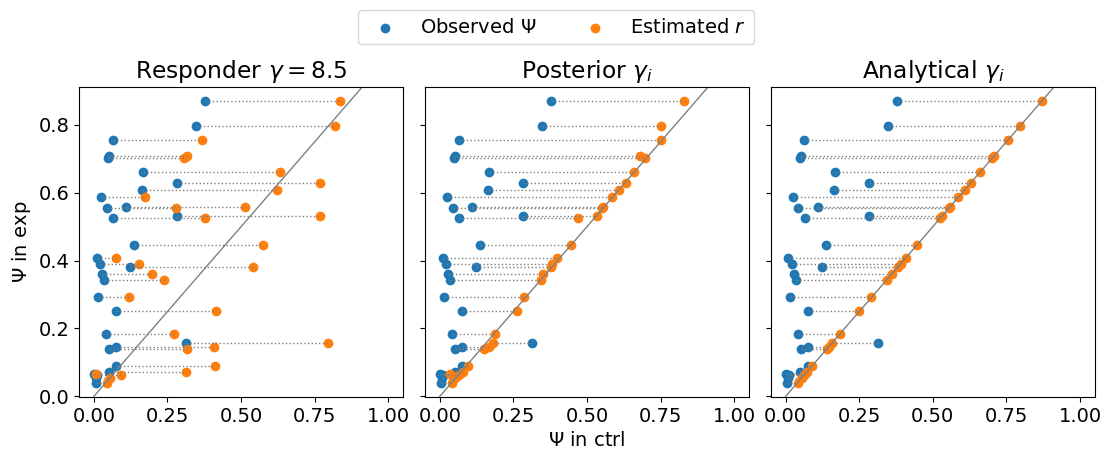

In [592]:
s,e = -0.05,1.05
s2 = -0.05
wr = (e-s2)/(e-s)
f,axes = plt.subplots(1,3,figsize=(11,4),constrained_layout=True,sharey=True,width_ratios=(wr,1,1))
cols = ['r_fix','r_i','r_emp']
names = [rf'Responder $\gamma = {GAMMA_FIX}$', r'Posterior $\gamma_i$', r'Analytical $\gamma_i$']

flag=False
for ax,name,col in zip(axes,names,cols):
    #flag = ax==axes[2]
    plot(aa,col,ax=ax,label=flag)
    ax.set_title(name)
    ax.set_xlim(s,e)
axes[0].set_ylabel('$\Psi$ in exp')
axes[1].set_xlabel('$\Psi$ in ctrl')

axes[0].set_xlim(s2,e)

h,l = axes[0].get_legend_handles_labels()
f.legend(h,l,loc='lower center',bbox_to_anchor=(0.5,1.0),ncol=2)

In [594]:
f.savefig('./figures/Fig5.pdf',bbox_inches='tight')

In [ ]:
f,ax = plt.subplots(1,2,figsize=(8,4),constrained_layout=True,sharex=True,sharey=True)
ax = ax[::-1]
ax[0].scatter(aa.ctrl,aa.chx,label='Observed $\Psi$')
ax[1].scatter(aa.ctrl_psi,aa.exp_psi,label='Observed $\Psi$')
ax[0].scatter(aa.r_qpcr,aa.chx,label='Estimated $r$')
ax[1].scatter(aa.r_rnaseq,aa.exp_psi,label='Estimated $r$')

txt1 = []
txt2 = []

for _,row in aa.iterrows():
    ax[0].plot([row.ctrl,row.r_qpcr],[row.chx,row.chx],lw=1,ls=':',c='grey')
    ax[1].plot([row.ctrl_psi,row.r_rnaseq],[row.exp_psi,row.exp_psi],lw=1,ls=':',c='grey')

    txt1.append(ax[0].text(row.r_qpcr,row.chx,row.gene_name,va='bottom',c='grey',fontsize=11))
    txt2.append(ax[1].text(row.r_rnaseq,row.exp_psi,row.gene_name,va='bottom',c='grey',fontsize=11))

    

prob 0.972972972972973


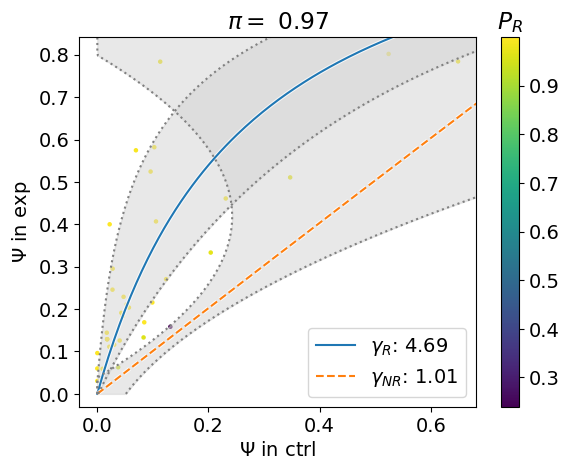

In [459]:
f,ax = plt.subplots()
key = 'rsf_chx'
ctrl = ase[ase.experiment==key]
exper = use[use.experiment==key].merge(sets[sets.set1==1]).copy()
n_init = 50

lambda_sigma = 0
success,params,prob,other,results = plot_dataset(exper,ctrl,n_init=n_init,ax=ax,lambda_sigma=lambda_sigma)
exper['prob'] = prob

In [455]:
exper

,gene_name,src,event_id,event_type,from,ctrl,chx,set1,set2,n_exp,...,set4,gamma_i,prob,exp_psi,ctrl_psi,gamma,r_qpcr,r_rnaseq,r_qpcr_fix,r_rnaseq_fix
0,NCSTN,nmdj_anno,ENSG00000162736_3,EE,our,0.127083,0.194583,1,1,3,...,1,6.343605,0.999710,0.228956,0.047244,12,0.480123,0.239289,0.635969,0.373057
1,CLK1,nmdj_anno,ENSG00000013441_1,EE,our,0.322667,0.738333,1,1,5,...,1,27.648434,0.995278,0.783688,0.113208,12,0.929434,0.779229,0.851114,0.605042
2,NSD1,nmdj_novel,ENSG00000165671.22_4,PE|PE+A3SS,our,0.008239,0.035603,1,0,2,...,0,7.577928,0.999882,0.111111,0.021583,12,0.059225,0.143220,0.090653,0.209302
3,EZH2,nmdj_anno,ENSG00000106462_1,PE,our,0.191957,0.266087,1,1,2,...,1,5.661337,0.999936,0.191136,0.043137,12,0.573541,0.203330,0.740306,0.351064
4,SAT1,nmdj_anno,ENSG00000130066_0,PE,our,0.155932,0.473051,1,1,6,...,1,3.642735,0.996366,0.801940,0.524191,12,0.402255,0.800524,0.689139,0.929677
5,PATL1,nmdj_novel,ENSG00000166889.14_0,PE|PE2|complex,our,0.017842,0.207103,1,0,6,...,1,16.104197,0.998079,0.295337,0.027624,12,0.226333,0.313896,0.178975,0.254237
6,RIC8B,nmdj_anno,ENSG00000111785_2,PE3,our,0.054773,0.243043,1,0,1,...,0,44.842873,0.997219,0.400000,0.022222,12,0.722106,0.504744,0.410155,0.214286
7,PSPC1,nmdj_anno,ENSG00000121390_0,alt_end,our,0.213158,0.279474,1,0,5,...,0,2.607742,0.996232,0.270677,0.123772,12,0.413986,0.269197,0.764752,0.628952
8,CLK3,nmdj_anno,ENSG00000179335_0,EE,our,0.171250,0.501667,1,1,3,...,0,12.555646,0.998533,0.245810,0.027335,12,0.721794,0.260821,0.712614,0.252189


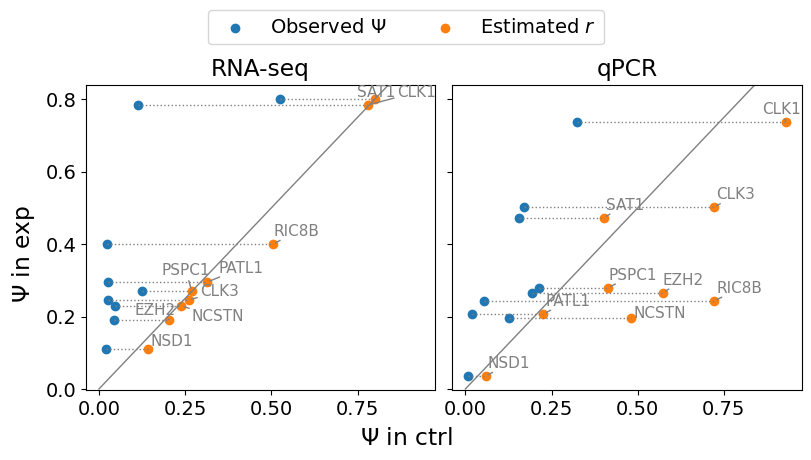

In [452]:
from adjustText import adjust_text

f,ax = plt.subplots(1,2,figsize=(8,4),constrained_layout=True,sharex=True,sharey=True)
ax = ax[::-1]
ax[0].scatter(aa.ctrl,aa.chx,label='Observed $\Psi$')
ax[1].scatter(aa.ctrl_psi,aa.exp_psi,label='Observed $\Psi$')
ax[0].scatter(aa.r_qpcr,aa.chx,label='Estimated $r$')
ax[1].scatter(aa.r_rnaseq,aa.exp_psi,label='Estimated $r$')

txt1 = []
txt2 = []

for _,row in aa.iterrows():
    ax[0].plot([row.ctrl,row.r_qpcr],[row.chx,row.chx],lw=1,ls=':',c='grey')
    ax[1].plot([row.ctrl_psi,row.r_rnaseq],[row.exp_psi,row.exp_psi],lw=1,ls=':',c='grey')

    txt1.append(ax[0].text(row.r_qpcr,row.chx,row.gene_name,va='bottom',c='grey',fontsize=11))
    txt2.append(ax[1].text(row.r_rnaseq,row.exp_psi,row.gene_name,va='bottom',c='grey',fontsize=11))

for a,t in zip(ax,['qPCR','RNA-seq']):
    a.legend()
    a.set_title(t)
    xl,yl = a.get_xlim(),a.get_ylim()
    a.plot([0,1],[0,1],lw=1,c='grey')
    a.set_xlim(xl)
    a.set_ylim(yl)
f.supxlabel('$\Psi$ in ctrl')
f.supylabel('$\Psi$ in exp')

objs1 = ax[0].get_lines()#+ax[0].collections
objs2 = ax[1].get_lines()#+ax[1].collections

objs1 = ax[0].collections
objs2 = ax[1].collections

adjust_text(txt1,ax=ax[0],arrowprops=dict(arrowstyle="-", color='grey'),x=aa.r_qpcr,y=aa.chx)
adjust_text(txt2,ax=ax[1],arrowprops=dict(arrowstyle="-", color='grey'),x=aa.r_rnaseq,y=aa.exp_psi)
''

h,l = ax[1].get_legend_handles_labels()
f.legend(h,l,loc='lower center',bbox_to_anchor=(0.5,1.0),ncol=2)
ax[0].get_legend().remove()
ax[1].get_legend().remove()

In [468]:
def plot(aa,gamma,title,legend=False):
    aa['gamma'] = gamma
    aa['r_qpcr_fix'] = hf.psi2r(aa.ctrl,aa.gamma)
    aa['r_rnaseq_fix'] = hf.psi2r(aa.ctrl_psi,aa.gamma)

    f,ax = plt.subplots(1,2,figsize=(8,4),constrained_layout=True,sharex=True,sharey=True)
    ax = ax[::-1]
    ax[0].scatter(aa.ctrl,aa.chx,label='Observed $\Psi$')
    ax[1].scatter(aa.ctrl_psi,aa.exp_psi,label='Observed $\Psi$')
    ax[0].scatter(aa.r_qpcr_fix,aa.chx,label='Estimated $r$')
    ax[1].scatter(aa.r_rnaseq_fix,aa.exp_psi,label='Estimated $r$')
    
    txt1 = []
    txt2 = []
    
    for _,row in aa.iterrows():
        ax[0].plot([row.ctrl,row.r_qpcr_fix],[row.chx,row.chx],lw=1,ls=':',c='grey')
        ax[1].plot([row.ctrl_psi,row.r_rnaseq_fix],[row.exp_psi,row.exp_psi],lw=1,ls=':',c='grey')
    
        txt1.append(ax[0].text(row.r_qpcr_fix,row.chx,row.gene_name,va='bottom',c='grey',fontsize=11))
        txt2.append(ax[1].text(row.r_rnaseq_fix,row.exp_psi,row.gene_name,va='bottom',c='grey',fontsize=11))
    
    for a,t in zip(ax,['qPCR','RNA-seq']):
        a.legend()
        a.set_title(t)
        xl,yl = a.get_xlim(),a.get_ylim()
        a.plot([0,1],[0,1],lw=1,c='grey')
        a.set_xlim(xl)
        a.set_ylim(yl)
    f.supxlabel('$\Psi$ in ctrl')
    f.supylabel('$\Psi$ in exp')
    
    objs1 = ax[0].get_lines()#+ax[0].collections
    objs2 = ax[1].get_lines()#+ax[1].collections
    
    objs1 = ax[0].collections
    objs2 = ax[1].collections
    
    adjust_text(txt1,ax=ax[0],arrowprops=dict(arrowstyle="-", color='grey'),x=aa.r_qpcr_fix,y=aa.chx)
    adjust_text(txt2,ax=ax[1],arrowprops=dict(arrowstyle="-", color='grey'),x=aa.r_rnaseq_fix,y=aa.exp_psi)
    ''
    
    h,l = ax[1].get_legend_handles_labels()
    if legend:
        f.legend(h,l,loc='lower center',bbox_to_anchor=(0.5,1.0),ncol=2)
    ax[0].get_legend().remove()
    ax[1].get_legend().remove()
    f.suptitle(title)
    return f

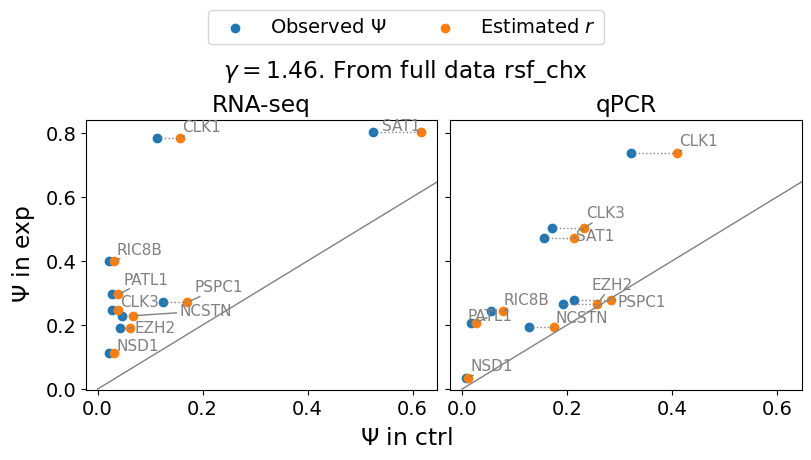

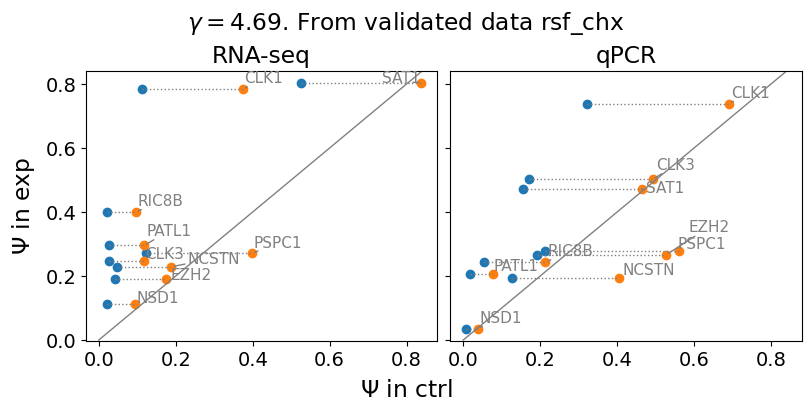

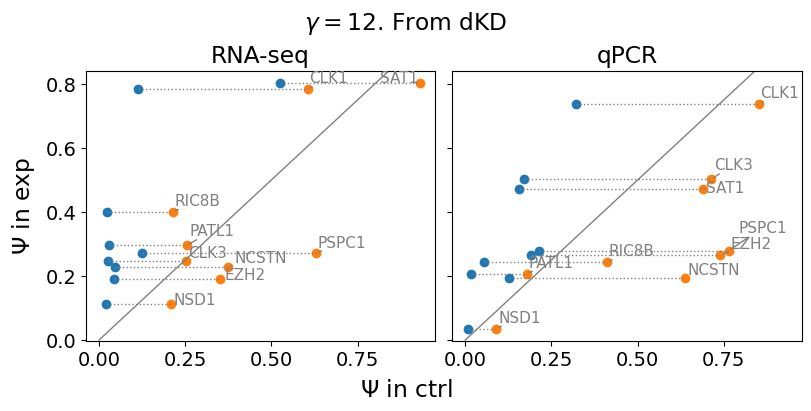

In [469]:
f = plot(aa,1.46,'$\gamma = 1.46$. From full data rsf_chx',legend=True)
f = plot(aa,4.69,'$\gamma = 4.69$. From validated data rsf_chx')
f = plot(aa,12,'$\gamma = 12$. From dKD')

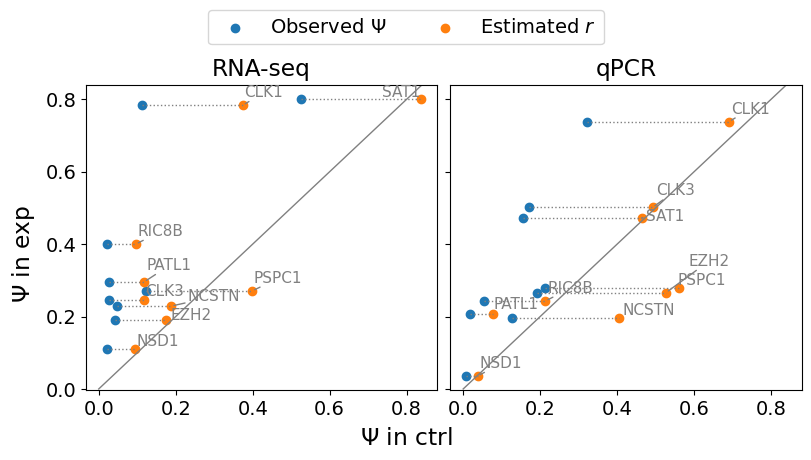

In [461]:
from adjustText import adjust_text

f,ax = plt.subplots(1,2,figsize=(8,4),constrained_layout=True,sharex=True,sharey=True)
ax = ax[::-1]
ax[0].scatter(aa.ctrl,aa.chx,label='Observed $\Psi$')
ax[1].scatter(aa.ctrl_psi,aa.exp_psi,label='Observed $\Psi$')
ax[0].scatter(aa.r_qpcr_fix,aa.chx,label='Estimated $r$')
ax[1].scatter(aa.r_rnaseq_fix,aa.exp_psi,label='Estimated $r$')

txt1 = []
txt2 = []

for _,row in aa.iterrows():
    ax[0].plot([row.ctrl,row.r_qpcr_fix],[row.chx,row.chx],lw=1,ls=':',c='grey')
    ax[1].plot([row.ctrl_psi,row.r_rnaseq_fix],[row.exp_psi,row.exp_psi],lw=1,ls=':',c='grey')

    txt1.append(ax[0].text(row.r_qpcr_fix,row.chx,row.gene_name,va='bottom',c='grey',fontsize=11))
    txt2.append(ax[1].text(row.r_rnaseq_fix,row.exp_psi,row.gene_name,va='bottom',c='grey',fontsize=11))

for a,t in zip(ax,['qPCR','RNA-seq']):
    a.legend()
    a.set_title(t)
    xl,yl = a.get_xlim(),a.get_ylim()
    a.plot([0,1],[0,1],lw=1,c='grey')
    a.set_xlim(xl)
    a.set_ylim(yl)
f.supxlabel('$\Psi$ in ctrl')
f.supylabel('$\Psi$ in exp')

objs1 = ax[0].get_lines()#+ax[0].collections
objs2 = ax[1].get_lines()#+ax[1].collections

objs1 = ax[0].collections
objs2 = ax[1].collections

adjust_text(txt1,ax=ax[0],arrowprops=dict(arrowstyle="-", color='grey'),x=aa.r_qpcr_fix,y=aa.chx)
adjust_text(txt2,ax=ax[1],arrowprops=dict(arrowstyle="-", color='grey'),x=aa.r_rnaseq_fix,y=aa.exp_psi)
''

h,l = ax[1].get_legend_handles_labels()
f.legend(h,l,loc='lower center',bbox_to_anchor=(0.5,1.0),ncol=2)
ax[0].get_legend().remove()
ax[1].get_legend().remove()

### Bayes model for qPCR psi

In [520]:
sets = pd.read_csv('./nmd_kd_experimental/USE_sets.tsv',sep='\t')
aa = sets[sets.ctrl.notna()].copy()

In [522]:
aa['ctrl_psi'] = aa.ctrl
aa['exp_psi'] = aa.chx
aa[['gene_name','src',
    'event_id','event_type','ctrl_psi','exp_psi']].to_csv('./nmd_kd_experimental/qpcr_data_bayes.tsv',
                                                          sep='\t',index=False)

In [526]:
python = r'C:\Users\zavil\miniconda3\envs\pymc\python.exe'
script = './fit_bayes_new.py'

cmd1 = f'''{python} -u {script} \
--data "./nmd_kd_experimental/qpcr_data_bayes.tsv" \
--prefix "./nmd_inactivation_data/bayes/qpcr/default"
'''
print(cmd1)

C:\Users\zavil\miniconda3\envs\pymc\python.exe -u ./fit_bayes_new.py --data "./nmd_kd_experimental/qpcr_data_bayes.tsv" --prefix "./nmd_inactivation_data/bayes/qpcr/default"



In [527]:
run = BackgroundMCMC(
    cmd1,
    title=f"qpcr",
    update_interval=5
)

run.start()

## Figure with ENCODE

In [644]:
files = list(glob.glob('../../arkuda_backup/expression/DE/ENCODE/KD/deseq_res_cell_line/*'))

In [646]:
meta = pd.read_csv('../../arkuda_backup/expression/DE/ENCODE/KD/encode_metadata.tsv',sep='\t')

In [648]:
meta

,target,cell_line,exper_id,ctrl_id,bam_name,sample_type,replicate,sample_id,KD_ctrl_id
0,AARS,HepG2,ENCSR547NWD,ENCSR856ZRV,ENCFF036KPI,exp,1,32,ENCSR547NWD_ENCSR856ZRV
1,AARS,K562,ENCSR599UDS,ENCSR572FFX,ENCFF935KUC,exp,1,936,ENCSR599UDS_ENCSR572FFX
2,AATF,HepG2,ENCSR424YSV,ENCSR003EKR,ENCFF900FTG,exp,1,896,ENCSR424YSV_ENCSR003EKR
3,AATF,K562,ENCSR973QSV,ENCSR815CVQ,ENCFF458KRT,exp,1,457,ENCSR973QSV_ENCSR815CVQ
4,ABCF1,HepG2,ENCSR610VTA,ENCSR067GHD,ENCFF875ZVH,exp,1,870,ENCSR610VTA_ENCSR067GHD
...,...,...,...,...,...,...,...,...,...
1875,YWHAG,HepG2,ENCSR204QKA,ENCSR225PRV,ENCFF085MQH,ctrl,2,1011,ENCSR204QKA_ENCSR225PRV
1876,ZC3H8,K562,ENCSR448JAM,ENCSR718EWL,ENCFF743GZQ,ctrl,2,740,ENCSR448JAM_ENCSR718EWL
1877,ZNF622,HepG2,ENCSR518JXY,ENCSR691IVR,ENCFF279WLO,ctrl,2,284,ENCSR518JXY_ENCSR691IVR
1878,ZRANB2,HepG2,ENCSR081QQH,ENCSR491FOC,ENCFF202ZWS,ctrl,2,209,ENCSR081QQH_ENCSR491FOC


In [647]:
ids = meta[meta.logFC<-3].KD_ctrl_id.tolist()
sfiles = [i for i in files if os.path.basename(i).rpartition('_')[0] in ids]

AttributeError: 'DataFrame' object has no attribute 'logFC'

In [122]:
%%time
de = []
for i in sfiles:
    name = os.path.basename(i).rpartition('_')[0]
    aa = pd.read_csv(i,sep='\t',usecols=['log2FoldChange','padj'])
    aa['gene_id'] = aa.index.map(lambda x: x.split('.')[0])
    aa['KD_ctrl_id'] = name
    de.append(aa)
de = pd.concat(de)

CPU times: total: 438 ms
Wall time: 433 ms


In [123]:
dpsi = pd.read_csv('../../arkuda_backup/unproductive_splicing/data/TCGA/input/rbpkd_dpsi/united.tsv',sep='\t')

In [124]:
meta['experiment'] = meta.target+'_'+meta.cell_line+'_KD'

In [125]:
mapping = meta[['experiment','KD_ctrl_id']].drop_duplicates()
mapping.nunique()

experiment    470
KD_ctrl_id    470
dtype: int64

In [126]:
catalog = pd.read_csv('../../arkuda_backup/unproductive_splicing/data/TCGA/input/catalogs/united.tsv',sep='\t')
cat = catalog[['gene_id','src','event_id']].drop_duplicates()

In [127]:
de = de.merge(mapping).drop('KD_ctrl_id',axis=1)

In [128]:
dpsi['dpsi'] = dpsi.exp_psi-dpsi.ctrl_psi

In [129]:
resp = pd.read_csv('./nmd_kd_experimental/mixture_responders_dkd.tsv',sep='\t')
gamma = pd.read_csv('./nmd_kd_experimental/dkd_all_uses_with_gamma_i.tsv',sep='\t')
resp = resp[['src','event_id','responder']].merge(gamma[['src','event_id','gamma_i']])

In [130]:
resp['gamma_bin'] = pd.cut(resp.gamma_i,[0,25,461])
resp['gamma_bin2'] = pd.cut(resp.gamma_i,[0,25,50,100,461])

In [131]:
import gc
gc.collect()

354

In [132]:
resp = cat.merge(resp)

In [133]:
%%time
m = resp.merge(de).merge(dpsi)

CPU times: total: 2 s
Wall time: 2.02 s


In [168]:
condition = [True]*len(m)
condition = (m.pval<0.05)&(m.padj<1)
tmp = m[condition].copy()

In [169]:
tmp = tmp.sort_values('responder',ascending=False).drop_duplicates(['experiment','gene_id']).iloc[::-1]

In [170]:
bins = [-1,-0.2,-0.1,0,0.1,0.2,0.3,1]
tmp['dpsi_bin'] = pd.cut(tmp.dpsi,bins=bins)
aa = tmp['dpsi_bin'].value_counts()
aa.loc[sorted(aa.index)]

dpsi_bin
(-1.0, -0.2]     445
(-0.2, -0.1]    1527
(-0.1, 0.0]     4108
(0.0, 0.1]      6054
(0.1, 0.2]      2381
(0.2, 0.3]       745
(0.3, 1.0]       295
Name: count, dtype: int64

In [209]:
from statsmodels.formula.api import ols
def get_ols_res(formula,df):
    results = ols(formula,df).fit()
    df = pd.DataFrame({
        "coef": results.params,
        "std_err": results.bse,
        "t": results.tvalues,
        "p_value": results.pvalues,
        "ci_lower": results.conf_int()[0],
        "ci_upper": results.conf_int()[1],
    })
    df['adj_R'] = results.rsquared_adj
    df['F_pval'] = results.f_pvalue
    return df

def p2star(p):
    thrs = [0.0001,0.001,0.01,0.05,0.1]
    star = ['****','***','**','*','·']
    for t,s in zip(thrs,star):
        if p<t:
            return s
    return ""


In [171]:
pairs = [((i,'Yes'),(i,'No')) for i in tmp.dpsi_bin.unique()]

p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

(-0.1, 0.0]_No vs. (-0.1, 0.0]_Yes: Mann-Whitney-Wilcoxon test two-sided with Bonferroni correction, P_val:1.699e-04 U_stat=1.936e+06
(0.0, 0.1]_No vs. (0.0, 0.1]_Yes: Mann-Whitney-Wilcoxon test two-sided with Bonferroni correction, P_val:2.455e-09 U_stat=4.751e+06
(0.3, 1.0]_No vs. (0.3, 1.0]_Yes: Mann-Whitney-Wilcoxon test two-sided with Bonferroni correction, P_val:1.236e-02 U_stat=1.269e+04
(0.2, 0.3]_No vs. (0.2, 0.3]_Yes: Mann-Whitney-Wilcoxon test two-sided with Bonferroni correction, P_val:9.168e-03 U_stat=7.803e+04


Text(0.02, 0.5, '$\\Delta\\Psi$')

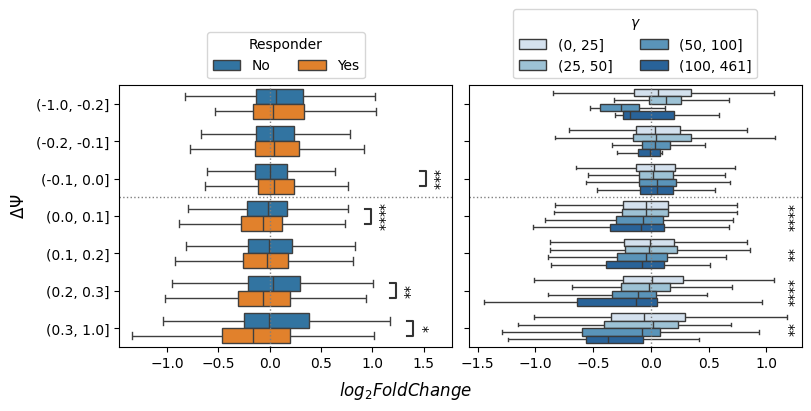

In [219]:
f,(ax,ax2) = plt.subplots(1,2,figsize=(8,4),sharey=True,constrained_layout=True)
sns.boxplot(data=tmp,x='log2FoldChange',y='dpsi_bin',hue='responder',showfliers=False,ax=ax)
xl = ax.get_xlim()
#sns.stripplot(data=tmp,x='log2FoldChange',y='dpsi_bin',hue='responder',dodge=True,palette='grey',alpha=0.5,s=2,legend=False)
ax.set_xlim(xl)
ax.axvline(0,lw=1,ls=':',c='grey')
ax.axhline(2.5,lw=1,ls=':',c='grey')

from statannotations.Annotator import Annotator

pairs = [((i,'Yes'),(i,'No')) for i in tmp.dpsi_bin.unique()]

annotator = Annotator(
    ax,
    pairs,
    data=tmp,
    hue="responder",
    x="log2FoldChange",
    y='dpsi_bin',
    orient='h'
)

annotator.configure(
    test="Mann-Whitney",
    text_format="star",
    loc="inside",
    comparisons_correction="bonferroni",
    hide_non_significant=True
)

annotator.apply_and_annotate()

sns.boxplot(data=tmp,x='log2FoldChange',y='dpsi_bin',hue='gamma_bin2',showfliers=False,palette='Blues',ax=ax2)
ax2.axvline(0,lw=1,ls=':',c='grey')
ax2.axhline(2.5,lw=1,ls=':',c='grey')

ps = []
formula = 'log2FoldChange ~ gamma_i'
for _,aa in tmp.groupby('dpsi_bin',observed=True):
    ps.append(get_ols_res(formula,aa).loc['gamma_i','p_value'])
padj = multipletests(ps,method='bonferroni')[1]

import matplotlib.transforms as transforms

trans = transforms.blended_transform_factory(ax2.transAxes,ax2.transData)
for i,p in enumerate(padj):
    star = p2star(p)
    ax2.text(1,i,star,ha='right',va='center',transform=trans,rotation=90)

ax2.legend(title="$\gamma$")

for a in [ax,ax2]:
    a.set_xlabel(None)
    a.set_ylabel(None)

ax.legend(loc='lower center',bbox_to_anchor=(0.5,1),ncol=2,title='Responder')
ax2.legend(loc='lower center',bbox_to_anchor=(0.5,1),ncol=2,title='$\gamma$')
f.supxlabel('$log_2 FoldChange$')
f.supylabel('$\Delta\Psi$')

p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

(-0.1, 0.0]_No vs. (-0.1, 0.0]_Yes: Mann-Whitney-Wilcoxon test two-sided with Bonferroni correction, P_val:1.699e-04 U_stat=1.936e+06
(0.0, 0.1]_No vs. (0.0, 0.1]_Yes: Mann-Whitney-Wilcoxon test two-sided with Bonferroni correction, P_val:2.455e-09 U_stat=4.751e+06
(0.3, 1.0]_No vs. (0.3, 1.0]_Yes: Mann-Whitney-Wilcoxon test two-sided with Bonferroni correction, P_val:1.236e-02 U_stat=1.269e+04
(0.2, 0.3]_No vs. (0.2, 0.3]_Yes: Mann-Whitney-Wilcoxon test two-sided with Bonferroni correction, P_val:9.168e-03 U_stat=7.803e+04


C:\Users\zavil\AppData\Local\Temp\ipykernel_12180\3485233797.py:109: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  a.set_xticklabels(a.get_xticklabels(),rotation=45,ha='right',rotation_mode='anchor')
C:\Users\zavil\AppData\Local\Temp\ipykernel_12180\3485233797.py:109: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  a.set_xticklabels(a.get_xticklabels(),rotation=45,ha='right',rotation_mode='anchor')


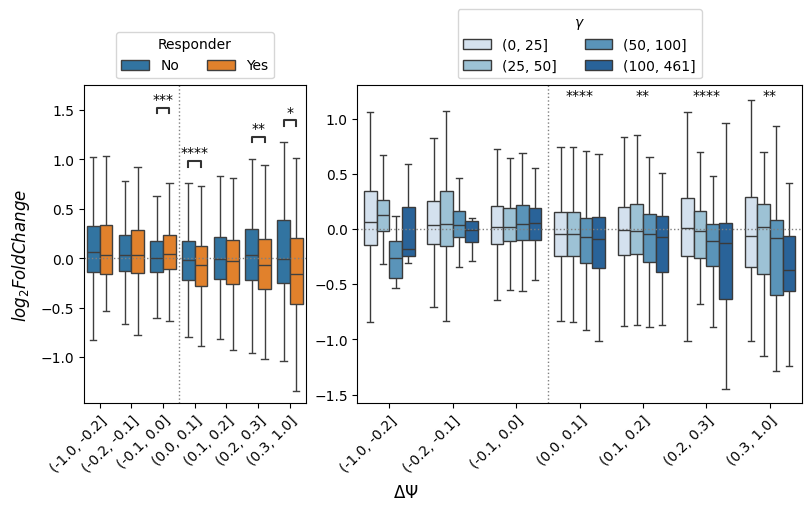

In [226]:
f, (ax, ax2) = plt.subplots(
    1, 2,
    figsize=(8, 5),
    sharex=True, 
    constrained_layout=True,
    width_ratios=(1,2)
)

# --- Left plot ---
sns.boxplot(
    data=tmp,
    x='dpsi_bin',
    y='log2FoldChange',
    hue='responder',
    showfliers=False,
    ax=ax
)

yl = ax.get_ylim()
ax.set_ylim(yl)

ax.axhline(0, lw=1, ls=':', c='grey')   # vertical -> horizontal
ax.axvline(2.5, lw=1, ls=':', c='grey')

from statannotations.Annotator import Annotator

pairs = [((i, 'Yes'), (i, 'No')) for i in tmp.dpsi_bin.unique()]

annotator = Annotator(
    ax,
    pairs,
    data=tmp,
    hue="responder",
    x="dpsi_bin",
    y='log2FoldChange',
    orient='v'   # vertical orientation
)

annotator.configure(
    test="Mann-Whitney",
    text_format="star",
    loc="inside",
    comparisons_correction="bonferroni",
    hide_non_significant=True
)

annotator.apply_and_annotate()

# --- Right plot ---
sns.boxplot(
    data=tmp,
    x='dpsi_bin',
    y='log2FoldChange',
    hue='gamma_bin2',
    showfliers=False,
    palette='Blues',
    ax=ax2
)

ax2.axhline(0, lw=1, ls=':', c='grey')
ax2.axvline(2.5, lw=1, ls=':', c='grey')

ps = []
formula = 'log2FoldChange ~ gamma_i'

for _, aa in tmp.groupby('dpsi_bin', observed=True):
    ps.append(get_ols_res(formula, aa).loc['gamma_i', 'p_value'])

padj = multipletests(ps, method='bonferroni')[1]

import matplotlib.transforms as transforms

# x in data coords, y in axes coords
trans = transforms.blended_transform_factory(ax2.transData, ax2.transAxes)

for i, p in enumerate(padj):
    star = p2star(p)
    ax2.text(
        i, 0.99, star,
        ha='center',
        va='top',
        transform=trans
    )

ax2.legend(title="$\gamma$")

for a in [ax, ax2]:
    a.set_xlabel(None)
    a.set_ylabel(None)

ax.legend(
    loc='lower center',
    bbox_to_anchor=(0.5, 1),
    ncol=2,
    title='Responder'
)

ax2.legend(
    loc='lower center',
    bbox_to_anchor=(0.5, 1),
    ncol=2,
    title='$\gamma$'
)

f.supxlabel('$\Delta\Psi$')
f.supylabel('$log_2 FoldChange$')

for a in [ax,ax2]:
    a.set_xticklabels(a.get_xticklabels(),rotation=45,ha='right',rotation_mode='anchor')

p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

(-0.1, 0.0]_No vs. (-0.1, 0.0]_Yes: Mann-Whitney-Wilcoxon test two-sided with Bonferroni correction, P_val:1.699e-04 U_stat=1.936e+06
(0.0, 0.1]_No vs. (0.0, 0.1]_Yes: Mann-Whitney-Wilcoxon test two-sided with Bonferroni correction, P_val:2.455e-09 U_stat=4.751e+06
(0.3, 1.0]_No vs. (0.3, 1.0]_Yes: Mann-Whitney-Wilcoxon test two-sided with Bonferroni correction, P_val:1.236e-02 U_stat=1.269e+04
(0.2, 0.3]_No vs. (0.2, 0.3]_Yes: Mann-Whitney-Wilcoxon test two-sided with Bonferroni correction, P_val:9.168e-03 U_stat=7.803e+04


C:\Users\zavil\AppData\Local\Temp\ipykernel_12180\1178794850.py:109: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  a.set_xticklabels(a.get_xticklabels(),rotation=45,ha='right',rotation_mode='anchor')
C:\Users\zavil\AppData\Local\Temp\ipykernel_12180\1178794850.py:109: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  a.set_xticklabels(a.get_xticklabels(),rotation=45,ha='right',rotation_mode='anchor')


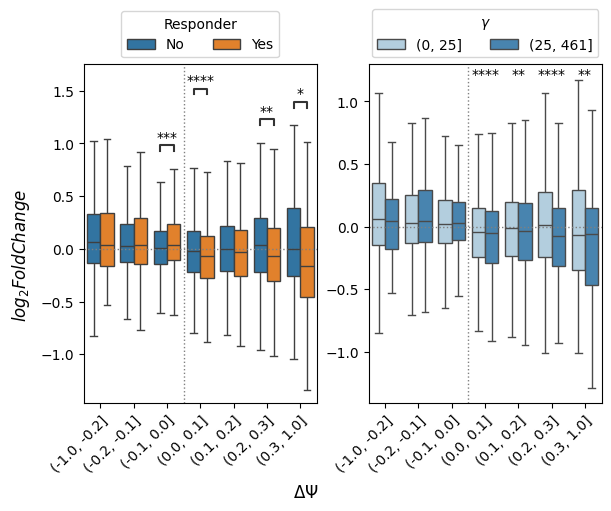

In [227]:
f, (ax, ax2) = plt.subplots(
    1, 2,
    figsize=(6, 5),
    sharex=True, 
    constrained_layout=True,
    width_ratios=(1,1)
)

# --- Left plot ---
sns.boxplot(
    data=tmp,
    x='dpsi_bin',
    y='log2FoldChange',
    hue='responder',
    showfliers=False,
    ax=ax
)

yl = ax.get_ylim()
ax.set_ylim(yl)

ax.axhline(0, lw=1, ls=':', c='grey')   # vertical -> horizontal
ax.axvline(2.5, lw=1, ls=':', c='grey')

from statannotations.Annotator import Annotator

pairs = [((i, 'Yes'), (i, 'No')) for i in tmp.dpsi_bin.unique()]

annotator = Annotator(
    ax,
    pairs,
    data=tmp,
    hue="responder",
    x="dpsi_bin",
    y='log2FoldChange',
    orient='v'   # vertical orientation
)

annotator.configure(
    test="Mann-Whitney",
    text_format="star",
    loc="inside",
    comparisons_correction="bonferroni",
    hide_non_significant=True
)

annotator.apply_and_annotate()

# --- Right plot ---
sns.boxplot(
    data=tmp,
    x='dpsi_bin',
    y='log2FoldChange',
    hue='gamma_bin',
    showfliers=False,
    palette='Blues',
    ax=ax2
)

ax2.axhline(0, lw=1, ls=':', c='grey')
ax2.axvline(2.5, lw=1, ls=':', c='grey')

ps = []
formula = 'log2FoldChange ~ gamma_i'

for _, aa in tmp.groupby('dpsi_bin', observed=True):
    ps.append(get_ols_res(formula, aa).loc['gamma_i', 'p_value'])

padj = multipletests(ps, method='bonferroni')[1]

import matplotlib.transforms as transforms

# x in data coords, y in axes coords
trans = transforms.blended_transform_factory(ax2.transData, ax2.transAxes)

for i, p in enumerate(padj):
    star = p2star(p)
    ax2.text(
        i, 0.99, star,
        ha='center',
        va='top',
        transform=trans
    )

ax2.legend(title="$\gamma$")

for a in [ax, ax2]:
    a.set_xlabel(None)
    a.set_ylabel(None)

ax.legend(
    loc='lower center',
    bbox_to_anchor=(0.5, 1),
    ncol=2,
    title='Responder'
)

ax2.legend(
    loc='lower center',
    bbox_to_anchor=(0.5, 1),
    ncol=2,
    title='$\gamma$'
)

f.supxlabel('$\Delta\Psi$')
f.supylabel('$log_2 FoldChange$')

for a in [ax,ax2]:
    a.set_xticklabels(a.get_xticklabels(),rotation=45,ha='right',rotation_mode='anchor')

## Supplementary 

### SF1

In [1209]:
import mm
from scipy.optimize import minimize

In [1210]:
bindpsi = pd.read_csv('./nmd_inactivation_data/binASE_master_table.tsv',
                      sep='\t')
ctrl = bindpsi[bindpsi.experiment=='HeLa dKD'].copy()

In [1211]:
N=1000
frac = 0.5
baseline = []
for _ in range(N):
    smpl = ctrl.sample(frac=frac)
    x_control = smpl.exp_psi.to_numpy()
    y_control = smpl.ctrl_psi.to_numpy()

    a0_hat = minimize(
        mm.residuals_control,
        x0=[2],
        args = (x_control,y_control),
        bounds=[(0.01, 500)]
    ).x[0]
    baseline.append(a0_hat)

In [1212]:
x_control = ctrl.exp_psi.to_numpy()
y_control = ctrl.ctrl_psi.to_numpy()

In [1213]:
l,h = np.quantile(baseline,2.5/100),np.quantile(baseline,1-2.5/100)

In [1214]:
x = np.linspace(0,1,100)
low,high = mm.hyperbolic_curve(x, l),mm.hyperbolic_curve(x, h)

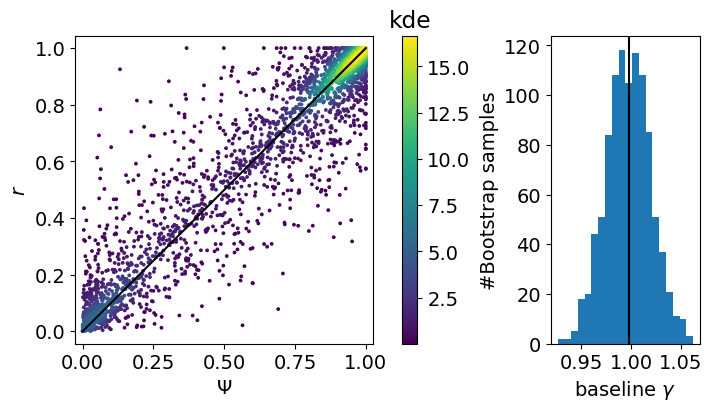

In [1215]:
f,(ax,ax2) = plt.subplots(1,2,figsize=(7,4),width_ratios=(2,1),constrained_layout=True)
z,idx = hf.plot2d(y_control,x_control)
im = ax.scatter(y_control[idx],x_control[idx],c=z[idx],s=3)
cbar = plt.colorbar(im)
cbar.ax.set_title('kde')
ax2.hist(baseline,bins=20)
ax.axis('equal')
ax.set_xlabel(r'$\Psi$')
ax.set_ylabel(r'$r$')
ax2.set_ylabel('#Bootstrap samples')
ax2.set_xlabel(r'baseline $\gamma$')

med = np.median(baseline)
ax2.axvline(med,c='black')

y = np.linspace(0,1,100)
x = mm.hyperbolic_curve(y,med)
ax.plot(x,y,c='black')

In [1216]:
f.savefig('./figures/SF1.pdf',bbox_inches='tight')

### SF2

In [460]:
gamma = pd.read_csv('./nmd_inactivation_data/united_use_master_table_with_gamma_i.tsv',sep='\t')

In [462]:
gamma = gamma[gamma.experiment=='HeLa_dKD'].copy()

In [473]:
gamma['eta'] = np.log10(gamma.gamma_emp)

Text(0, 0.5, 'Density')

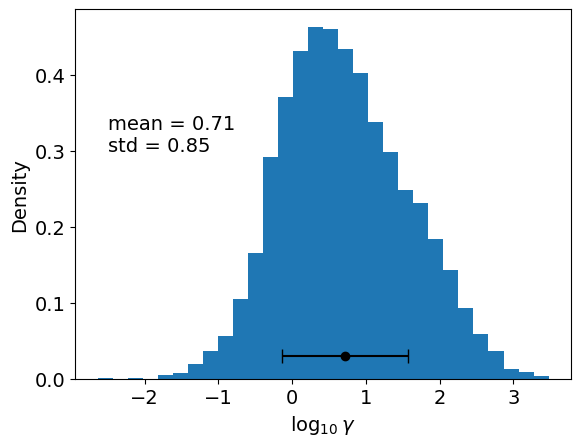

In [500]:
plt.hist(gamma.eta,bins=30,density=True)
#sns.kdeplot(x=gamma.eta)
plt.xlabel(r'$\log_{10} \gamma$')
desc = gamma.eta.describe()
y = 0.03
plt.scatter(desc['mean'],y,c='black')
plt.errorbar(desc['mean'],y,xerr=desc['std'],c='black',capsize=5)
txt = f'mean = {desc["mean"]:.2f}\nstd = {desc["std"]:.2f}'
plt.text(-2.5,0.3,txt)
plt.ylabel('Density')

### SF3

[Jump here](#sf3)

### SF4

In [501]:
res = pd.read_csv('./nmd_inactivation_data/mixture_model_bootstrapping.tsv',sep='\t')

In [505]:
res = res[res.experiment.isin(order)].copy()
res.experiment = res.experiment.astype('category').cat.reorder_categories(order)

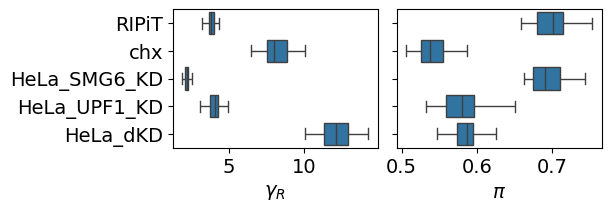

In [515]:
params = ['a1_hat', 'pi_hat']
names = [r'$\gamma_R$',r'$\pi$']
len(params)
f,axes = plt.subplots(1,2,figsize=(6,2),sharey=True,constrained_layout=True)
axes = axes.flatten()
for param,ax,name in zip(params,axes,names):
    sns.boxplot(data=res,x=param,y='experiment',ax=ax,showfliers=False)
    ax.set_xlabel(name)
    ax.set_ylabel(None)

### Tables

#### ST1

In [386]:
sets = pd.read_csv('./nmd_kd_experimental/USE_sets.tsv',sep='\t')

In [393]:
catalog = pd.read_csv('../../arkuda_backup/unproductive_splicing/data/TCGA/input/catalogs/united.tsv',sep='\t')

In [485]:
tab = sets[sets.set1==1].sort_values(['from','ctrl'])[['from','gene_name','src','event_id','event_type','ctrl','chx']]
tab

,from,gene_name,src,event_id,event_type,ctrl,chx
1335,literature,SRSF7,nmdj_anno,ENSG00000115875_0,PE,NaN,NaN
1933,literature,TIA1,nmdj_anno,ENSG00000116001_0,PE,NaN,NaN
4486,literature,SRSF3,nmdj_anno,ENSG00000112081_1,PE,NaN,NaN
4845,literature,TRA2A,nmdj_anno,ENSG00000164548_0,PE,NaN,NaN
6952,literature,SF1,nmdj_anno,ENSG00000168066_0,EE,NaN,NaN
7152,literature,SMNDC1,nmdj_anno,ENSG00000119953_0,PE|PE+A3SS,NaN,NaN
8106,literature,SRSF9,nmdj_anno,ENSG00000111786_0,PE,NaN,NaN
9918,literature,FUS,nmdj_anno,ENSG00000089280_0,EE,NaN,NaN
11153,literature,RBM39,nmdj_anno,ENSG00000131051_3,PE,NaN,NaN
11615,literature,SNRNP70,nmdj_anno,ENSG00000104852_0,PE,NaN,NaN


In [486]:
aa = tab[['gene_name','src','event_id']].merge(catalog[catalog.transcript_biotype=='nonsense_mediated_decay'])

In [487]:
aa['chrom'] = aa.long_id.apply(lambda x: x.partition('_')[0])
aa['strand'] = aa.long_id.apply(lambda x: x.rpartition('_')[-1])
aa['start'] = aa.long_id.apply(lambda x: min(map(int,x.split('_')[1:-1])))
aa['end'] = aa.long_id.apply(lambda x: max(map(int,x.split('_')[1:-1])))

In [488]:
aa = aa.groupby(['src','event_id','chrom','strand']).agg({'start':'min','end':'max'}).reset_index()

In [489]:
tab = tab.merge(aa)
tab.columns

Index(['from', 'gene_name', 'src', 'event_id', 'event_type', 'ctrl', 'chx',
       'chrom', 'strand', 'start', 'end'],
      dtype='object')

In [506]:
cols = ['from', 'gene_name', 'src', 'event_id', 'event_type', 'chrom', 'start', 'end', 'strand', 'ctrl', 'chx',]
tab[cols].drop_duplicates()

,from,gene_name,src,event_id,event_type,chrom,start,end,strand,ctrl,chx
0,literature,SRSF7,nmdj_anno,ENSG00000115875_0,PE,chr2,38748653,38749529,-,NaN,NaN
1,literature,TIA1,nmdj_anno,ENSG00000116001_0,PE,chr2,70224629,70227735,-,NaN,NaN
2,literature,SRSF3,nmdj_anno,ENSG00000112081_1,PE,chr6,36598983,36601152,+,NaN,NaN
3,literature,TRA2A,nmdj_anno,ENSG00000164548_0,PE,chr7,23522432,23531789,-,NaN,NaN
4,literature,SF1,nmdj_anno,ENSG00000168066_0,EE,chr11,64770408,64776498,-,NaN,NaN
5,literature,SMNDC1,nmdj_anno,ENSG00000119953_0,PE|PE+A3SS,chr10,110298790,110303468,-,NaN,NaN
6,literature,SRSF9,nmdj_anno,ENSG00000111786_0,PE,chr12,120464122,120465627,-,NaN,NaN
7,literature,FUS,nmdj_anno,ENSG00000089280_0,EE,chr16,31185179,31188325,+,NaN,NaN
8,literature,RBM39,nmdj_anno,ENSG00000131051_3,PE,chr20,35739017,35740824,-,NaN,NaN
9,literature,SNRNP70,nmdj_anno,ENSG00000104852_0,PE,chr19,49101471,49104634,+,NaN,NaN


In [509]:
refs = pd.read_excel('./lit_events_alex_mironov.xlsx')

refs = refs[['Gene', 'USE position', 'PMID']].copy()
refs.PMID = refs.PMID.str.replace('\n','').str.split(';').map(set)

refs = refs.groupby(['Gene','USE position']).PMID.agg(lambda x: set.union(*x)).reset_index()
refs.PMID = refs.PMID.apply(lambda x: ', '.join(x))

In [510]:
refs

,Gene,USE position,PMID
0,ACTR5,exon 7,24567363
1,CDH1,exon 14,27682981
2,CPSF7,exon 4,21325135
3,DLG4,exon 17,22246437
4,EZH2,exon 8a,32001512
5,FUS,exon 7,"24204307, 21358643"
6,GABBR1,exon 15,17679093
7,HNRNPA2B1,3'UTR,"23863836, 20946641"
8,HNRNPD,3'UTR,"29263134, 17000771"
9,HNRNPDL,3'UTR,29263134


In [502]:
match = pd.read_csv('./nmd_kd_experimental/match_lit_and_nmdcl_events - match_lit_and_nmdcl_events.csv')

In [512]:
aa = match[match.match==1][['gene2','position']]
aa.columns = ['Gene','USE position']

In [515]:
aa = aa.merge(refs,how='left')

In [516]:
aa.Gene.value_counts()

Gene
SNRNP70    3
SRSF7      2
FUS        1
HNRNPL     1
TIA1       1
TRA2A      1
SRSF3      1
SRSF9      1
SF1        1
SMNDC1     1
U2AF1      1
RBM39      1
Name: count, dtype: int64

In [519]:
pmids = aa.drop_duplicates('Gene').set_index('Gene').PMID

In [520]:
tab['pmid'] = tab.gene_name.map(pmids)
tab.loc[(tab.pmid.isna())|(tab['from']=='our'),'pmid'] = ''

In [526]:
!mkdir tables

In [527]:
tab.to_csv('./tables/ST1.csv',index=False)

#### ST2

hela dkd, ripit, frac hepg2, frac k562, hela: kds and chx
ribo-seq in UPF1 KD
GTEx

In [558]:
res = []

In [559]:
df = pd.read_csv('../../arkuda_backup/unproductive_splicing/data/TCGA/input/metadata/NMDKD_all.tsv',
                     sep='\t')
df = df[df.experiment!='HeLa_SMG7_KD']

In [561]:
df.rename(columns={'group':'sample_type'},inplace=True)

In [562]:
res.append(df.copy())

In [563]:
meta = pd.read_csv('../../arkuda_backup/unproductive_splicing/data/NMD_inactivation/ripit/meta.csv')

meta = meta[(meta['Assay Type']!='footprints')&
            (~meta.treatment.isin(['+ ligase (T4 Rnl 1\, NEB M0204S)','Harringtonine (2 ng/mL)\, one hour']))].copy()

meta['experiment'] = np.where(meta.treatment.isin(['control','CHX']),'hela_chx2','RIPiT')

meta['sample_type'] = np.where(meta.treatment.isin(['Untreated','control']),'ctrl','exp')
meta.loc[meta.time=='24 h','sample_type'] = 'exp2'

meta = meta.rename(columns={'Run':'sample_id'})[['sample_id','experiment','sample_type']]

In [564]:
meta = meta[~((meta.experiment=='hela_chx2')&(meta.sample_type=='exp'))]
meta.experiment = meta.experiment.replace('hela_chx2','HeLa_chx')
meta.sample_type = meta.sample_type.replace('exp2','exp')

In [565]:
res.append(meta.copy())

In [566]:
meta = pd.read_csv('../../arkuda_backup/unproductive_splicing/data/NMD_inactivation/nuclear_cytosolic_fracs/metadata/meta-processed.csv').rename(columns={'fname':'sample_id'}).drop('replicate',axis=1)

meta['experiment'] = 'frac_'+meta.cell_line

In [567]:
meta['sample_type'] = meta.cellular_component.map({'cytosol':'ctrl','nucleus':'exp'})
meta = meta[meta.experiment.isin(['frac_K562','frac_HepG2'])][['experiment','sample_type','sample_id']]
res.append(meta.copy())

In [569]:
tab = pd.concat(res)

In [572]:
tab = tab[['experiment','sample_type','sample_id']]

In [576]:
tab.experiment.unique()

array(['HeLa_SMG6_KD', 'HeLa_UPF1_KD', 'HeLa_dKD', 'RIPiT', 'HeLa_chx',
       'frac_HepG2', 'frac_K562'], dtype=object)

In [578]:
tab.groupby(['experiment','sample_type']).sample_id.agg(list)

experiment    sample_type
HeLa_SMG6_KD  ctrl           [SRR4081222, SRR4081223, SRR4081224, SRR408123...
              exp                         [SRR4081231, SRR4081232, SRR4081233]
HeLa_UPF1_KD  ctrl           [SRR4081222, SRR4081223, SRR4081224, SRR408123...
              exp                         [SRR4081225, SRR4081226, SRR4081227]
HeLa_chx      ctrl                                    [SRR8443314, SRR8443315]
              exp                                     [SRR8443318, SRR8443319]
HeLa_dKD      ctrl           [SRR4081222, SRR4081223, SRR4081224, SRR408123...
              exp                         [SRR4081246, SRR4081247, SRR4081248]
RIPiT         ctrl           [SRR11746990, SRR11746991, SRR11746992, SRR117...
              exp            [SRR7340370, SRR7340371, SRR7340372, SRR734037...
frac_HepG2    ctrl            [SRR4422482, SRR5048088, SRR4422481, SRR5048087]
              exp             [SRR5048082, SRR4422653, SRR5048081, SRR4422652]
frac_K562     ctrl        

In [582]:
ribo = pd.read_csv('https://ftp.ebi.ac.uk/biostudies/fire/E-MTAB-/837/E-MTAB-13837/Files/E-MTAB-13837.sdrf.txt',sep='\t')

In [584]:
ribo.columns

Index(['Source Name', 'Comment[ENA_SAMPLE]', 'Comment[BioSD_SAMPLE]',
       'Characteristics[organism]', 'Characteristics[sex]',
       'Characteristics[developmental stage]',
       'Characteristics[organism part]', 'Characteristics[disease]',
       'Characteristics[cell type]', 'Characteristics[cell line]',
       'Characteristics[genotype]', 'Characteristics[genetic modification]',
       'Characteristics[replicate]', 'Characteristics[spike in]',
       'Material Type', 'Protocol REF', 'Performer', 'Protocol REF.1',
       'Performer.1', 'Protocol REF.2', 'Performer.2', 'Protocol REF.3',
       'Performer.3', 'Protocol REF.4', 'Performer.4', 'Extract Name',
       'Comment[LIBRARY_LAYOUT]', 'Comment[LIBRARY_SELECTION]',
       'Comment[LIBRARY_SOURCE]', 'Comment[LIBRARY_STRATEGY]',
       'Protocol REF.5', 'Performer.5', 'Assay Name', 'Technology Type',
       'Comment[ENA_EXPERIMENT]', 'Protocol REF.6', 'Scan Name',
       'Comment[SUBMITTED_FILE_NAME]', 'Comment[ENA_RUN]',
     

In [591]:
samples = ribo['Derived Array Data File'].drop_duplicates()
df = pd.DataFrame({'sample_id':samples})
df['experiment'] = 'Ribo-Seq'
df['sample_type'] = np.where(df.sample_id.str.contains('12h'),'exp','ctrl')

In [592]:
df = df[~df.sample_id.str.contains('UPF1_12h_IAA_3')]

In [594]:
tab = pd.concat([tab,df[df.sample_type=='exp']])

In [596]:
tab.to_csv('./tables/ST2.csv',index=False)